# Understanding Coping Behaviour among Kenyan Farming Households Experiencing Drought-Related Stress Using Farm Segmentation and Machine Learning

## Notebook overview

This notebook presents a CRISP-DM analysis of coping behaviour among Kenyan farming households that reported drought-related losses in FinAccess 2024.

**Part A / Part B** construct the 2024 modelling frame and a separate 2021 validation frame from the survey files.

**Business Understanding**, **Data Understanding** and **Data Preparation** describe the problem, examine the prepared data and build the feature matrices used for modelling (drought-exposed sample, n = 1,552).

**Modelling** has two workflows. Segmentation identifies agricultural and land-based household groups without using coping outcomes. Classification compares a dummy baseline, logistic regression, a decision tree, random forest and histogram gradient boosting using the same repeated stratified cross-validation folds.

**Evaluation** reports macro F1, weighted F1, balanced accuracy, accuracy, class-wise precision, recall and F1, and confusion matrices. Explainability uses logistic regression coefficients and permutation importance for the best cross-validated model.

The final deployment-preparation cells refit the best cross-validated model on the full drought-exposed sample and save the fitted estimator together with its feature list and evaluation metadata. This is a saved model artifact for the next deployment iteration, not evidence of operational readiness.

Intermediate segmentation artefacts are stored under `notebook_run_cache/` where recomputation is expensive. Classification results are recomputed when their cells are run so the displayed scorecard always corresponds to the current notebook settings.

## Setup

Import libraries and set paths to the raw Stata files and the processed-output folder.


In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install pyreadstat

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 1.8 MB/s  0:00:01


In [ ]:
from pathlib import Path
import json
import re
import joblib
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd
import pyreadstat

from IPython.display import display

# Libraries used for data preparation, clustering, classification and visualisation
import gower
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    adjusted_rand_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    silhouette_score,
)
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# PROJECT_ROOT = Path("/content/drive/MyDrive/fsd/finaccess")  # Colab alternative
PROJECT_ROOT = Path.home() / "Documents" / "items" / "fsd" / "finaccess"
PATH_2024 = PROJECT_ROOT / "2024" / "Data 16+.dta"
PATH_2021 = PROJECT_ROOT / "2021" / "Data 2021 16+.dta"
OUT_DIR = PROJECT_ROOT / "data" / "processed"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Notebook-owned cache for expensive modelling intermediates
_cwd = Path.cwd().resolve()
if (_cwd / "capstone_data_preparation (1).ipynb").exists() or (_cwd / "notebook_run_cache").exists():
    CAPSTONE_ROOT = _cwd
elif (_cwd.parent / "capstone_data_preparation (1).ipynb").exists():
    CAPSTONE_ROOT = _cwd.parent
else:
    CAPSTONE_ROOT = Path("/home/jakes/Documents/strathmore/Modules/Module 4/AppliedMachineLearning/capstone_project")

RUN_CACHE = CAPSTONE_ROOT / "notebook_run_cache"
RUN_CACHE.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42
EXPECTED_DROUGHT_N = 1552

print("2024 exists:", PATH_2024.exists())
print("2021 exists:", PATH_2021.exists())
print("Processed dir:", OUT_DIR)
print("Notebook cache:", RUN_CACHE)


def cache_path(name: str) -> Path:
    return RUN_CACHE / name


2024 exists: False
2021 exists: False
Output dir: ~/Documents/items/fsd/finaccess/data/processed


# Part A — 2024 modelling frame

Primary dataset for the capstone. We load the 2024 microdata, keep the agriculture and resilience columns needed for modelling, rename them for readability, restrict to farming households, collapse sparse portfolio and association dummies, then define drought exposure and coping targets from the R2 resilience module.


## A1. Load the 2024 Stata file

Read with `apply_value_formats=False` so codes stay numeric. Keep the metadata object for variable labels and value labels used in renaming.


In [2]:

df24_raw, meta24 = pyreadstat.read_dta(str(PATH_2024), apply_value_formats=False)
meta_labels_24 = {k: (v or "") for k, v in (meta24.column_names_to_labels or {}).items()}
value_labels_24 = meta24.variable_value_labels or {}
all_cols_24 = list(df24_raw.columns)
print("2024 full sample:", df24_raw.shape[0], "rows,", len(all_cols_24), "columns")


2024 full sample: 20871 rows, 3891 columns


## A2. Select the analysis columns

Pull identifiers and weights, demographics, Section Q agriculture blocks, Section R2 shocks and coping, the resilience classification, and the formal financial-inclusion flags already used in the earlier extract.


In [ ]:

FI_NAMES = {
    "bank_usage", "savings_usage", "loan_usage", "mobile_money_usage", "mobile_bank_usage",
    "sacco_usage", "mfi_usage", "insurance_usage", "insurance_usage2", "formal", "formal_access_fnl",
    "mobile_money_use", "mfis_use", "all_insurance_excluding_nhif", "all_insurance_including_nhif",
    "loan_formal", "loan_informal", "savings_formal", "savings_informal", "digital_app_loan",
    "pension_usage", "investment_usage", "nhif", "nssf", "chama_usage", "informal_usage",
}

patterns_2024 = [
    r"^interview__id$", r"^indWeight$", r"^hhWeight$",
    r"^Sex$", r"^A18$", r"^Age$", r"^Education$", r"^county$", r"^Cluster_Type$",
    r"^Q1$", r"^Q1i$", r"^Q2__",
    r"^Q7a__",
    r"^Q25$", r"^Q25i$",
    r"^Q8a__",
    r"^Q12$", r"^Q13$",
    r"^Q16__", r"^Q17$", r"^Q18$", r"^Q18i$",
    r"^Q19",
    r"^Q20$", r"^Q21$",
    r"^R2A__", r"^R2B$", r"^R2C__", r"^Classification_A_Resilience$",
]

selected_24 = []
seen = set()
for col in all_cols_24:
    if col in seen:
        continue
    matched = any(re.search(p, col) for p in patterns_2024)
    if not matched:
        if col.lower() in FI_NAMES:
            matched = True
    if matched:
        selected_24.append(col)
        seen.add(col)

df24 = df24_raw[selected_24].copy()
print("Selected columns:", len(selected_24))
print("Working shape:", df24.shape)
# Keep full-sample drought for later comparison before farming filter
full_sample_n = len(df24)
full_drought_n = int((df24["R2A__3"] == 1).sum()) if "R2A__3" in df24.columns else None
print("Full-sample R2A__3 == 1 (drought loss):", full_drought_n)


Selected columns: 235
Working shape: (20871, 235)
Full-sample R2A__3 == 1 (drought loss): 2015


## Rename columns from labels

Forced aliases for ids, weights, and key questions come first. Everything else is turned into lower snake_case from the Stata variable label (option text for select-all items), truncated to 40 characters. Duplicate names are disambiguated with the original survey suffix (for example `__3` becomes `_3`). The full mapping is written to `column_rename_crosswalk_2024.csv`.


In [ ]:

# Forced aliases for core columns
aliases_24 = {
    "interview__id": "respondent_id",
    "Sex": "sex",
    "A18": "age_years",
    "Age": "age_group",
    "Education": "education",
    "county": "county",
    "Cluster_Type": "urban_rural",
    "indWeight": "individual_weight",
    "hhWeight": "household_weight",
    "formal_access_fnl": "formal_overall",
    "mobile_money_use": "mobile_money_usage",
    "MFIs_use": "mfi_usage",
    "All_Insurance_excluding_NHIF": "insurance_excl_nhif",
    "All_Insurance_including_NHIF": "insurance_incl_nhif",
    "Informal_usage": "informal_usage",
    "NHIF": "nhif_usage",
    "NSSF": "nssf_usage",
    "Q25": "farming_subsistence_or_business",
    "Q25i": "farming_subsistence_or_business_other",
    "Q12": "buyer_supplier_credit",
    "Q13": "formal_agri_borrowing",
    "Q20": "farm_decision_maker",
    "Q21": "farm_decision_maker_secondary",
    "Q17": "uses_digital_agri_service",
    "Q18": "digital_agri_service_purpose",
    "Q18i": "digital_agri_service_purpose_other",
    "Q1": "land_size",
    "Q1i": "land_size_unit",
    "R2A__3": "shock_drought_loss",
    "R2B": "main_shock_type",
    "Classification_A_Resilience": "coping_category_code",
}

KEEP_AS_SNAKE = {
    "bank_usage", "savings_usage", "loan_usage", "mobile_money_usage", "mobile_bank_usage",
    "sacco_usage", "mfi_usage", "insurance_usage", "insurance_usage2", "formal",
    "loan_formal", "loan_informal", "savings_formal", "savings_informal", "digital_app_loan",
    "pension_usage", "investment_usage", "chama_usage",
}

rename_24 = {}
used_names = set()
MAX_LEN = 40

for col in selected_24:
    if col in aliases_24:
        base = aliases_24[col]
    else:
        label = meta_labels_24.get(col, "") or ""
        # strip questionnaire boilerplate from labels
        s = label.strip()
        s = re.sub(r"^Q\d+[a-z]?(?:__\d+)?:\s*", "", s, flags=re.I)
        s = re.sub(r"^Q\d+[a-z]?\.?\s*", "", s, flags=re.I)
        s = re.sub(r"^top five crops/livestock:\s*", "crop_livestock_", s, flags=re.I)
        s = re.sub(r"^R2A(?:__\d+)?:?\s*", "", s, flags=re.I)
        s = re.sub(r"^R2C(?:__\d+)?:?\s*", "", s, flags=re.I)
        s = re.sub(r"^managing techniques:?\s*", "", s, flags=re.I)
        s = s.replace("(DO NOT READ OUT)", "").replace("DO NOT READ OUT", "")
        s = s.replace('"', "").replace("'", "")
        s = s.lower().replace("&", " and ").replace("/", "_")
        s = re.sub(r"[^a-z0-9]+", "_", s)
        s = re.sub(r"_+", "_", s).strip("_")
        if not s:
            s = re.sub(r"[^a-z0-9]+", "_", col.lower()).strip("_")

        if col.startswith("Q2__"):
            base = "land_ownership_" + s
        elif col.startswith("Q7a__"):
            if s.startswith("crop_livestock_"):
                base = s
            else:
                crop = s.split(":")[-1] if ":" in s else s
                crop = re.sub(r"[^a-z0-9]+", "_", crop).strip("_")
                base = f"crop_livestock_{crop}"
        elif col.startswith("Q8a__"):
            base = "farm_challenge_" + s
        elif col.startswith("Q19"):
            base = "farmer_association_" + s
        elif col.startswith("Q16__"):
            base = "digital_agri_" + s
        elif col.startswith("R2A__"):
            base = "shock_" + s if not s.startswith("shock_") else s
            if col == "R2A__3":
                base = "shock_drought_loss"
        elif col.startswith("R2C__"):
            base = s if s.startswith("coping_") else "coping_" + s
        elif col.lower() in {n.lower() for n in KEEP_AS_SNAKE} or col in KEEP_AS_SNAKE:
            base = re.sub(r"[^a-z0-9]+", "_", col.lower()).strip("_")
        else:
            base = s

    if len(base) > MAX_LEN:
        base = base[:MAX_LEN].rstrip("_")

    candidate = base
    if candidate in used_names:
        # disambiguate with original survey suffix (e.g. Q7a__11 -> _11)
        m = re.search(r"__(\d+)$", col)
        suffix = ("_" + m.group(1)) if m else ("_" + re.sub(r"[^a-z0-9]+", "_", col.lower()).strip("_")[-6:])
        candidate = (base[: max(1, MAX_LEN - len(suffix))] + suffix).rstrip("_")
        n = 2
        while candidate in used_names:
            extra = f"_{n}"
            candidate = (base[: max(1, MAX_LEN - len(suffix) - len(extra))] + suffix + extra).rstrip("_")
            n += 1

    rename_24[col] = candidate
    used_names.add(candidate)

df24 = df24.rename(columns=rename_24)

crosswalk_24 = pd.DataFrame(
    [{"original_column": k, "renamed_column": v} for k, v in rename_24.items()]
)
crosswalk_path = OUT_DIR / "column_rename_crosswalk_2024.csv"
crosswalk_24.to_csv(crosswalk_path, index=False)
print("Renamed columns:", len(rename_24))
print("Wrote", crosswalk_path)
print(crosswalk_24.head(10).to_string(index=False))


Renamed columns: 235
Wrote /content/drive/MyDrive/fsd/data/processed/column_rename_crosswalk_2024.csv
original_column                         renamed_column
  interview__id                          respondent_id
         county                                 county
   Cluster_Type                            urban_rural
            A18                              age_years
            Sex                                    sex
            Age                              age_group
             Q1                              land_size
            Q1i                         land_size_unit
          Q2__1     land_ownership_own_under_your_name
          Q2__2 land_ownership_own_jointly_with_spouse


## A4. Map resilience classification and main-shock labels

Turn the numeric `Classification_A_Resilience` codes into the four string levels used as the coping target, and attach readable labels for the main shock type.


In [ ]:
COPING_CATEGORY_MAP = {1: "formal", 2: "informal", 3: "personal", 4: "did_nothing"}

df24["coping_category"] = pd.to_numeric(df24["coping_category_code"], errors="coerce").map(COPING_CATEGORY_MAP)

# Main shock type labels from R2B value labels
r2b_labs = value_labels_24.get("R2B", {})
main_shock_lab_map = {}
for k, v in r2b_labs.items():
    try:
        main_shock_lab_map[int(float(k))] = v
    except (TypeError, ValueError):
        pass
df24["main_shock_type_label"] = pd.to_numeric(df24["main_shock_type"], errors="coerce").map(main_shock_lab_map)

print(df24["coping_category"].value_counts(dropna=False))
print("main_shock_type_label non-null:", int(df24["main_shock_type_label"].notna().sum()))


coping_category
NaN            11805
informal        4184
personal        2760
did_nothing     1430
formal           692
Name: count, dtype: int64
main_shock_type_label non-null: 9086


## A5. Routing check: land size versus crop block missingness

Section Q is routed on land size. If a household has no land size, the crop and livestock questions are skipped. The crosstab below should show that crop missingness lines up with non-farm routing, not random incompleteness.


In [ ]:

land_present = df24["land_size"].notna()
maize_col = "crop_livestock_maize"
if maize_col not in df24.columns:
    # fallback if truncated/disambiguated
    maize_candidates = [c for c in df24.columns if c.startswith("crop_livestock_maize")]
    maize_col = maize_candidates[0] if maize_candidates else None
    print("Using maize column:", maize_col)

routing = pd.crosstab(
    land_present.rename("land_size_notna"),
    df24[maize_col].isna().rename("crop_livestock_maize_isna"),
    margins=True,
)
print(routing)


crop_livestock_maize_isna  False   True    All
land_size_notna                               
False                         21  11094  11115
True                        9755      1   9756
All                         9776  11095  20871


**Note on routing.** Almost all rows with missing land size also have missing maize (and the rest of the crop block). That is structural non-applicability from the questionnaire path, not item non-response. The farming filter below therefore uses `land_size.notna()`.


## A6. Keep farming households only

Restrict the working frame to respondents with a reported land size (Section Q routed in). Print the row count before and after.


In [ ]:

n_before = len(df24)
df24 = df24.loc[df24["land_size"].notna()].copy()
n_after = len(df24)
print(f"Rows before farming filter: {n_before}")
print(f"Rows after farming filter (land_size.notna()): {n_after}")


Rows before farming filter: 20871
Rows after farming filter (land_size.notna()): 9756


## A7. Drop housekeeping and free-text columns

Remove don't-know, refused, none-of-the-above, and other-specify items in the farm-challenge, land-ownership, and association blocks, plus the free-text purpose/other fields and two near-empty digital-agri companions that are not useful as predictors.


In [ ]:

housekeeping_needles = (
    "don_t_know", "dont_know", "refused_to_answer",
    "none_of_the_above", "none_did_not_experience", "other_specify",
)
explicit_drop = {
    "digital_agri_service_purpose_other",
    "farming_subsistence_or_business_other",
    "uses_digital_agri_service",
    "digital_agri_service_purpose",
}

drop_cols = []
for c in df24.columns:
    cl = c.lower()
    in_scope_prefix = (
        c.startswith("farm_challenge_")
        or c.startswith("land_ownership_")
        or c.startswith("farmer_association_")
        or c.startswith("crop_livestock_")
    )
    if in_scope_prefix and any(n in cl for n in housekeeping_needles):
        drop_cols.append(c)
    elif c in explicit_drop:
        drop_cols.append(c)
    elif cl.endswith("_other") or cl.endswith("_other_specify") or cl.endswith("_other_text"):
        if c.startswith("farm_challenge_") or c.startswith("land_ownership_") or c.startswith("farmer_association_") or "purpose_other" in cl or "business_other" in cl:
            drop_cols.append(c)

drop_cols = sorted(set(drop_cols))
df24 = df24.drop(columns=drop_cols, errors="ignore")
print(f"Dropped {len(drop_cols)} housekeeping/free-text columns:")
for c in drop_cols:
    print(" ", c)
print("Shape after drops:", df24.shape)


Dropped 11 housekeeping/free-text columns:
  crop_livestock_other_specify
  digital_agri_service_purpose
  digital_agri_service_purpose_other
  farm_challenge_none_did_not_experience_a
  farm_challenge_other_specify
  farmer_association_i_other_specify
  farming_subsistence_or_business_other
  land_ownership_don_t_know
  land_ownership_other_specify
  land_ownership_refused_to_answer
  uses_digital_agri_service
Shape after drops: (9756, 226)


## A8. Collapse crop and livestock items into nine group flags

The ninety-plus select-all crop and livestock dummies are sparse. Map each item into one of nine groups (cereals, legumes, root crops, horticulture, cash crops, dairy livestock, other livestock, poultry, bees/other), build a binary `has_*` flag per group, then add total crop count, total livestock count, and a Shannon diversity index across the nine group flags. Write the item-to-group map for audit, then drop the raw item columns.


In [ ]:

# Stem (after crop_livestock_) -> functional group
CROP_LIVESTOCK_GROUPS = {
    "maize": "cereals", "rice": "cereals", "sorghum": "cereals", "bulrush_millet": "cereals",
    "finger_millet": "cereals", "wheat": "cereals", "cereal": "cereals",
    "beans": "legumes", "cowpeas": "legumes", "pigeon_peas": "legumes", "groundnuts": "legumes",
    "green_grams": "legumes", "black_beans": "legumes", "french_beans": "legumes", "mbaazi": "legumes",
    "peas": "legumes", "pojo": "legumes", "soya": "legumes",
    "cassava": "roots_tubers", "sweet_potatoes": "roots_tubers", "irish_potatoes": "roots_tubers",
    "arrow_roots": "roots_tubers", "yams": "roots_tubers",
    "tomatoes": "horticulture", "cabbage": "horticulture", "onions": "horticulture", "amaranth": "horticulture",
    "greens_sukuma_spinach_managu": "horticulture", "carrot": "horticulture", "collard_greens": "horticulture",
    "coriander": "horticulture", "cucumber": "horticulture", "watermelon": "horticulture", "dhania": "horticulture",
    "spinach": "horticulture", "traditional_vegetables_and_others": "horticulture", "okra_mabenda": "horticulture",
    "pumpkin": "horticulture", "capsicum": "horticulture", "chillies": "horticulture", "eggplant": "horticulture",
    "mint": "horticulture", "tree_tomato": "horticulture",
    "sunflower": "cash_crops", "simsim": "cash_crops", "macardamia": "cash_crops", "cashew_nut": "cash_crops",
    "banana": "cash_crops", "cotton": "cash_crops", "tobacco": "cash_crops", "pyrethrum": "cash_crops",
    "tea": "cash_crops", "coffee": "cash_crops", "coconut": "cash_crops", "orange": "cash_crops",
    "sugar_cane": "cash_crops", "palm_tree": "cash_crops", "trees": "cash_crops", "avocado": "cash_crops",
    "passion_fruits": "cash_crops", "bixa": "cash_crops", "mangoes": "cash_crops", "miraa_muguka": "cash_crops",
    "lemon_ndimu": "cash_crops", "pawpaw": "cash_crops", "fruits": "cash_crops", "flowers": "cash_crops",
    "castor": "cash_crops", "pineapple": "cash_crops", "napier_grass_and_other_fodder": "cash_crops",
    "seedlings": "cash_crops",
    "cattle_dairy": "dairy_livestock", "goat_dairy": "dairy_livestock",
    "cattle_indegineous": "other_livestock", "cattle_beef": "other_livestock",
    "goat_indegenious": "other_livestock", "goat_meat": "other_livestock", "sheep": "other_livestock",
    "pigs": "other_livestock", "camel": "other_livestock", "donkey": "other_livestock",
    "rabbits": "other_livestock", "livestock": "other_livestock",
    "chicken_layers": "poultry", "chicken_broilers": "poultry", "kienyeji_indigenous_chicken": "poultry",
    "ducks": "poultry", "guinea_fowl": "poultry",
    "fish": "other_agri", "bees": "other_agri", "other_specify": "other_agri",
}
PLANT_GROUPS = {"cereals", "legumes", "roots_tubers", "horticulture", "cash_crops"}
ANIMAL_GROUPS = {"dairy_livestock", "other_livestock", "poultry"}

portfolio_cols = [c for c in df24.columns if c.startswith("crop_livestock_")]
group_map_rows = []
group_to_cols = {}
for col in portfolio_cols:
    stem = col.replace("crop_livestock_", "", 1)
    # match known stem even if rename truncated the column name
    group = None
    if stem in CROP_LIVESTOCK_GROUPS:
        group = CROP_LIVESTOCK_GROUPS[stem]
    else:
        for known_stem, g in sorted(CROP_LIVESTOCK_GROUPS.items(), key=lambda x: -len(x[0])):
            if stem.startswith(known_stem) or known_stem.startswith(stem):
                group = g
                stem = known_stem
                break
    if group is None:
        group = "other_agri"
    group_to_cols.setdefault(group, []).append(col)
    group_map_rows.append({
        "column": col,
        "stem": stem,
        "group": group,
        "mapped_in_script": stem in CROP_LIVESTOCK_GROUPS,
    })

group_map_df = pd.DataFrame(group_map_rows)
group_map_path = OUT_DIR / "crop_livestock_group_map.csv"
group_map_df.to_csv(group_map_path, index=False)
print("Wrote", group_map_path, "rows:", len(group_map_df))

# Binary group flags: 1 if any item in the group == 1
for group, cols in sorted(group_to_cols.items()):
    flag = f"has_{group}"
    present = pd.DataFrame({c: (pd.to_numeric(df24[c], errors="coerce") == 1) for c in cols})
    df24[flag] = present.any(axis=1).astype(int)

# Item counts within plant vs animal groups
plant_cols = [c for c in portfolio_cols if group_map_df.loc[group_map_df["column"] == c, "group"].iloc[0] in PLANT_GROUPS]
animal_cols = [c for c in portfolio_cols if group_map_df.loc[group_map_df["column"] == c, "group"].iloc[0] in ANIMAL_GROUPS]
df24["n_crop_types"] = pd.DataFrame({c: (pd.to_numeric(df24[c], errors="coerce") == 1) for c in plant_cols}).sum(axis=1).astype(int)
df24["n_livestock_types"] = pd.DataFrame({c: (pd.to_numeric(df24[c], errors="coerce") == 1) for c in animal_cols}).sum(axis=1).astype(int)

# Shannon diversity across all nine has_* group flags
group_flag_cols = [f"has_{g}" for g in sorted(group_to_cols.keys())]
shannon_vals = []
mat = df24[group_flag_cols].to_numpy(dtype=float)
for i in range(len(df24)):
    vals = mat[i]
    total = vals.sum()
    if total <= 0:
        shannon_vals.append(0.0)
    else:
        props = vals[vals > 0] / total
        shannon_vals.append(float(-(props * np.log(props)).sum()))
df24["shannon_diversity"] = shannon_vals

df24["has_any_cash_crop"] = df24.get("has_cash_crops", pd.Series(0, index=df24.index)).astype(int)
df24["has_any_dairy"] = df24.get("has_dairy_livestock", pd.Series(0, index=df24.index)).astype(int)

df24 = df24.drop(columns=portfolio_cols)
print("Group flags:", group_flag_cols)
print("Shape after crop collapse:", df24.shape)
print(df24[group_flag_cols + ["n_crop_types", "n_livestock_types", "shannon_diversity"]].head())


Wrote /content/drive/MyDrive/fsd/data/processed/crop_livestock_group_map.csv rows: 90
Group flags: ['has_cash_crops', 'has_cereals', 'has_dairy_livestock', 'has_horticulture', 'has_legumes', 'has_other_agri', 'has_other_livestock', 'has_poultry', 'has_roots_tubers']
Shape after crop collapse: (9756, 150)
    has_cash_crops  has_cereals  has_dairy_livestock  has_horticulture  \
22               0            1                    0                 0   
45               0            1                    0                 0   
47               0            1                    0                 0   
48               0            1                    0                 0   
65               0            0                    0                 0   

    has_legumes  has_other_agri  has_other_livestock  has_poultry  \
22            0               0                    0            0   
45            0               0                    0            0   
47            0               0           

## A9. Collapse farmer association dummies

Instead of forty-plus named association columns, keep two predictors: membership in any named implementer or input-supplier programme, and membership in any producer group, cooperative, or SACCO. Drop the raw association item columns afterward.


In [ ]:

IMPLEMENTER_FRAGMENTS = (
    "apollo", "one_acre", "nawiri", "tupande", "transmara_sugar", "kilalani", "lingwei", "ring_machinery",
)
PRODUCER_COOP_FRAGMENTS = (
    "farmer_producer", "farmer_cooperative_sacco", "farmers_dairy", "horticulture_association",
    "water_user", "irrigation_farmers", "farmers_association", "farmers_sacco", "farmers_savings",
    "tomatoes_association", "kirumi", "kamakura", "matanka", "matendo", "eshibina", "irkitoip",
    "knafu", "wemilabi",
)

assoc_cols = [c for c in df24.columns if c.startswith("farmer_association_")]

implementers = [
    c for c in assoc_cols
    if any(frag in c for frag in IMPLEMENTER_FRAGMENTS)
    and not any(n in c for n in housekeeping_needles)
]
producer_coops = [
    c for c in assoc_cols
    if (
        any(frag in c for frag in PRODUCER_COOP_FRAGMENTS)
        or ("producer" in c or "cooperative" in c or "marketing" in c or "water_user" in c or "sacco" in c)
    )
    and c not in implementers
    and "member_of_any" not in c
    and not any(n in c for n in housekeeping_needles)
]

df24["member_named_implementer_program"] = (
    pd.DataFrame({c: (pd.to_numeric(df24[c], errors="coerce") == 1) for c in implementers}).any(axis=1).astype(int)
    if implementers else 0
)
df24["member_any_producer_coop"] = (
    pd.DataFrame({c: (pd.to_numeric(df24[c], errors="coerce") == 1) for c in producer_coops}).any(axis=1).astype(int)
    if producer_coops else 0
)

# Optional gateway flag if present (useful predictor; not a target)
gateway = [c for c in assoc_cols if "member_of_any" in c]
if gateway:
    df24["member_any_farmers_association"] = (pd.to_numeric(df24[gateway[0]], errors="coerce") == 1).astype(int)

df24 = df24.drop(columns=assoc_cols)
print("Implementer source cols:", len(implementers))
print("Producer/coop source cols:", len(producer_coops))
print("Shape after association collapse:", df24.shape)
print(df24[["member_named_implementer_program", "member_any_producer_coop"]].mean())


Implementer source cols: 8
Producer/coop source cols: 11
Shape after association collapse: (9756, 124)
member_named_implementer_program    0.001845
member_any_producer_coop            0.023575
dtype: float64


## A10. Agri-finance predictors (not targets)

Buyer/supplier credit, formal agri borrowing, and insurance usage stay as ordinary predictors. Build a few binary helpers for EDA. These are **not** used to define the coping target.


In [ ]:

df24["used_formal_credit"] = (
    (pd.to_numeric(df24.get("loan_usage", 0), errors="coerce") == 1)
    | (pd.to_numeric(df24.get("loan_formal", 0), errors="coerce") == 1)
    | (pd.to_numeric(df24.get("formal_agri_borrowing", 0), errors="coerce") == 1)
).astype(int)
df24["used_buyer_credit"] = (pd.to_numeric(df24["buyer_supplier_credit"], errors="coerce") == 1).astype(int)
df24["used_digital_credit"] = (pd.to_numeric(df24.get("digital_app_loan", 0), errors="coerce") == 1).astype(int)
ins_col = "insurance_excl_nhif" if "insurance_excl_nhif" in df24.columns else "insurance_incl_nhif"
df24["used_insurance"] = (pd.to_numeric(df24[ins_col], errors="coerce") == 1).astype(int)

print("Agri-finance / insurance predictors retained:")
for c in ["buyer_supplier_credit", "formal_agri_borrowing", "used_formal_credit", "used_buyer_credit", "used_digital_credit", "used_insurance"]:
    print(f"  {c}: mean={df24[c].mean():.4f}")


Agri-finance / insurance predictors retained:
  buyer_supplier_credit: mean=1.9363
  formal_agri_borrowing: mean=2.0034
  used_formal_credit: mean=0.6907
  used_buyer_credit: mean=0.1034
  used_digital_credit: mean=0.0130
  used_insurance: mean=0.0602


## A11. Define drought exposure and coping targets from R2

`shock_drought_loss` comes from R2A (drought loss). `drought_exposed` is the same indicator. The farm-challenge drought item is kept separately as `farm_reported_drought_challenge` and is **not** merged into exposure.

`coping_category` is the four-class resilience classification (formal / informal / personal / did_nothing). `coping_channel` is the same string for write-up compatibility. `coping_category_collapsed` merges formal and informal into `formal_or_informal`.


In [ ]:

# Keep farm-challenge drought separate from R2 drought exposure
if "farm_challenge_drought" in df24.columns:
    df24 = df24.rename(columns={"farm_challenge_drought": "farm_reported_drought_challenge"})
elif "farm_reported_drought_challenge" not in df24.columns:
    # find truncated drought challenge name
    drought_ch = [c for c in df24.columns if c.startswith("farm_challenge_") and "drought" in c]
    if drought_ch:
        df24 = df24.rename(columns={drought_ch[0]: "farm_reported_drought_challenge"})

df24["drought_exposed"] = (pd.to_numeric(df24["shock_drought_loss"], errors="coerce") == 1).astype(int)
df24["coping_channel"] = df24["coping_category"]

collapsed = pd.Series(np.nan, index=df24.index, dtype=object)
collapsed.loc[df24["coping_category"].isin(["formal", "informal"])] = "formal_or_informal"
collapsed.loc[df24["coping_category"] == "personal"] = "personal"
collapsed.loc[df24["coping_category"] == "did_nothing"] = "did_nothing"
df24["coping_category_collapsed"] = collapsed

print("Full-sample drought (before farming filter), R2A__3==1:", full_drought_n)
print("Farming-frame drought_exposed:", int(df24["drought_exposed"].sum()))

print("\nCrosstab: shock_drought_loss × farm_reported_drought_challenge")
ct = pd.crosstab(
    (df24["shock_drought_loss"] == 1).rename("shock_drought_loss==1"),
    (pd.to_numeric(df24["farm_reported_drought_challenge"], errors="coerce") == 1).rename("farm_reported_drought_challenge==1"),
    margins=True,
)
print(ct)

exposed = df24["drought_exposed"] == 1
print("\nFarming-frame drought-exposed: coping_category")
print(df24.loc[exposed, "coping_category"].value_counts(dropna=False))
print("\nFarming-frame drought-exposed: coping_category_collapsed")
print(df24.loc[exposed, "coping_category_collapsed"].value_counts(dropna=False))

# Acceptance checks
assert (df24["drought_exposed"] == (df24["shock_drought_loss"] == 1).astype(int)).all()
assert set(df24["coping_category"].dropna().unique()) <= {"formal", "informal", "personal", "did_nothing"}
assert set(df24["coping_category_collapsed"].dropna().unique()) <= {"formal_or_informal", "personal", "did_nothing"}
print("\nAcceptance checks passed.")


Full-sample drought (before farming filter), R2A__3==1: 2015
Farming-frame drought_exposed: 1552

Crosstab: shock_drought_loss × farm_reported_drought_challenge
farm_reported_drought_challenge==1  False  True   All
shock_drought_loss==1                                
False                                5987  2217  8204
True                                  418  1134  1552
All                                  6405  3351  9756

Farming-frame drought-exposed: coping_category
coping_category
personal       615
informal       447
did_nothing    415
formal          75
Name: count, dtype: int64

Farming-frame drought-exposed: coping_category_collapsed
coping_category_collapsed
personal              615
formal_or_informal    522
did_nothing           415
Name: count, dtype: int64

Acceptance checks passed.


## A12. Save the 2024 modelling frame and feature dictionary

Write parquet and CSV copies of the final farming-household modelling frame, plus a feature dictionary with original source column, role, and missingness.


In [ ]:

# Reverse map: renamed -> original (engineered cols have no original)
new_to_old = {v: k for k, v in rename_24.items()}
# account for farm_challenge_drought rename
if "farm_reported_drought_challenge" in df24.columns:
    # find original that mapped to farm_challenge_drought
    for orig, new in rename_24.items():
        if new == "farm_challenge_drought" or (new.startswith("farm_challenge_") and "drought" in new and "farm_reported_drought_challenge" not in new_to_old.values()):
            new_to_old["farm_reported_drought_challenge"] = orig

TARGET_COLS = {
    "drought_exposed", "coping_category", "coping_category_code", "coping_channel", "coping_category_collapsed",
}
ID_COLS = {"respondent_id"}
WEIGHT_COLS = {"individual_weight", "household_weight"}

dict_rows = []
n = len(df24)
for col in df24.columns:
    original = new_to_old.get(col, "")
    if col in TARGET_COLS:
        role = "target"
    elif col in ID_COLS:
        role = "id"
    elif col in WEIGHT_COLS:
        role = "weight"
    else:
        role = "predictor"
    desc = meta_labels_24.get(original, "") if original else ""
    if not desc:
        desc = col
    miss_pct = round(100.0 * float(df24[col].isna().mean()), 4)
    source = "2024 Data 16+.dta"
    dict_rows.append({
        "feature": col,
        "original_column": original,
        "source": source,
        "description": desc,
        "role": role,
        "missingness_pct": miss_pct,
    })

feat_dict = pd.DataFrame(dict_rows)
feat_dict_path = OUT_DIR / "finaccess_2024_feature_dictionary.csv"
feat_dict.to_csv(feat_dict_path, index=False)

frame_parquet = OUT_DIR / "finaccess_2024_modelling_frame.parquet"
frame_csv = OUT_DIR / "finaccess_2024_modelling_frame.csv"
df24.to_parquet(frame_parquet, index=False)
df24.to_csv(frame_csv, index=False)

print("Wrote", frame_parquet, "shape=", df24.shape)
print("Wrote", frame_csv)
print("Wrote", feat_dict_path, "rows=", len(feat_dict))
print(feat_dict["role"].value_counts())


Wrote /content/drive/MyDrive/fsd/data/processed/finaccess_2024_modelling_frame.parquet shape= (9756, 131)
Wrote /content/drive/MyDrive/fsd/data/processed/finaccess_2024_modelling_frame.csv
Wrote /content/drive/MyDrive/fsd/data/processed/finaccess_2024_feature_dictionary.csv rows= 131
role
predictor    123
target         5
weight         2
id             1
Name: count, dtype: int64


# Part B — 2021 validation frame

Kept separate from the 2024 modelling frame. 2021 is used for external validation on overlapping concepts (agriculture activity, shocks, coping actions), not as a drop-in feature-parity retrain set.


## B1. Load the 2021 Stata file

Read with latin1 encoding and `apply_value_formats=False`. Keep metadata for renaming.


In [ ]:

df21_raw, meta21 = pyreadstat.read_dta(str(PATH_2021), apply_value_formats=False, encoding="latin1")
meta_labels_21 = {k: (v or "") for k, v in (meta21.column_names_to_labels or {}).items()}
value_labels_21 = meta21.variable_value_labels or {}
all_cols_21 = list(df21_raw.columns)
print("2021 full sample:", df21_raw.shape[0], "rows,", len(all_cols_21), "columns")


2021 full sample: 22024 rows, 2375 columns


## B2. Note on 2021 coping classification

2021 does **not** have a four-class `Classification_A_Resilience` column that matches the 2024 formal / informal / personal / did_nothing target. Coping for 2021 is therefore left as the renamed raw `R2C__*` action columns. We do not invent a four-category collapse here.


## B3. Select and rename 2021 columns

Extract identifiers, demographics, `hasagr`, agricultural activity and challenge variables, R2A / R2Ai shocks, R2C coping actions, and formal inclusion flags. Apply the same snake_case rename style (max 40 characters, original-suffix disambiguation).


In [ ]:

patterns_2021 = [
    r"^interview__id$", r"^interview__key$", r"^IndWeight$", r"^ind_weight$", r"^indWeight$",
    r"^gender$", r"^A19$", r"^agegroup$", r"^education$", r"^County$", r"^cluster_type$",
    r"^hasagr$",
    r"^Q1__", r"^Q2a__", r"^Q2b$", r"^Q2ai$",
    r"^Q5$", r"^Q6$", r"^Q8$", r"^Q8i$",
    r"^R2A__", r"^R2Ai__", r"^R2C__",
]

selected_21 = []
seen21 = set()
for col in all_cols_21:
    if col in seen21:
        continue
    matched = any(re.search(p, col) for p in patterns_2021)
    if not matched and col.lower() in FI_NAMES:
        matched = True
    if matched:
        selected_21.append(col)
        seen21.add(col)

df21 = df21_raw[selected_21].copy()
print("Selected 2021 columns:", len(selected_21))

aliases_21 = {
    "interview__id": "respondent_id",
    "interview__key": "interview_key",
    "gender": "sex",
    "A19": "age_years",
    "agegroup": "age_group",
    "education": "education",
    "County": "county",
    "cluster_type": "urban_rural",
    "IndWeight": "individual_weight",
    "indWeight": "individual_weight",
    "ind_weight": "individual_weight",
    "hasagr": "does_agriculture",
    "formal_access_fnl": "formal_overall",
    "mobile_money_use": "mobile_money_usage",
    "MFIs_use": "mfi_usage",
    "Q5": "reason_agriculture_loan",
    "Q6": "agriculture_market_information",
    "Q8": "agriculture_other_specify",
    "Q8i": "agriculture_other_specify_text",
    "Q2b": "main_farming_challenge",
    "Q2ai": "farming_challenge_other",
}

rename_21 = {}
used21 = set()
for col in selected_21:
    if col in aliases_21:
        base = aliases_21[col]
    else:
        label = meta_labels_21.get(col, "") or ""
        s = label.strip()
        s = re.sub(r"^Q\d+[a-z]?(?:__\d+)?:\s*", "", s, flags=re.I)
        s = re.sub(r"^Q\d+[a-z]?\.?\s*", "", s, flags=re.I)
        s = re.sub(r"^R2A(?:i)?(?:__\d+)?:?\s*", "", s, flags=re.I)
        s = re.sub(r"^R2C(?:__\d+)?:?\s*", "", s, flags=re.I)
        s = re.sub(r"^managing techniques:?\s*", "", s, flags=re.I)
        s = s.replace("(DO NOT READ OUT)", "").replace("DO NOT READ OUT", "")
        s = s.replace('"', "").replace("'", "")
        s = s.lower().replace("&", " and ").replace("/", "_")
        s = re.sub(r"[^a-z0-9]+", "_", s)
        s = re.sub(r"_+", "_", s).strip("_")
        if not s:
            s = re.sub(r"[^a-z0-9]+", "_", col.lower()).strip("_")

        if col.startswith("Q1__"):
            base = "agri_income_" + s
        elif col.startswith("Q2a__"):
            base = "farm_challenge_" + s
        elif col.startswith("R2Ai__"):
            base = "shock_r2ai_" + s if not s.startswith("shock_") else s.replace("shock_", "shock_r2ai_", 1)
            if not base.startswith("shock_r2ai_"):
                base = "shock_r2ai_" + s
        elif col.startswith("R2A__"):
            base = "shock_r2a_" + s if not s.startswith("shock_") else s.replace("shock_", "shock_r2a_", 1)
            if not base.startswith("shock_r2a_"):
                base = "shock_r2a_" + s
        elif col.startswith("R2C__"):
            base = s if s.startswith("coping_") else "coping_" + s
        elif col.lower() in {n.lower() for n in KEEP_AS_SNAKE} or col in KEEP_AS_SNAKE:
            base = re.sub(r"[^a-z0-9]+", "_", col.lower()).strip("_")
        else:
            base = s

    if len(base) > MAX_LEN:
        base = base[:MAX_LEN].rstrip("_")

    candidate = base
    if candidate in used21:
        m = re.search(r"__(\d+)$", col)
        suffix = ("_" + m.group(1)) if m else ("_" + re.sub(r"[^a-z0-9]+", "_", col.lower()).strip("_")[-6:])
        candidate = (base[: max(1, MAX_LEN - len(suffix))] + suffix).rstrip("_")
        n = 2
        while candidate in used21:
            extra = f"_{n}"
            candidate = (base[: max(1, MAX_LEN - len(suffix) - len(extra))] + suffix + extra).rstrip("_")
            n += 1

    rename_21[col] = candidate
    used21.add(candidate)

df21 = df21.rename(columns=rename_21)
print("2021 renamed shape:", df21.shape)
print("Example coping columns:", [c for c in df21.columns if c.startswith("coping_")][:8])
print("does_agriculture value counts:")
print(df21["does_agriculture"].value_counts(dropna=False).head())


Selected 2021 columns: 110
2021 renamed shape: (22024, 110)
Example coping columns: ['coping_borrowed_from_a_bank_sacco_microf', 'coping_borrowed_from_mobile_money_provid', 'coping_borrowed_from_mobile_banking_e_e', 'coping_borrowed_from_shylock_loan_shark', 'coping_borrowed_from_group_chama', 'coping_borrowed_from_a_government_instit', 'coping_took_a_loan_advance_from_my_emplo', 'coping_borrowed_from_family_friends_comm']
does_agriculture value counts:
does_agriculture
0.0    15658
1.0     6366
Name: count, dtype: int64


## B4. Save the 2021 validation frame

Write parquet and CSV. No 2024-style crop collapse — the 2021 agriculture module is structured differently.


In [ ]:

val_parquet = OUT_DIR / "finaccess_2021_validation_frame.parquet"
val_csv = OUT_DIR / "finaccess_2021_validation_frame.csv"
df21.to_parquet(val_parquet, index=False)
df21.to_csv(val_csv, index=False)
print("Wrote", val_parquet, "shape=", df21.shape)
print("Wrote", val_csv)

# Quick presence checks
for needed in ["respondent_id", "does_agriculture", "individual_weight"]:
    assert needed in df21.columns, needed
assert any(c.startswith("coping_") for c in df21.columns), "expected raw coping_* columns"
print("2021 validation frame checks passed.")


Wrote /content/drive/MyDrive/fsd/data/processed/finaccess_2021_validation_frame.parquet shape= (22024, 110)
Wrote /content/drive/MyDrive/fsd/data/processed/finaccess_2021_validation_frame.csv
2021 validation frame checks passed.


## Closing summary

Headline sizes and 2024 target balance (filled by the next code cell so the numbers stay current when the notebook is re-run).


In [ ]:

print("=" * 60)
print("CLOSING SUMMARY")
print("=" * 60)
print(f"2024 modelling frame: {df24.shape[0]} rows × {df24.shape[1]} columns")
print(f"2021 validation frame: {df21.shape[0]} rows × {df21.shape[1]} columns")
print()
print("2024 coping_category_collapsed among drought_exposed:")
print(df24.loc[df24["drought_exposed"] == 1, "coping_category_collapsed"].value_counts(dropna=False))
print()
print("Output files:")
for p in [
    OUT_DIR / "column_rename_crosswalk_2024.csv",
    OUT_DIR / "crop_livestock_group_map.csv",
    OUT_DIR / "finaccess_2024_modelling_frame.parquet",
    OUT_DIR / "finaccess_2024_modelling_frame.csv",
    OUT_DIR / "finaccess_2024_feature_dictionary.csv",
    OUT_DIR / "finaccess_2021_validation_frame.parquet",
    OUT_DIR / "finaccess_2021_validation_frame.csv",
]:
    print(f"  {'OK' if p.exists() else 'MISSING'}: {p.name}")


CLOSING SUMMARY
2024 modelling frame: 9756 rows × 131 columns
2021 validation frame: 22024 rows × 110 columns

2024 coping_category_collapsed among drought_exposed:
coping_category_collapsed
personal              615
formal_or_informal    522
did_nothing           415
Name: count, dtype: int64

Output files:
  OK: column_rename_crosswalk_2024.csv
  OK: crop_livestock_group_map.csv
  OK: finaccess_2024_modelling_frame.parquet
  OK: finaccess_2024_modelling_frame.csv
  OK: finaccess_2024_feature_dictionary.csv
  OK: finaccess_2021_validation_frame.parquet
  OK: finaccess_2021_validation_frame.csv


## Business Understanding

Here, we aim to establish exactly what problem the project is trying to solve, who could benefit from the findings and what a successful solution should achieve.

### Business problem
Farming households can experience drought-related stress that affects agricultural production, household resources and financial well-being leading them to respond in different ways. Some may use formal financial services, others may rely on family or community networks, draw on personal resources, sell assets or report taking no coping action.

These responses matter to organisations defining financial products and programmes intended to strengthen household resilience. A broad description of farming households may conceal important differences in their agricultural circumstances as households with different crop and livestock portfolios, land sizes and land ownership arrangements may face different constraints and may report different coping responses.

The project therefore aims to investigate **how drought-exposed farming households report coping with stress, how these responses vary across agricultural household segments, and whether household characteristics can be used to classify the reported responses**.

The project is an exploratory and predictive analysis of survey-reported behaviour. It will not claim that the analysis establishes causal effects or forecasts what a household will do during a future drought.

### Business Objectives
The project has four main business objectives.

1.   Understand reported coping behaviour by describing responses reported by farming households that experienced drought-related stress.
2.   Identify meaningful farming household segments by grouping them using agricultural characteristics such as crop and livestock portfolio composition, land size and land ownership.
3.   Explain differences in coping behaviour by examining how the distribution of coping responses differs across the farm segments.
4.   Support practical interpretation by developing an interactive streamlit application that presents the modelled classification, segment informaion and relevant explanations in a form that can be explored by a non-technical reviewer.

### Stakeholders and potential use

| Stakeholder | Potential use of project findings |
|---|---|
| Financial service and product designers | Understand how reported coping patterns differ across farming household types and identify areas that may warrant further product research. |
| Climate resilience and agricultural programmes | Explore how coping responses vary across agricultural profiles and identify groups for further assessment. |
| Researchers and analysts | Examine associations between household characteristics, farm profiles and reported coping behaviour. |
| Programme officers and other non-technical reviewers | Use the Streamlit application to explore a household profile, its assigned farm segment and the model's classification output. |




### Data mining objectives

The analytical objectives translate the business problem into tasks that can be addressed using the available survey data.

**Describe coping behaviour**

Establish how coping responses are recorded in the 2024 questionnaire and dataset.

**Segment farming households**

Develop farming household segments using suitable crop portfolio, livestock portfolio and land-characteristic variables.

**Examine differences between segments**

Compare the reported coping-response distribution across the resulting farm segments. Also examine whether segments differ in relevant household and agricultural characteristics.

**Classify reported coping responses**

Train supervised classification models to classify the coping response recorded in the survey. Predictors must be available at the intended point of use and must not directly reproduce or reveal the target.

**Test the contribution of segmentation**

Compare at least two classification feature sets:
- Baseline feature set: eligible household, demographic, agricultural and drought-related characteristics.
- Segment-augmented feature set: the baseline features plus the farm-segment assignment.

This comparison will test whether segment membership adds useful information.

**Explain and demonstrate the analysis**

Use appropriate model interpretation methods, potentially including SHAP, and build a Streamlit application that presents the classification output and explanation with limitations stated clearly.

### Data sources and intended roles

| Data source | Intended role |
|---|---|
| FinAccess 2024 household survey | Primary source for the main coping-behaviour analysis, farm segmentation and classification. |
| FinAccess 2021 household survey | Secondary source for sensitivity checks or a separate comparative analysis.|
| Survey questionnaires and codebooks | Establish the meaning of questions, response options, skips, units and derived variables.|

# Data Understanding

This phase focuses on understanding the prepared FinAccess datasets
before making further modifications.

The source questionnaires, codebooks and original survey files were
examined during the data preparation stage. This phase therefore builds
on that work and focuses on the structure, characteristics and quality
of the prepared datasets.

The 2024 dataset will serve as the primary dataset for the analysis,
while the 2021 dataset will be retained separately for subsequent
validation and sensitivity checks.

## Dataset Overview

We begin by examining the dimensions and general structure of the
prepared datasets.

The purpose is to establish the number of observations and variables,
understand the populations represented and identify any initial
differences between the two survey waves.

In [ ]:
# Display the dimensions of the prepared datasets

print("FINACCESS 2024")
print("Number of observations:", df24.shape[0])
print("Number of variables:", df24.shape[1])

print("\nFINACCESS 2021")
print("Number of observations:", df21.shape[0])
print("Number of variables:", df21.shape[1])

FINACCESS 2024
Number of observations: 9756
Number of variables: 131

FINACCESS 2021
Number of observations: 22024
Number of variables: 110


In [ ]:
# Create a summary of the prepared datasets

dataset_summary = pd.DataFrame({
    "Dataset": ["FinAccess 2024", "FinAccess 2021"],
    "Observations": [df24.shape[0], df21.shape[0]],
    "Variables": [df24.shape[1], df21.shape[1]],
    "Memory (MB)": [
        round(df24.memory_usage(deep=True).sum() / (1024 ** 2), 2),
        round(df21.memory_usage(deep=True).sum() / (1024 ** 2), 2)
    ],
    "Duplicate Column Names": [
        df24.columns.duplicated().sum(),
        df21.columns.duplicated().sum()
    ]
})

display(dataset_summary)

,Dataset,Observations,Variables,Memory (MB),Duplicate Column Names
0,FinAccess 2024,9756,131,29.67,0
1,FinAccess 2021,22024,110,22.88,0


In [ ]:
# Examine the 2024 farming household dataset

print("2024 FARMING HOUSEHOLDS")

print("Total farming households:", len(df24))

print("\nDrought exposure:")
print(df24["drought_exposed"].value_counts(dropna=False))

print("\nPercentage exposed to drought:")
print(
    round(df24["drought_exposed"].mean() * 100, 2),
    "%"
)

2024 FARMING HOUSEHOLDS
Total farming households: 9756

Drought exposure:
drought_exposed
0    8204
1    1552
Name: count, dtype: int64

Percentage exposed to drought:
15.91 %


In [ ]:
# Examine the 2021 agricultural population

print("\n2021 SURVEY POPULATION")

print("Total respondents:", len(df21))

print("\nAgricultural participation:")
print(df21["does_agriculture"].value_counts(dropna=False))

print("\nPercentage participating in agriculture:")

agriculture_rate = (
    df21["does_agriculture"].eq(1).mean() * 100
)

print(round(agriculture_rate, 2), "%")


2021 SURVEY POPULATION
Total respondents: 22024

Agricultural participation:
does_agriculture
0.0    15658
1.0     6366
Name: count, dtype: int64

Percentage participating in agriculture:
28.9 %


In [ ]:
print("2024 DATASET PREVIEW")

display(df24.iloc[:5, :15])

2024 DATASET PREVIEW


,respondent_id,county,urban_rural,age_years,sex,age_group,land_size,land_size_unit,land_ownership_own_under_your_name,land_ownership_own_jointly_with_spouse,land_ownership_own_jointly_with_someone,land_ownership_lease_rent_you_dont_own,land_ownership_community_public_owned_e,land_ownership_family_owned_e_g_inherite,farm_reported_drought_challenge
22,159cdf476f474ed09121ce58e8e065a5,1,2,29,2,3,3.0,1,0,0,0,0,0,1,0
45,a992b650e2c04cba9a2e28ccd36978c2,1,2,26,1,3,3.0,1,1,0,0,0,0,0,1
47,8247d511cf114aff877348d32de3761c,1,2,50,1,5,7.0,1,1,0,0,0,0,0,0
48,3ac8c420522e4ec59cb01fa5ebf61f3e,1,2,46,2,5,1.0,1,0,0,0,0,0,1,0
65,c02550b64d704750bbe335e25ce0204a,1,2,29,2,3,0.5,1,0,0,0,0,0,1,0


In [ ]:
print("\n2021 DATASET PREVIEW")

display(df21.iloc[:5, :15])


2021 DATASET PREVIEW


,county,interview_key,respondent_id,age_years,agri_income_1_sell_own_produce_from_your,agri_income_2_sell_own_produce_from_your,agri_income_3_fish_farming_fishing_inclu,agri_income_4_sell_products_from_your_li,agri_income_5_sell_livestock_e_g_cattle,agri_income_6_other_specify,agri_income_98_don_t_know,agri_income_99_refused_to_answer,farm_challenge_1_difficulty_starting_fin,farm_challenge_2_difficulty_finding_cust,farm_challenge_3_difficulty_finding_inpu
0,26.0,10-67-89-46,0003fc74b3fe418ea041bd6a9e7ff387,59.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,40.0,39-64-68-81,0004890b17744272baf0a0c7b4c20771,43.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,16.0,92-34-74-01,00052153fe8c4abaa189caadcb87b2b4,72.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,42.0,08-14-22-63,000d1f8747194b6a84862830dc5fe7ca,22.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,19.0,99-12-05-84,000f5a5c0e3246ac9a62603ad936e3da,36.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Variable and Column Inspection

Having established the dimensions and general structure of the
prepared datasets, the next step is to examine the variables
available for analysis.

This involves reviewing variable names, descriptions and their
assigned roles to understand the information captured in the
2024 dataset.

The existing feature dictionary, created during data preparation,
will be used to support this inspection.

Particular attention will be given to demographic, agricultural,
land ownership, livestock, crop portfolio, drought exposure and
coping behaviour variables.

This inspection will also help identify variables that may require
further investigation before proceeding to data preparation.

In [ ]:
# Display the 2024 feature dictionary

variable_inventory = feat_dict[
    ["feature", "description", "role"]
].copy()

variable_inventory = variable_inventory.sort_values(
    by=["role", "feature"]
).reset_index(drop=True)

display(variable_inventory)

,feature,description,role
0,respondent_id,Unique 32-character long identifier of the int...,id
1,age_group,Agegroup of Selected Individual,predictor
2,age_years,A18. AGE OF RESPONDENT,predictor
3,bank_usage,All commecial banks (+MFBs) + mobile bank pro...,predictor
4,buyer_supplier_credit,"Q12. Customers/buyers money, goods or services...",predictor
...,...,...,...
126,coping_category_collapsed,coping_category_collapsed,target
127,coping_channel,coping_channel,target
128,drought_exposed,drought_exposed,target
129,household_weight,hhWeight,weight


In [ ]:
# Count variables according to their assigned roles

print("Variable distribution by role:")

display(
    variable_inventory["role"]
    .value_counts()
    .rename_axis("Variable Role")
    .reset_index(name="Number of Variables")
)

Variable distribution by role:


,Variable Role,Number of Variables
0,predictor,123
1,target,5
2,weight,2
3,id,1


In [ ]:
# Identify common and wave-specific variables

common_columns = sorted(set(df24.columns) & set(df21.columns))

only_2024 = sorted(set(df24.columns) - set(df21.columns))

only_2021 = sorted(set(df21.columns) - set(df24.columns))

print("Common variable names:", len(common_columns))
print("2024-only variables:", len(only_2024))
print("2021-only variables:", len(only_2021))


# Display the comparison

wave_comparison = pd.DataFrame({
    "Common Variables": pd.Series(common_columns),
    "2024-only Variables": pd.Series(only_2024),
    "2021-only Variables": pd.Series(only_2021)
})

display(wave_comparison)

Common variable names: 27
2024-only variables: 104
2021-only variables: 83


,Common Variables,2024-only Variables,2021-only Variables
0,age_group,buyer_supplier_credit,agri_income_1_sell_own_produce_from_your
1,age_years,chama_usage,agri_income_2_sell_own_produce_from_your
2,bank_usage,coping_category,agri_income_3_fish_farming_fishing_inclu
3,coping_claimed_insurance,coping_category_code,agri_income_4_sell_products_from_your_li
4,coping_cut_back_on_expenses_adjust_consu,coping_category_collapsed,agri_income_5_sell_livestock_e_g_cattle
...,...,...,...
99,NaN,shock_major_sickness_health_problem_acci,NaN
100,NaN,used_buyer_credit,NaN
101,NaN,used_digital_credit,NaN
102,NaN,used_formal_credit,NaN


**NB:** Sharing a variable name does not automatically mean that the two waves measure precisely the same concept. We will establish semantic comparability when we examine the validation possibilities.

## Data Type Inspection

This section examines the data types assigned to variables in the
prepared datasets.

Although the variables were previously identified and organised
during data preparation, their current storage formats need to be
examined to establish whether they are appropriate for subsequent
analysis.

Particular attention will be given to numerical, categorical,
Boolean and object variables.

We will also examine potential differences in data types between
the 2024 and 2021 survey waves, especially among variables that
appear in both datasets.

No type conversions will be performed at this stage. Any
inconsistencies identified will be documented for consideration
during Data Preparation.

In [ ]:
# Examine data type distribution in the 2024 dataset

print("2024 DATA TYPE DISTRIBUTION")

display(
    df24.dtypes.astype(str)
    .value_counts()
    .rename_axis("Data Type")
    .reset_index(name="Number of Variables")
)

2024 DATA TYPE DISTRIBUTION


,Data Type,Number of Variables
0,object,73
1,int64,53
2,float64,5


In [ ]:
# Examine data type distribution in the 2021 dataset

print("\n2021 DATA TYPE DISTRIBUTION")

display(
    df21.dtypes.astype(str)
    .value_counts()
    .rename_axis("Data Type")
    .reset_index(name="Number of Variables")
)


2021 DATA TYPE DISTRIBUTION


,Data Type,Number of Variables
0,float64,106
1,object,4


In [ ]:
# Create a data type inventory for 2024

dtype_inventory = pd.DataFrame({
    "Variable": df24.columns,
    "Data Type": df24.dtypes.astype(str).values,
    "Non-Null Values": df24.notna().sum().values,
    "Missing Values": df24.isna().sum().values,
    "Unique Values": df24.nunique(dropna=True).values
})

display(dtype_inventory)

,Variable,Data Type,Non-Null Values,Missing Values,Unique Values
0,respondent_id,object,9756,0,9756
1,county,int64,9756,0,47
2,urban_rural,int64,9756,0,2
3,age_years,int64,9756,0,87
4,sex,int64,9756,0,2
...,...,...,...,...,...
126,used_digital_credit,int64,9756,0,2
127,used_insurance,int64,9756,0,2
128,drought_exposed,int64,9756,0,2
129,coping_channel,object,5241,4515,4


In [ ]:
# Identify object variables

object_columns = df24.select_dtypes(
    include=["object"]
).columns.tolist()

print("Number of object variables:", len(object_columns))

print("\nObject variables and sample values:")

for column in object_columns:
    print("\n", column)
    print(df24[column].dropna().unique()[:10])

Number of object variables: 73

Object variables and sample values:

 respondent_id
['159cdf476f474ed09121ce58e8e065a5' 'a992b650e2c04cba9a2e28ccd36978c2'
 '8247d511cf114aff877348d32de3761c' '3ac8c420522e4ec59cb01fa5ebf61f3e'
 'c02550b64d704750bbe335e25ce0204a' 'db4935e13f1e4c1296411d9f17c9b90f'
 'c9576930294947fd859493275aee8e26' '242361b0b0b748159e95c31c869ae94f'
 '816dc66f9e5d43279ec9670782662aba' 'd3ebf8cdeec045a2a90e28f84c14dbfc']

 land_size_unit
[1 2 5 3 4]

 land_ownership_own_under_your_name
[0 1]

 land_ownership_own_jointly_with_spouse
[0 1]

 land_ownership_own_jointly_with_someone
[0 1]

 land_ownership_lease_rent_you_dont_own
[0 1]

 land_ownership_community_public_owned_e
[0 1]

 land_ownership_family_owned_e_g_inherite
[1 0]

 farm_reported_drought_challenge
[0 1]

 farm_challenge_pests_and_diseases
[1 0]

 farm_challenge_floods_heavy_rains
[1 0]

 farm_challenge_high_increased_cost_of_in
[0 1]

 farm_challenge_difficulty_finding_inputs
[1 0]

 farm_challenge_low_qualit

In [ ]:
# Compare data types of common variables

dtype_comparison = pd.DataFrame({
    "Variable": common_columns,
    "2024 Data Type": [
        str(df24[column].dtype) for column in common_columns
    ],
    "2021 Data Type": [
        str(df21[column].dtype) for column in common_columns
    ]
})

# Identify variables with different data types

dtype_mismatches = dtype_comparison[
    dtype_comparison["2024 Data Type"] !=
    dtype_comparison["2021 Data Type"]
]

print("Variables with different data types:", len(dtype_mismatches))

display(dtype_mismatches)

Variables with different data types: 25


,Variable,2024 Data Type,2021 Data Type
0,age_group,int64,float64
1,age_years,int64,float64
2,bank_usage,int64,float64
3,coping_claimed_insurance,object,float64
4,coping_cut_back_on_expenses_adjust_consu,object,float64
5,coping_other_specify,object,float64
6,coping_relocated_changed_place_of_reside,object,float64
7,coping_withdrew_transfered_child_childre,object,float64
8,county,int64,float64
9,digital_app_loan,int64,float64


In [ ]:
# Identify object variables containing numeric-like values

numeric_like_columns = []

for column in object_columns:

    values = df24[column].dropna()

    if len(values) > 0:

        converted = pd.to_numeric(values, errors="coerce")

        if converted.notna().all():
            numeric_like_columns.append(column)


print("Numeric-like object variables:", len(numeric_like_columns))

display(
    dtype_inventory[
        dtype_inventory["Variable"].isin(numeric_like_columns)
    ][["Variable", "Data Type", "Unique Values"]]
)

Numeric-like object variables: 68


,Variable,Data Type,Unique Values
7,land_size_unit,object,5
8,land_ownership_own_under_your_name,object,2
9,land_ownership_own_jointly_with_spouse,object,2
10,land_ownership_own_jointly_with_someone,object,2
11,land_ownership_lease_rent_you_dont_own,object,2
...,...,...,...
77,coping_reported_at_police_station,object,1
78,coping_reinvested_business_profits,object,1
100,mobile_money_usage,object,3
101,mfi_usage,object,3


In [ ]:
# Identify object variables with three or fewer unique values

low_variation_columns = []

for column in object_columns:

    if df24[column].nunique(dropna=True) <= 3:
        low_variation_columns.append(column)


for column in low_variation_columns:

    print("\n", column)

    print(
        df24[column].value_counts(dropna=False)
    )


 land_ownership_own_under_your_name
land_ownership_own_under_your_name
0      7805
1      1949
NaN       2
Name: count, dtype: int64

 land_ownership_own_jointly_with_spouse
land_ownership_own_jointly_with_spouse
0      9047
1       707
NaN       2
Name: count, dtype: int64

 land_ownership_own_jointly_with_someone
land_ownership_own_jointly_with_someone
0      9691
1        63
NaN       2
Name: count, dtype: int64

 land_ownership_lease_rent_you_dont_own
land_ownership_lease_rent_you_dont_own
0      8867
1       887
NaN       2
Name: count, dtype: int64

 land_ownership_community_public_owned_e
land_ownership_community_public_owned_e
0      9032
1       722
NaN       2
Name: count, dtype: int64

 land_ownership_family_owned_e_g_inherite
land_ownership_family_owned_e_g_inherite
1      5690
0      4064
NaN       2
Name: count, dtype: int64

 farm_reported_drought_challenge
farm_reported_drought_challenge
0      6401
1      3351
NaN       4
Name: count, dtype: int64

 farm_challenge_pes

## Missing Value Analysis

Missing values can affect the reliability of statistical analysis
and the performance of machine learning models.

This section examines the extent of missingness across the prepared
2024 dataset and identifies variables with substantial missing
observations.

Particular attention will be given to the coping outcome and
drought exposure variables because they determine the population
relevant to the main research question.

We will also investigate whether missing coping outcomes are
associated with drought exposure.

No observations or variables will be removed, and no missing
values will be imputed at this stage. The objective is to understand
the missingness patterns before making any data preparation
decisions.

In [ ]:
# Calculate overall missingness

total_cells = df24.size
missing_cells = df24.isna().sum().sum()

missing_percentage = (missing_cells / total_cells) * 100

print("Total observations:", df24.shape[0])
print("Total variables:", df24.shape[1])
print("Total data cells:", total_cells)
print("Missing cells:", missing_cells)
print("Complete cells:", total_cells - missing_cells)
print("Overall missingness:", round(missing_percentage, 2), "%")

Total observations: 9756
Total variables: 131
Total data cells: 1278036
Missing cells: 120489
Complete cells: 1157547
Overall missingness: 9.43 %


In [ ]:
# Calculate missing values for each variable

missing_summary = pd.DataFrame({
    "Variable": df24.columns,
    "Missing Values": df24.isna().sum().values,
    "Missing Percentage": (
        df24.isna().mean().values * 100
    )
})

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
).reset_index(drop=True)

# Display variables with missing observations

display(
    missing_summary[
        missing_summary["Missing Values"] > 0
    ]
)

,Variable,Missing Values,Missing Percentage
0,coping_improved_security_measures,9754,99.979500
1,coping_reported_at_police_station,9746,99.897499
2,coping_reinvested_business_profits,9744,99.876999
3,coping_made_a_drainage_system,9722,99.651497
4,coping_category_code,4515,46.279213
...,...,...,...
65,land_ownership_family_owned_e_g_inherite,2,0.020500
66,land_ownership_lease_rent_you_dont_own,2,0.020500
67,land_ownership_own_jointly_with_someone,2,0.020500
68,land_ownership_own_jointly_with_spouse,2,0.020500


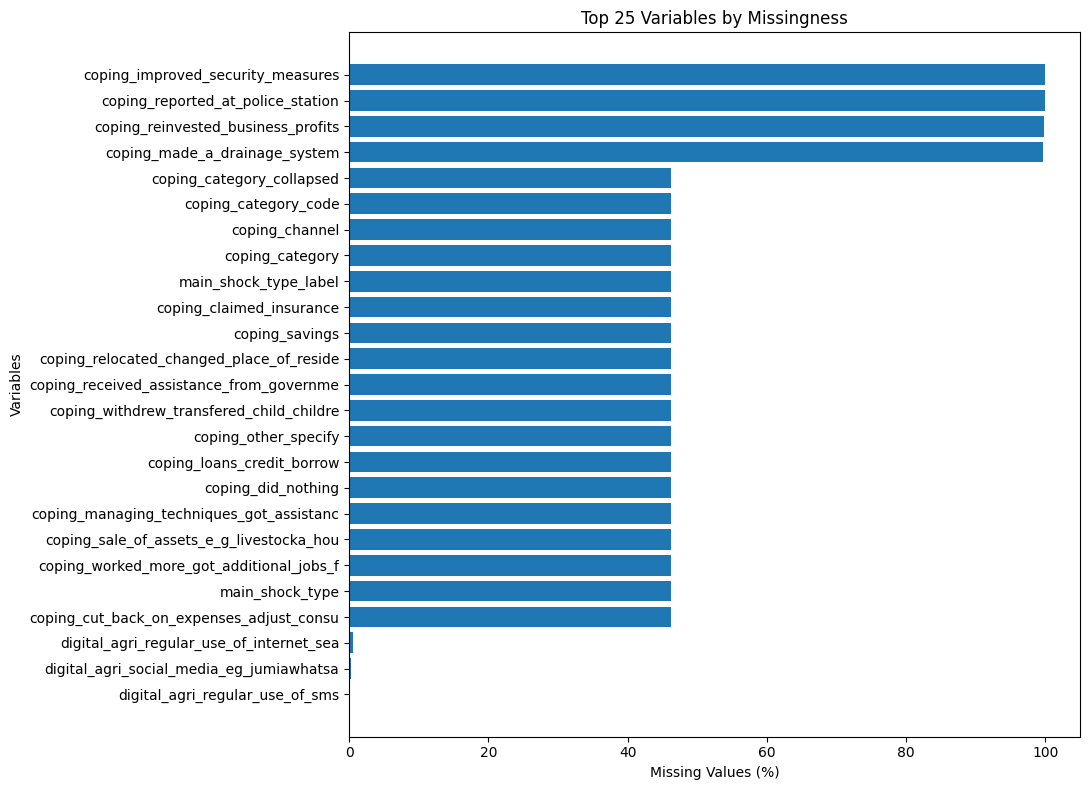

In [ ]:
# Select the 25 variables with the highest missingness
import matplotlib.pyplot as plt


top_missing = missing_summary.head(25).sort_values(
    by="Missing Percentage"
)

plt.figure(figsize=(11, 8))

plt.barh(
    top_missing["Variable"],
    top_missing["Missing Percentage"]
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Variables")
plt.title("Top 25 Variables by Missingness")

plt.tight_layout()
plt.show()

**Investigate missing coping outcomes against drought exposure**

We want to establish whether households with missing coping outcomes are concentrated among those who did not report drought exposure.

We will examine both the actual counts and the percentages within each drought exposure group.

In [ ]:
# Compare coping outcomes against drought exposure

coping_by_drought = pd.crosstab(
    df24["drought_exposed"],
    df24["coping_category_collapsed"].fillna("Missing outcome"),
    margins=True
)

print("Coping outcomes by drought exposure")

display(coping_by_drought)


# Calculate row percentages

coping_by_drought_percentage = pd.crosstab(
    df24["drought_exposed"],
    df24["coping_category_collapsed"].fillna("Missing outcome"),
    normalize="index"
) * 100

print("\nPercentage distribution within each drought exposure group")

display(coping_by_drought_percentage.round(2))

Coping outcomes by drought exposure


coping_category_collapsed,Missing outcome,did_nothing,formal_or_informal,personal,All
drought_exposed,,,,,
0,4515,579,1943,1167,8204
1,0,415,522,615,1552
All,4515,994,2465,1782,9756



Percentage distribution within each drought exposure group


coping_category_collapsed,Missing outcome,did_nothing,formal_or_informal,personal
drought_exposed,,,,
0,55.03,7.06,23.68,14.22
1,0.00,26.74,33.63,39.63


### Additional diagnostic: Missing outcomes and other shocks



In [ ]:
# Identify binary shock variables

shock_columns = [
    column for column in df24.columns
    if column.startswith("shock_")
]

print("Shock variables identified:")
print(shock_columns)


# Convert shock variables temporarily for inspection

shock_data = df24[shock_columns].apply(
    pd.to_numeric,
    errors="coerce"
)


# Identify households with reported shocks

any_shock = shock_data.eq(1).any(axis=1)

all_observed = shock_data.notna().all(axis=1)

no_shock = all_observed & shock_data.eq(0).all(axis=1)


# Classify shock reporting status

shock_status = pd.Series(
    "Incomplete shock information",
    index=df24.index
)

shock_status.loc[no_shock] = "No reported shocks"

shock_status.loc[any_shock] = "At least one reported shock"


# Identify coping outcome availability

outcome_status = df24[
    "coping_category_collapsed"
].isna().map({
    True: "Missing outcome",
    False: "Recorded outcome"
})


# Compare shock reporting and coping outcome availability

print("\nShock reporting against coping outcome availability")

display(
    pd.crosstab(
        shock_status,
        outcome_status,
        margins=True
    )
)

Shock variables identified:
['shock_child_birth', 'shock_major_sickness_health_problem_acci', 'shock_drought_loss', 'shock_high_rainfall_flooding_mudslide_li', 'shock_death_of_main_income_earner_family', 'shock_loss_or_damage_due_totheft_e_g_pro', 'shock_loss_of_a_job_or_a_source_of_incom', 'shock_lost_a_home_or_land_e_g_due_to_evi', 'shock_livestock_crop_failure_due_to_pest', 'shock_loss_or_damage_due_tofire_or_viole', 'shock_loss_or_damage_due_to_human_wildli', 'shock_loss_of_income_or_major_financial']

Shock reporting against coping outcome availability


coping_category_collapsed,Missing outcome,Recorded outcome,All
row_0,,,
At least one reported shock,7,5241,5248
Incomplete shock information,9,0,9
No reported shocks,4499,0,4499
All,4515,5241,9756


### Main shock type against coping outcome availability

In [ ]:
# Check whether a main shock type was recorded

main_shock_status = df24[
    "main_shock_type"
].notna().map({
    True: "Main shock recorded",
    False: "Main shock missing"
})


display(
    pd.crosstab(
        outcome_status,
        main_shock_status,
        margins=True
    )
)

main_shock_type,Main shock missing,Main shock recorded,All
coping_category_collapsed,,,
Missing outcome,4508,7,4515
Recorded outcome,0,5241,5241
All,4508,5248,9756


There are three important findings to document.
1. Missing coping outcomes are largely structural
The results show:
| Shock reporting status | Missing outcome | Recorded outcome |
|---|---:|---:|
| At least one reported shock | 7 | 5,241 |
| No reported shocks | 4,499 | 0 |
| Incomplete shock information | 9 | 0 |


    - The 4,499 households without reported shocks have no recorded coping outcome. This is consistent with the survey's shock-related question routing.

    - The remaining seven cases are a small exception. Importantly, none of the 1,552 drought-exposed households has a missing coping outcome.

    - We should therefore distinguish structural missingness from genuine item nonresponse during Data Preparation.

2. Our modelling population is supported by the available data

    - We have established that all 1,552 drought-exposed households have valid three-class coping outcomes.This gives us a clearly defined primary analytical population.

3. Sparse coping variables need special attention

    - The four extremely sparse variables will require further consideration during feature selection. We should not automatically treat their missing values as zeros.

## Univariate Exploratory Data Analysis

Exploratory Data Analysis is undertaken to understand the
distributions and characteristics of the variables available
for the study.

This section uses descriptive statistics and visualisations to
examine household demographics, agricultural characteristics,
farm portfolios, shock exposure and coping behaviour.

The analysis initially considers the full 2024 farming household
sample. Where relevant, particular attention will subsequently
be given to the drought-exposed population.

### Household Demographic Characteristics

We begin by examining the demographic characteristics of
the farming households.

The variables considered include household respondent age,
sex, education level, county and urban or rural residence.

The objective is to understand the composition and distribution
of the sample and identify any notable patterns that may be
relevant to differences in household coping behaviour.

The initial analysis uses unweighted sample counts and
percentages. Population-level estimates will require separate
consideration of the survey weights.

In [ ]:
# Descriptive statistics for respondent age

print("AGE DISTRIBUTION")

display(df24["age_years"].describe())

AGE DISTRIBUTION


,age_years
count,9756.000000
mean,44.973862
std,16.772235
min,16.000000
25%,32.000000
50%,42.000000
75%,57.000000
max,104.000000


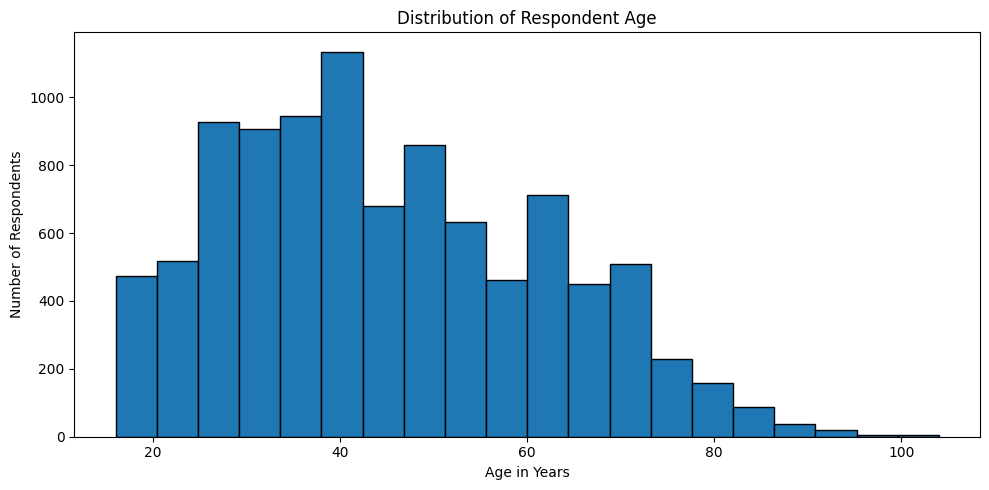

In [ ]:
# Visualise respondent age distribution

plt.figure(figsize=(10, 5))

plt.hist(
    df24["age_years"].dropna(),
    bins=20,
    edgecolor="black"
)

plt.xlabel("Age in Years")
plt.ylabel("Number of Respondents")
plt.title("Distribution of Respondent Age")

plt.tight_layout()
plt.show()

Examining categorical demographic variables

In [ ]:
# Categorical demographic variables

demographic_columns = [
    "sex",
    "education",
    "urban_rural",
    "county"
]

for column in demographic_columns:

    print("\n", column.upper())

    print("\nFrequency:")

    print(
        df24[column].value_counts(dropna=False)
    )

    print("\nPercentage distribution:")

    print(
        (df24[column].value_counts(normalize=True, dropna=False) * 100)
        .round(2)
    )


 SEX

Frequency:
sex
2    5494
1    4262
Name: count, dtype: int64

Percentage distribution:
sex
2    56.31
1    43.69
Name: proportion, dtype: float64

 EDUCATION

Frequency:
education
2    4336
3    2916
1    1454
4    1048
5       2
Name: count, dtype: int64

Percentage distribution:
education
2    44.44
3    29.89
1    14.90
4    10.74
5     0.02
Name: proportion, dtype: float64

 URBAN_RURAL

Frequency:
urban_rural
1    8286
2    1470
Name: count, dtype: int64

Percentage distribution:
urban_rural
1    84.93
2    15.07
Name: proportion, dtype: float64

 COUNTY

Frequency:
county
37    360
39    357
12    346
14    312
28    299
13    294
29    284
17    283
38    282
20    281
41    281
36    279
35    279
44    267
3     262
24    262
45    254
18    254
21    250
27    240
32    231
33    229
6     228
30    224
43    221
40    219
19    217
46    213
16    211
15    201
22    198
2     179
42    174
31    170
25    155
10    150
34    144
23    143
11     82
5      68
26     6

### Compare age distributions by drought exposure

Since our central research question concerns drought-related coping behaviour, it is useful to establish whether the age profile differs between exposed and non-exposed farming households.

In [ ]:
# Compare respondent age by drought exposure

age_comparison = df24.groupby("drought_exposed")["age_years"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(age_comparison)

,count,mean,median,std,min,max
drought_exposed,,,,,,
0,8204,45.196246,43.0,16.896159,16,104
1,1552,43.798325,41.0,16.055470,16,101


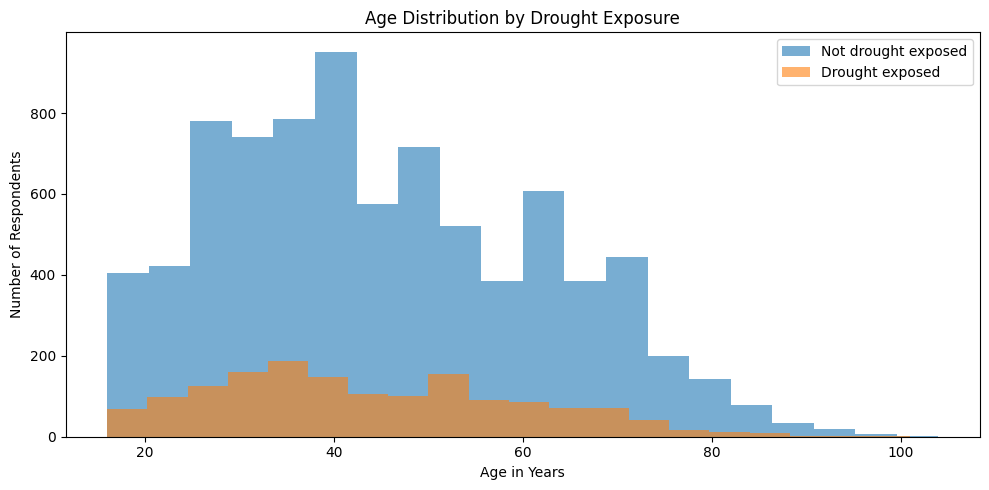

In [ ]:
# Compare age distributions by drought exposure

plt.figure(figsize=(10, 5))

plt.hist(
    df24.loc[df24["drought_exposed"] == 0, "age_years"],
    bins=20,
    alpha=0.6,
    label="Not drought exposed"
)

plt.hist(
    df24.loc[df24["drought_exposed"] == 1, "age_years"],
    bins=20,
    alpha=0.6,
    label="Drought exposed"
)

plt.xlabel("Age in Years")
plt.ylabel("Number of Respondents")
plt.title("Age Distribution by Drought Exposure")

plt.legend()
plt.tight_layout()
plt.show()

### 1. Age distribution
The dataset contains 9,756 respondents aged between 16 and 104 years.

| Statistic | Age |
|---|---:|
| Mean | 44.97 |
| Median | 42 |
| Standard deviation | 16.77 |
| 25th percentile | 32 |
| 75th percentile | 57 |
| Minimum | 16 |
| Maximum | 104 |


The mean being higher than the median suggests a positively skewed age distribution. Most respondents are concentrated between their late twenties and early sixties, with fewer observations at older ages.

The maximum age of 104 is worth flagging for subsequent outlier investigation. However, we should not automatically consider it an erroneous observation.

### 2. Age and drought exposure
| Measure | Not exposed | Exposed |
|---|---:|---:|
| Observations | 8,204 | 1,552 |
| Mean age | 45.20 | 43.80 |
| Median age | 43 | 41 |
| Standard deviation | 16.90 | 16.06 |

The age distributions overlap considerably. Drought-exposed respondents are slightly younger on average, but this is only a descriptive observation. We have not established whether the difference is statistically meaningful.

### 3. Other demographic characteristics
A few observations stand out:
- The sex variable has 56.31% of observations in category 2 and 43.69% in category 1.
- Education category 2 accounts for 44.44% of observations, followed by category 3 at 29.89%.
- Urban/rural category 1 accounts for 84.93% of the sample.
- The dataset covers all 47 county codes.
We should retain the numerical codes in our interpretation until we explicitly retrieve their corresponding value labels. We should not assume their meanings merely from their numerical values.

### Agricultural and Farm Characteristics

This subsection examines the agricultural characteristics of the
farming households, beginning with landholding size and ownership.

Land size is particularly important because it provides an indication
of the scale of agricultural activity undertaken by a household.
However, the dataset contains a separate variable indicating the
unit in which land size was reported.

We will therefore examine land size distributions separately by
reported measurement unit rather than treating all recorded values
as directly comparable.

We will also examine the different land ownership arrangements.
Since households may report multiple ownership arrangements,
these variables will be treated as separate indicators rather
than mutually exclusive categories.

The findings will help establish the characteristics of the
agricultural sample and inform the subsequent farm segmentation

In [ ]:
# Inspect land size variables

print("LAND SIZE DATA TYPES")

print(df24[["land_size", "land_size_unit"]].dtypes)


print("\nLAND SIZE UNIT DISTRIBUTION")

display(
    df24["land_size_unit"]
    .value_counts(dropna=False)
    .rename_axis("Land Size Unit")
    .reset_index(name="Households")
)

LAND SIZE DATA TYPES
land_size         float64
land_size_unit     object
dtype: object

LAND SIZE UNIT DISTRIBUTION


,Land Size Unit,Households
0,1.0,8917
1,5.0,501
2,2.0,153
3,3.0,137
4,4.0,32
5,NaN,16


**Descriptive statistics for land size by measurement unit**

Rather than calculating one mean across potentially different units, we will examine each measurement category separately.

In [ ]:
# Prepare a temporary dataset for land size inspection

land_data = df24[["land_size", "land_size_unit"]].copy()

land_data["land_size_numeric"] = pd.to_numeric(
    land_data["land_size"],
    errors="coerce"
)


# Calculate descriptive statistics by measurement unit

land_size_summary = land_data.groupby(
    "land_size_unit",
    dropna=False
)["land_size_numeric"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.95]
)

display(land_size_summary)

,count,mean,std,min,25%,50%,75%,95%,max
land_size_unit,,,,,,,,,
1.0,8917.0,2.998063,13.342898,0.01,0.5,1.0,2.0,6.0,500.0
2.0,153.0,19.909542,74.077228,0.06,1.0,2.0,4.0,100.0,500.0
3.0,137.0,268.270803,510.878051,0.10,24.0,100.0,500.0,800.0,5000.0
4.0,32.0,1036.379688,2828.161367,0.25,1.0,5.0,98.0,8900.0,10500.0
5.0,501.0,96.895709,27.771887,0.25,98.0,98.0,98.0,98.0,350.0
NaN,16.0,91.893750,24.425000,0.30,98.0,98.0,98.0,98.0,98.0


In [ ]:
# Identify land ownership variables

ownership_columns = [
    "land_ownership_own_under_your_name",
    "land_ownership_own_jointly_with_spouse",
    "land_ownership_own_jointly_with_someone",
    "land_ownership_lease_rent_you_dont_own",
    "land_ownership_community_public_owned_e",
    "land_ownership_family_owned_e_g_inherite"
]


# Calculate ownership frequencies

ownership_results = []

for column in ownership_columns:

    values = pd.to_numeric(
        df24[column],
        errors="coerce"
    )

    valid_values = values.notna().sum()
    yes_count = (values == 1).sum()

    ownership_results.append({
        "Ownership Arrangement": column,
        "Yes": yes_count,
        "No": (values == 0).sum(),
        "Missing": values.isna().sum(),
        "Percentage Yes": round(
            yes_count / valid_values * 100, 2
        ) if valid_values > 0 else 0
    })


ownership_summary = pd.DataFrame(ownership_results)

display(ownership_summary)

,Ownership Arrangement,Yes,No,Missing,Percentage Yes
0,land_ownership_own_under_your_name,1949,7805,2,19.98
1,land_ownership_own_jointly_with_spouse,707,9047,2,7.25
2,land_ownership_own_jointly_with_someone,63,9691,2,0.65
3,land_ownership_lease_rent_you_dont_own,887,8867,2,9.09
4,land_ownership_community_public_owned_e,722,9032,2,7.40
5,land_ownership_family_owned_e_g_inherite,5690,4064,2,58.34


- Interpretation of land size

    - The first thing to notice is that land size is reported using five different measurement codes.

| Unit code | Households | Mean reported size | Median |
|---|---:|---:|---:|
| 1 | 8,917 | 3.00 | 1.00 |
| 2 | 153 | 19.91 | 2.00 |
| 3 | 137 | 268.27 | 100.00 |
| 4 | 32 | 1,036.38 | 5.00 |
| 5 | 501 | 96.90 | 98.00 |
| Missing | 16 | 91.89 | 98.00 |

There are several things worth noting.

First, we cannot interpret the overall land size mean of these households without accounting for the different measurement units.

Second, unit 5 is particularly unusual. Its median is 98, and its 75th and 95th percentiles are also 98. This suggests a possible special response code or unusual reporting pattern that needs investigation.

Third, unit 4 has a maximum reported land size of 10,500. Although this could represent a genuinely large landholding, we should investigate it once we establish the unit.

In [ ]:
# Examine the original value labels for land size and its unit

print("LAND SIZE UNIT LABELS")

print(value_labels_24.get("Q1i", "No value labels available"))


print("\nLAND SIZE LABELS")

print(value_labels_24.get("Q1", "No value labels available"))

LAND SIZE UNIT LABELS
{1: 'Acres', 2: 'Hectares', 3: 'Square metres', 4: 'Square feet', 5: 'Community land'}

LAND SIZE LABELS
{98: '"Don’t know (DO NOT READ OUT)"', 99: '"Refused to Answer  (DO NOT READ OUT)"'}


In [ ]:
# Examine the most frequently reported land sizes within each unit

for unit in sorted(df24["land_size_unit"].dropna().unique()):

    print("\nLand size unit:", unit)

    print(
        df24.loc[
            df24["land_size_unit"] == unit,
            "land_size"
        ].value_counts().head(10)
    )


Land size unit: 1
land_size
1.000    1974
0.500    1581
2.000    1212
0.250     885
3.000     538
1.500     441
5.000     255
4.000     253
0.750     215
0.125     209
Name: count, dtype: int64

Land size unit: 2
land_size
1.00      42
2.00      19
3.00      13
5.00       8
0.50       8
0.25       8
4.00       7
100.00     4
1.50       4
2.50       3
Name: count, dtype: int64

Land size unit: 3
land_size
100.00    43
500.00    25
1.00      10
400.00     7
200.00     5
20.00      5
0.25       4
800.00     3
10.00      3
50.00      2
Name: count, dtype: int64

Land size unit: 4
land_size
1.0        11
98.0        2
3.0         2
2000.0      2
7.0         1
48.0        1
100.0       1
8000.0      1
10000.0     1
10500.0     1
Name: count, dtype: int64

Land size unit: 5
land_size
98.0     474
2.0        5
99.0       3
5.0        3
1.0        2
0.5        2
350.0      2
300.0      2
3.0        2
100.0      2
Name: count, dtype: int64


#### Investigating special land size codes

In [ ]:
# Identify special response codes

special_land_codes = [98, 99]

special_land = df24[
    df24["land_size"].isin(special_land_codes)
]

print("SPECIAL LAND SIZE RESPONSES")

display(
    special_land.groupby(
        ["land_size_unit", "land_size"]
    ).size().reset_index(name="Households")
)


# Examine community land observations

print("\nCOMMUNITY LAND OBSERVATIONS")

community_land = df24[
    df24["land_size_unit"] == 5
]

display(
    community_land["land_size"].value_counts(dropna=False)
)

SPECIAL LAND SIZE RESPONSES


,land_size_unit,land_size,Households
0,1,98.0,75
1,1,99.0,7
2,3,98.0,1
3,3,99.0,1
4,4,98.0,2
5,5,98.0,474
6,5,99.0,3



COMMUNITY LAND OBSERVATIONS


,count
land_size,
98.00,474
2.00,5
99.00,3
5.00,3
1.00,2
0.50,2
350.00,2
300.00,2
3.00,2


In [ ]:
# Retain conventional measurement units

land_valid = land_data[
    land_data["land_size_unit"].isin([1, 2, 3, 4])
    & ~land_data["land_size_numeric"].isin([98, 99])
].copy()


# Descriptive statistics by measurement unit

land_clean_summary = land_valid.groupby(
    "land_size_unit"
)["land_size_numeric"].describe()

display(land_clean_summary)

,count,mean,std,min,25%,50%,75%,max
land_size_unit,,,,,,,,
1,8835.0,2.115532,9.745709,0.01,0.5,1.0,2.0,500.0
2,153.0,19.909542,74.077228,0.06,1.0,2.0,4.0,500.0
3,135.0,270.785926,514.252169,0.10,22.5,100.0,500.0,5000.0
4,30.0,1098.938333,2912.960798,0.25,1.0,3.0,46.0,10500.0


In [ ]:
# Investigate community land observations with reported numerical values

community_land_valid = df24[
    (df24["land_size_unit"] == 5) &
    (~df24["land_size"].isin([98, 99]))
]

print("Community land observations with numerical values:")
print("Number of observations:", len(community_land_valid))

display(
    community_land_valid[
        ["land_size_unit", "land_size"]
    ].sort_values("land_size")
)


# Investigate observations with missing land measurement units

missing_unit = df24[
    df24["land_size_unit"].isna()
]

print("\nObservations with missing measurement units:")
print("Number of observations:", len(missing_unit))

display(
    missing_unit[
        ["land_size_unit", "land_size"]
    ]
)

Community land observations with numerical values:
Number of observations: 24


,land_size_unit,land_size
1996,5,0.25
9780,5,0.50
12556,5,0.50
12055,5,1.00
12907,5,1.00
9775,5,1.50
10068,5,2.00
11360,5,2.00
12217,5,2.00
12019,5,2.00



Observations with missing measurement units:
Number of observations: 16


,land_size_unit,land_size
14548,NaN,0.3
16248,NaN,98.0
16328,NaN,98.0
16340,NaN,98.0
16367,NaN,98.0
16520,NaN,98.0
16564,NaN,98.0
16621,NaN,98.0
16834,NaN,98.0
16869,NaN,98.0


There are 24 observations with numerical land sizes under the community land category.

Their reported values range from 0.25 to 350. However, because community land is not a conventional measurement unit, we cannot establish whether these values are directly comparable with measurements in acres, hectares or other units.

We will flag these 24 observations for further investigation.

#### Missing measurement units

There are 16 observations with missing measurement units.
- 15 have a land size of 98, representing respondents who did not know their land size.
- One has a reported land size of 0.3 but no measurement unit.
The last observation cannot be converted reliably without further information.

#### Decisions carried forward

During Data Preparation, we will need to:
1. Convert conventional land measurements into a common unit, preferably hectares.
2. Treat 98 and 99 as special response codes rather than actual land sizes.
3. Investigate the 24 community land observations.
4. Retain the 0.3 observation with missing unit for further consideration.
5. Investigate extreme landholding values after unit conversion.
We will not perform these operations yet.

#### Initial Findings

The land size analysis identified five reported measurement
categories. These include acres, hectares, square metres,
square feet and community land.

The analysis also revealed special response codes within the
land size variable. Code 98 represents respondents who did
not know their land size, while code 99 represents respondents
who refused to answer.

After excluding these special responses and considering the
four conventional measurement units separately, considerable
variation remains within each group.

Acres represent the most frequently reported measurement unit,
accounting for 8,835 valid observations.

The community land category contains predominantly unknown
land size responses. The remaining numerical entries require
further investigation because community land is not a
conventional measurement unit.

These findings demonstrate that land size requires additional
processing before it can be used as a continuous feature in
farm segmentation. Measurement conversion, treatment of
special response codes and investigation of extreme values
will be addressed during Data Preparation.

### Crop and Livestock Portfolio Composition

This subsection examines the agricultural portfolios of the
farming households using the grouped crop and livestock
indicators created during the initial data preparation.

The original crop and livestock responses were consolidated
into nine functional groups to simplify the representation
of agricultural activities.

These groups include cereals, legumes, roots and tubers,
horticulture, cash crops, dairy livestock, other livestock,
poultry and other agricultural activities.

The analysis examines the prevalence of each group, the
number of crop and livestock types reported by households
and the distribution of agricultural portfolio diversity.

This is particularly important because crop and livestock
composition will form a major component of the subsequent
farm segmentation exercise.

In [ ]:
# Define the nine agricultural portfolio groups

portfolio_group_cols = [
    "has_cash_crops",
    "has_cereals",
    "has_dairy_livestock",
    "has_horticulture",
    "has_legumes",
    "has_other_agri",
    "has_other_livestock",
    "has_poultry",
    "has_roots_tubers"
]

# Check which variables are available

available_groups = [
    col for col in portfolio_group_cols
    if col in df24.columns
]

missing_groups = [
    col for col in portfolio_group_cols
    if col not in df24.columns
]

print("Available portfolio groups:", len(available_groups))
print("Missing portfolio groups:", missing_groups)

print("\nAvailable variables:")
print(available_groups)

Available portfolio groups: 9
Missing portfolio groups: []

Available variables:
['has_cash_crops', 'has_cereals', 'has_dairy_livestock', 'has_horticulture', 'has_legumes', 'has_other_agri', 'has_other_livestock', 'has_poultry', 'has_roots_tubers']


#### Examining participation across agricultural groups

In this section, we aim to establish how many households report participating in each agricultural group.

In [ ]:
# Calculate agricultural group participation

portfolio_summary = pd.DataFrame({
    "Agricultural Group": available_groups,
    "Households": [
        (pd.to_numeric(df24[col], errors="coerce") == 1).sum()
        for col in available_groups
    ],
    "Percentage": [
        round(
            (pd.to_numeric(df24[col], errors="coerce") == 1).mean() * 100,
            2
        )
        for col in available_groups
    ]
})

portfolio_summary = portfolio_summary.sort_values(
    by="Households",
    ascending=False
).reset_index(drop=True)

display(portfolio_summary)

,Agricultural Group,Households,Percentage
0,has_cereals,7456,76.42
1,has_legumes,4880,50.02
2,has_cash_crops,2745,28.14
3,has_other_livestock,2174,22.28
4,has_roots_tubers,2097,21.49
5,has_horticulture,1550,15.89
6,has_dairy_livestock,1196,12.26
7,has_poultry,888,9.10
8,has_other_agri,26,0.27


Visualising agricultural group participation

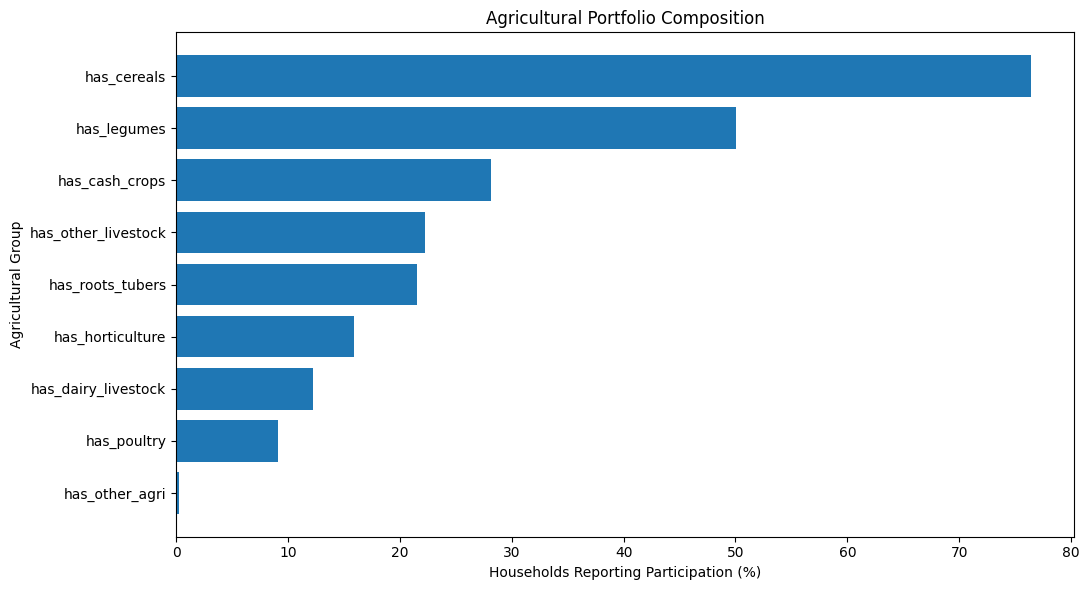

In [ ]:
# Plot agricultural group participation

portfolio_plot = portfolio_summary.sort_values(
    by="Percentage"
)

plt.figure(figsize=(11, 6))

plt.barh(
    portfolio_plot["Agricultural Group"],
    portfolio_plot["Percentage"]
)

plt.xlabel("Households Reporting Participation (%)")
plt.ylabel("Agricultural Group")
plt.title("Agricultural Portfolio Composition")

plt.tight_layout()
plt.show()

#### Examining the crop and livestock counts
The numerical variables

- n_crop_types
- n_livestock_types

Count the individual crop and livestock items reported by each household, rather than simply counting the nine broader groups.

Let's examine their distributions.

In [ ]:
# Descriptive statistics for crop and livestock counts

portfolio_count_columns = [
    "n_crop_types",
    "n_livestock_types"
]

display(
    df24[portfolio_count_columns].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
)

,n_crop_types,n_livestock_types
count,9756.000000,9756.000000
mean,2.250000,0.540078
std,1.276096,0.853571
min,0.000000,0.000000
25%,1.000000,0.000000
50%,2.000000,0.000000
75%,3.000000,1.000000
90%,4.000000,2.000000
95%,4.000000,2.000000
max,5.000000,5.000000


In [ ]:
# Frequency distribution of crop types

print("NUMBER OF CROP TYPES")

display(
    df24["n_crop_types"]
    .value_counts()
    .sort_index()
    .rename_axis("Number of Crop Types")
    .reset_index(name="Households")
)


# Frequency distribution of livestock types

print("NUMBER OF LIVESTOCK TYPES")

display(
    df24["n_livestock_types"]
    .value_counts()
    .sort_index()
    .rename_axis("Number of Livestock Types")
    .reset_index(name="Households")
)

NUMBER OF CROP TYPES


,Number of Crop Types,Households
0,0,876
1,1,1843
2,2,3075
3,3,2375
4,4,1102
5,5,485


NUMBER OF LIVESTOCK TYPES


,Number of Livestock Types,Households
0,0,6314
1,1,2042
2,2,1045
3,3,299
4,4,40
5,5,16


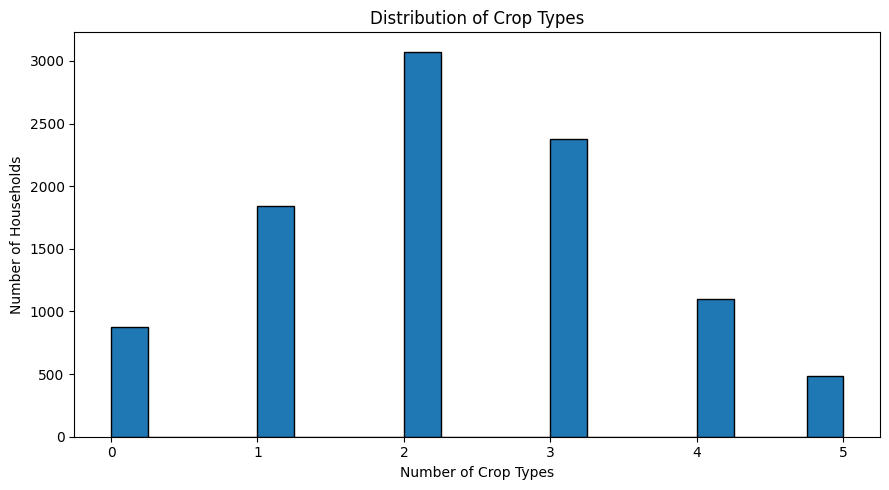

In [ ]:
# Distribution of crop types

plt.figure(figsize=(9, 5))

plt.hist(
    df24["n_crop_types"],
    bins=20,
    edgecolor="black"
)

plt.xlabel("Number of Crop Types")
plt.ylabel("Number of Households")
plt.title("Distribution of Crop Types")

plt.tight_layout()
plt.show()

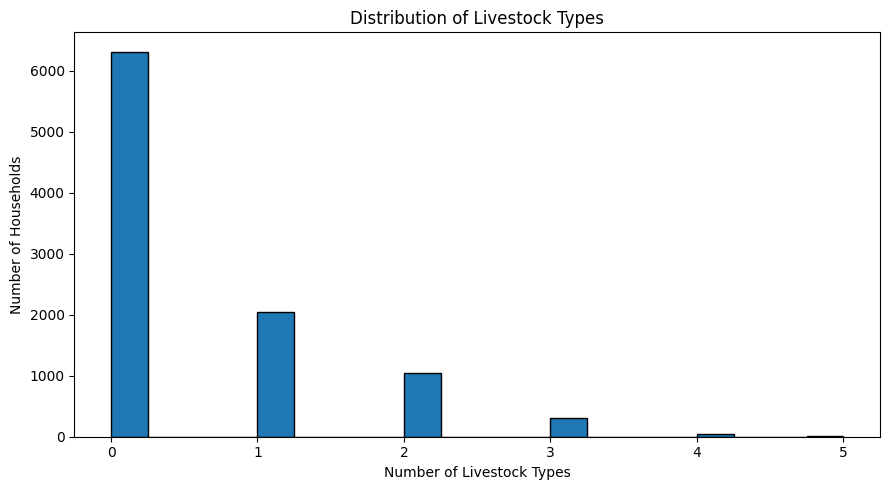

In [ ]:
# Distribution of livestock types

plt.figure(figsize=(9, 5))

plt.hist(
    df24["n_livestock_types"],
    bins=20,
    edgecolor="black"
)

plt.xlabel("Number of Livestock Types")
plt.ylabel("Number of Households")
plt.title("Distribution of Livestock Types")

plt.tight_layout()
plt.show()

In [ ]:
# Count the number of agricultural groups represented per household

portfolio_group_count = df24[available_groups].sum(axis=1)

# Calculate the expected logarithm of group richness

expected_diversity = np.where(
    portfolio_group_count > 0,
    np.log(portfolio_group_count),
    0
)

# Compare with the existing diversity indicator

diversity_difference = (
    df24["shannon_diversity"] - expected_diversity
).abs()

print(
    "Maximum difference:",
    diversity_difference.max()
)

print("\nDistribution of agricultural group counts:")

display(
    portfolio_group_count
    .value_counts()
    .sort_index()
    .rename_axis("Number of Agricultural Groups")
    .reset_index(name="Households")
)

Maximum difference: 2.220446049250313e-16

Distribution of agricultural group counts:


/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,Number of Agricultural Groups,Households
0,0,32
1,1,2353
2,2,3363
3,3,2427
4,4,1253
5,5,328


#### Initial Findings

The agricultural portfolio analysis reveals considerable variation
in the crop and livestock activities undertaken by the farming
households.

Cereal production is the most frequently represented agricultural
group, followed by legumes. Livestock participation is less
widespread, with approximately 64.72% of households having zero
recorded livestock types.

The average household reports approximately 2.25 crop types and
0.54 livestock types. Most households participate in two or three
of the nine broad agricultural groups.

The analysis also identified a highly sparsely represented
agricultural group, has_other_agri, which contains only 26
households. Its contribution to subsequent segmentation will
require further consideration.

The existing shannon_diversity indicator was also examined.
The diagnostic established that it represents the logarithm of
the number of agricultural groups reported by each household.
It therefore captures portfolio richness rather than conventional
Shannon diversity based on relative abundance.

These findings support the use of crop and livestock composition
as important dimensions of farm segmentation. However, the
distribution of livestock indicators, sparse categories and
potentially redundant features will need consideration during
Data Preparation.

### Drought and Other Shock Exposure

This subsection examines the distribution of reported household
and agricultural shocks within the 2024 farming household sample.

Particular attention is given to drought exposure because it
defines the primary population for the coping behaviour analysis.

Other reported shocks are also examined to establish whether
drought exposure occurs independently or alongside other
household and agricultural challenges.

The analysis considers the frequency of individual shock types,
the distribution of reported main shocks and the extent to which
households experience multiple shocks.

These findings will help establish the characteristics of
the population used in the subsequent coping behaviour analysis.

In [ ]:
# Examine individual shock exposure

shock_data = df24[shock_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

shock_summary = pd.DataFrame({
    "Shock": shock_columns,
    "Valid Responses": shock_data.notna().sum().values,
    "Missing": shock_data.isna().sum().values,
    "Households Exposed": shock_data.eq(1).sum().values
})

shock_summary["Percentage Exposed"] = (
    shock_summary["Households Exposed"] /
    shock_summary["Valid Responses"] * 100
).round(2)

shock_summary = shock_summary.sort_values(
    by="Households Exposed",
    ascending=False
).reset_index(drop=True)

display(shock_summary)

,Shock,Valid Responses,Missing,Households Exposed,Percentage Exposed
0,shock_major_sickness_health_problem_acci,9747,9,2282,23.41
1,shock_livestock_crop_failure_due_to_pest,9747,9,1816,18.63
2,shock_high_rainfall_flooding_mudslide_li,9747,9,1573,16.14
3,shock_drought_loss,9747,9,1552,15.92
4,shock_death_of_main_income_earner_family,9747,9,796,8.17
5,shock_loss_or_damage_due_totheft_e_g_pro,9747,9,641,6.58
6,shock_loss_of_a_job_or_a_source_of_incom,9747,9,453,4.65
7,shock_child_birth,9747,9,418,4.29
8,shock_loss_or_damage_due_to_human_wildli,9747,9,242,2.48
9,shock_loss_of_income_or_major_financial,9747,9,202,2.07


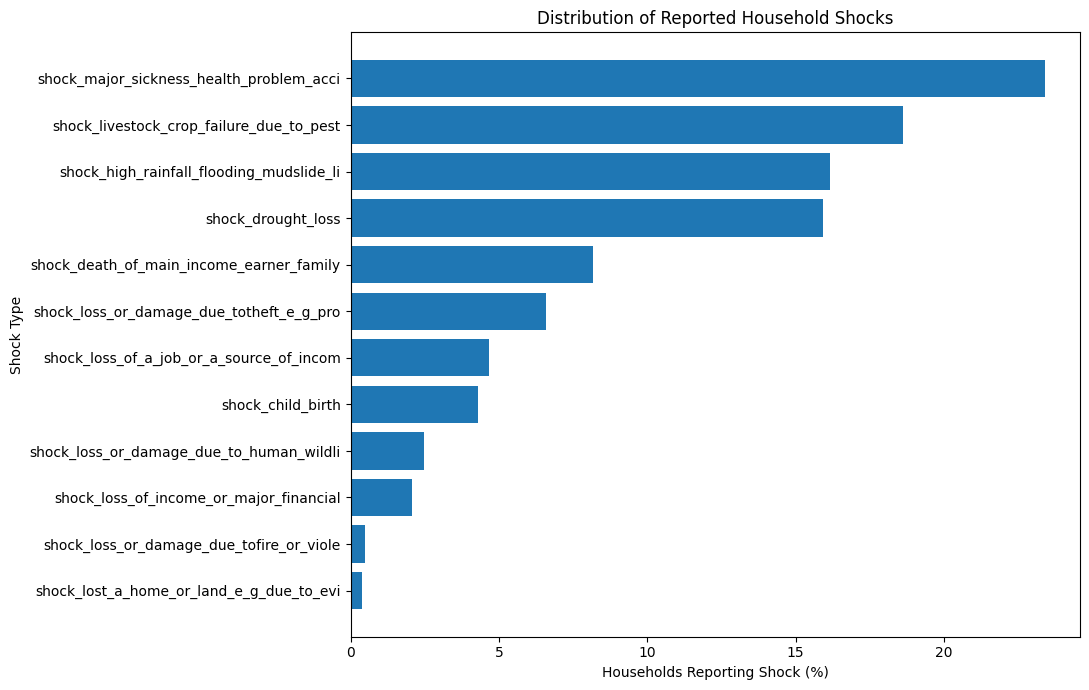

In [ ]:
# Visualise the prevalence of reported shocks

shock_plot = shock_summary.sort_values(
    by="Percentage Exposed"
)

plt.figure(figsize=(11, 7))

plt.barh(
    shock_plot["Shock"],
    shock_plot["Percentage Exposed"]
)

plt.xlabel("Households Reporting Shock (%)")
plt.ylabel("Shock Type")
plt.title("Distribution of Reported Household Shocks")

plt.tight_layout()
plt.show()

#### Examine drought exposure indicators

We have three potentially relevant variables:
- drought_exposed
- shock_drought_loss
- farm_reported_drought_challenge

Here, we establish how they relate to one another rather than assuming they measure exactly the same thing.

In [ ]:
# Compare drought exposure indicators

drought_variables = [
    "drought_exposed",
    "shock_drought_loss",
    "farm_reported_drought_challenge"
]

for column in drought_variables:

    print("\n", column.upper())

    print(
        df24[column].value_counts(dropna=False)
    )


 DROUGHT_EXPOSED
drought_exposed
0    8204
1    1552
Name: count, dtype: int64

 SHOCK_DROUGHT_LOSS
shock_drought_loss
0      8195
1      1552
NaN       9
Name: count, dtype: int64

 FARM_REPORTED_DROUGHT_CHALLENGE
farm_reported_drought_challenge
0      6401
1      3351
NaN       4
Name: count, dtype: int64


Check consistency between drought indicators

In [ ]:
# Compare the prepared drought exposure indicator
# with the original shock and farm challenge indicators

for column in [
    "shock_drought_loss",
    "farm_reported_drought_challenge"
]:

    comparison = pd.to_numeric(
        df24[column],
        errors="coerce"
    )

    print("\nComparison with:", column)

    display(
        pd.crosstab(
            df24["drought_exposed"],
            comparison.fillna("Missing"),
            margins=True
        )
    )


Comparison with: shock_drought_loss


shock_drought_loss,0.0,1.0,Missing,All
drought_exposed,,,,
0,8195,0,9,8204
1,0,1552,0,1552
All,8195,1552,9,9756



Comparison with: farm_reported_drought_challenge


farm_reported_drought_challenge,0.0,1.0,Missing,All
drought_exposed,,,,
0,5983,2217,4,8204
1,418,1134,0,1552
All,6401,3351,4,9756


In [ ]:
# Examine the distribution of main reported shocks

main_shock_summary = df24[
    "main_shock_type_label"
].value_counts(dropna=False).reset_index()

main_shock_summary.columns = [
    "Main Shock",
    "Households"
]

main_shock_summary["Percentage"] = (
    main_shock_summary["Households"] /
    len(df24) * 100
).round(2)

display(main_shock_summary)

,Main Shock,Households,Percentage
0,NaN,4508,46.21
1,Major sickness/health problem/accident injury,1616,16.56
2,Loss or damage due to drought,778,7.97
3,High rainfall/flooding/mudslide/lightning,765,7.84
4,Livestock/crop failure due to pest and diseases,761,7.80
5,Death of main income earner/family member,489,5.01
6,Child birth,235,2.41
7,Loss of a job or a source of income or a wage cut,209,2.14
8,"Loss or damage due to theft(e.g property, asse...",183,1.88
9,Loss of income or major financial expenses due...,107,1.10


#### Examining the number of different shocks experienced

We aim to understand whether households typically experience one shock or multiple shocks.

In [ ]:
# Count reported shocks for each household

shock_count = shock_data.eq(1).sum(axis=1)

# Exclude households with incomplete shock information

shock_count = shock_count.where(
    shock_data.notna().all(axis=1)
)

print("Distribution of reported shock counts:")

display(
    shock_count.value_counts(dropna=False)
    .sort_index()
    .rename_axis("Number of Shocks")
    .reset_index(name="Households")
)

Distribution of reported shock counts:


,Number of Shocks,Households
0,0.0,4499
1,1.0,2690
2,2.0,1296
3,3.0,708
4,4.0,275
5,5.0,171
6,6.0,69
7,7.0,27
8,8.0,9
9,9.0,3


#### Additional diagnostic: Drought as the main shock

Investigating how the 1,552 drought-exposed households are distributed according to their reported main shock by comparing drought exposure with main shock type

In [ ]:
# Compare drought exposure with the reported main shock

drought_main_comparison = pd.crosstab(
    df24["drought_exposed"],
    df24["main_shock_type_label"],
    margins=True
)

display(drought_main_comparison)

main_shock_type_label,Child birth,Death of main income earner/family member,High rainfall/flooding/mudslide/lightning,Livestock/crop failure due to pest and diseases,Loss of a job or a source of income or a wage cut,Loss of income or major financial expenses due to taking on care for someone els,Loss or damage due to drought,Loss or damage due to fire or violence including political violence,Loss or damage due to human wildlife conflict,"Loss or damage due to theft(e.g property, assets, business etc","Lost a home or land (e.g. due to eviction, demolitions or land seizure)",Major sickness/health problem/accident injury,All
drought_exposed,,,,,,,,,,,,,
0,212,389,638,609,174,94,0,10,48,138,6,1378,3696
1,23,100,127,152,35,13,778,11,25,45,5,238,1552
All,235,489,765,761,209,107,778,21,73,183,11,1616,5248


We then examine main shock types among drought-exposed households

In [ ]:
# Filter households reporting drought-related losses

drought_households = df24[
    df24["drought_exposed"] == 1
].copy()


# Examine their reported main shock types

print("Main shock types among drought-exposed households:")

display(
    drought_households["main_shock_type_label"]
    .value_counts(dropna=False)
    .rename_axis("Main Shock")
    .reset_index(name="Households")
)

Main shock types among drought-exposed households:


,Main Shock,Households
0,Loss or damage due to drought,778
1,Major sickness/health problem/accident injury,238
2,Livestock/crop failure due to pest and diseases,152
3,High rainfall/flooding/mudslide/lightning,127
4,Death of main income earner/family member,100
5,"Loss or damage due to theft(e.g property, asse...",45
6,Loss of a job or a source of income or a wage cut,35
7,Loss or damage due to human wildlife conflict,25
8,Child birth,23
9,Loss of income or major financial expenses due...,13


#### Comparing coping categories by main shock

To understand the coping responses among households that identified drought as their main shock, we compare with those that reported drought but identified another event as their main shock.

In [ ]:
# Identify households whose main shock was drought

drought_main = (
    df24["main_shock_type_label"]
    .astype("string")
    .str.contains("drought", case=False, na=False)
)


# Compare main shock groups within drought-exposed households

drought_response_comparison = pd.crosstab(
    drought_main[drought_households.index],
    drought_households["coping_category_collapsed"],
    margins=True
)

display(drought_response_comparison)

coping_category_collapsed,did_nothing,formal_or_informal,personal,All
main_shock_type_label,,,,
False,147,364,263,774
True,268,158,352,778
All,415,522,615,1552


Examining the three-class distribution for drought as the main shock

In [ ]:
# Isolate households identifying drought as their main shock

drought_main_sample = df24[
    (df24["drought_exposed"] == 1) &
    (df24["main_shock_type_label"].astype("string")
     .str.contains("drought", case=False, na=False))
].copy()


print("Households with drought as their main shock:")
print(len(drought_main_sample))

print("\nThree-class coping distribution:")

display(
    drought_main_sample["coping_category_collapsed"]
    .value_counts()
    .to_frame("Households")
)

print("\nPercentage distribution:")

display(
    (
        drought_main_sample["coping_category_collapsed"]
        .value_counts(normalize=True) * 100
    ).round(2).to_frame("Percentage")
)

Households with drought as their main shock:
778

Three-class coping distribution:


,Households
coping_category_collapsed,
personal,352
did_nothing,268
formal_or_informal,158



Percentage distribution:


,Percentage
coping_category_collapsed,
personal,45.24
did_nothing,34.45
formal_or_informal,20.31


In [ ]:
# Examine the original resilience classification

print("Original variable description:")

print(
    meta_labels_24.get("Classification_A_Resilience")
)

print("\nOriginal value labels:")

print(
    value_labels_24.get("Classification_A_Resilience")
)

Original variable description:
Device used for Resilience

Original value labels:
{1: 'Formal', 2: 'Informal', 3: 'Personal', 4: 'Did Nothing'}


#### We compare all four classifications across main shock groups

We previously examined the collapsed three-class outcome. Now we examine the original four-class outcome.

In [ ]:
# Create the two main shock groups

drought_households = df24[
    df24["drought_exposed"] == 1
].copy()

drought_households["main_shock_group"] = np.where(
    drought_households["main_shock_type_label"]
    .astype("string")
    .str.contains("drought", case=False, na=False),
    "Drought as main shock",
    "Other main shock"
)


# Compare the original four coping classifications

print("Classification counts:")

display(
    pd.crosstab(
        drought_households["main_shock_group"],
        drought_households["coping_category"],
        margins=True
    )
)


print("\nPercentage distribution:")

display(
    (
        pd.crosstab(
            drought_households["main_shock_group"],
            drought_households["coping_category"],
            normalize="index"
        ) * 100
    ).round(2)
)

Classification counts:


coping_category,did_nothing,formal,informal,personal,All
main_shock_group,,,,,
Drought as main shock,268,27,131,352,778
Other main shock,147,48,316,263,774
All,415,75,447,615,1552



Percentage distribution:


coping_category,did_nothing,formal,informal,personal
main_shock_group,,,,
Drought as main shock,34.45,3.47,16.84,45.24
Other main shock,18.99,6.20,40.83,33.98


### Coping and Resilience Behaviour Analysis

This subsection examines the resilience classifications and
individual coping actions reported by drought-exposed farming
households.

The original survey classification identifies four resilience
mechanisms: formal, informal, personal and doing nothing.

The analysis first examines the distribution of these
classifications before investigating the individual actions
recorded in the survey.

The objective is to understand the types of resilience
mechanisms represented in the dataset and establish how
frequently different actions are reported.

The original four-category classification will be retained
for analysis, while the collapsed three-category version
will also be examined as an alternative representation.

The 2024 drought-exposed sample of 1,552 households will
form the primary population for this analysis.

In [ ]:
# Select drought-exposed households

drought_sample = df24[
    df24["drought_exposed"] == 1
].copy()

print("Primary analytical population")

print("Number of households:", len(drought_sample))

print("\nOriginal resilience classification")

display(
    drought_sample["coping_category"]
    .value_counts()
    .to_frame("Households")
)

print("\nCollapsed resilience classification")

display(
    drought_sample["coping_category_collapsed"]
    .value_counts()
    .to_frame("Households")
)

Primary analytical population
Number of households: 1552

Original resilience classification


,Households
coping_category,
personal,615
informal,447
did_nothing,415
formal,75



Collapsed resilience classification


,Households
coping_category_collapsed,
personal,615
formal_or_informal,522
did_nothing,415


In [ ]:
# Calculate class frequencies and percentages

coping_summary = pd.DataFrame({
    "Households": drought_sample[
        "coping_category"
    ].value_counts()
})

coping_summary["Percentage"] = (
    coping_summary["Households"] /
    len(drought_sample) * 100
).round(2)

display(coping_summary)

,Households,Percentage
coping_category,,
personal,615,39.63
informal,447,28.80
did_nothing,415,26.74
formal,75,4.83


In [ ]:
# Identify individual coping action variables

coping_action_columns = [
    column for column in df24.columns
    if column.startswith("coping_")
    and column not in [
        "coping_category",
        "coping_category_code",
        "coping_category_collapsed",
        "coping_channel"
    ]
]

print("Number of coping action variables:", len(coping_action_columns))

print("\nVariables identified:")

for column in coping_action_columns:
    print(column)

Number of coping action variables: 16

Variables identified:
coping_worked_more_got_additional_jobs_f
coping_managing_techniques_got_assistanc
coping_sale_of_assets_e_g_livestocka_hou
coping_cut_back_on_expenses_adjust_consu
coping_loans_credit_borrow
coping_savings
coping_relocated_changed_place_of_reside
coping_claimed_insurance
coping_withdrew_transfered_child_childre
coping_received_assistance_from_governme
coping_did_nothing
coping_other_specify
coping_made_a_drainage_system
coping_improved_security_measures
coping_reported_at_police_station
coping_reinvested_business_profits


In [ ]:
# Calculate the frequency of individual coping actions

coping_data = drought_sample[
    coping_action_columns
].apply(
    pd.to_numeric,
    errors="coerce"
)

coping_action_summary = pd.DataFrame({
    "Coping Action": coping_action_columns,
    "Yes": [
        (coping_data[column] == 1).sum()
        for column in coping_action_columns
    ],
    "No": [
        (coping_data[column] == 0).sum()
        for column in coping_action_columns
    ],
    "Missing": [
        coping_data[column].isna().sum()
        for column in coping_action_columns
    ]
})

coping_action_summary["Valid Responses"] = (
    coping_action_summary["Yes"] +
    coping_action_summary["No"]
)

coping_action_summary["Percentage Yes"] = (
    coping_action_summary["Yes"] /
    coping_action_summary["Valid Responses"] * 100
).round(2)

coping_action_summary = coping_action_summary.sort_values(
    by="Yes",
    ascending=False
).reset_index(drop=True)

display(coping_action_summary)

,Coping Action,Yes,No,Missing,Valid Responses,Percentage Yes
0,coping_worked_more_got_additional_jobs_f,420,1132,0,1552,27.06
1,coping_managing_techniques_got_assistanc,418,1134,0,1552,26.93
2,coping_did_nothing,415,1137,0,1552,26.74
3,coping_sale_of_assets_e_g_livestocka_hou,173,1379,0,1552,11.15
4,coping_cut_back_on_expenses_adjust_consu,157,1395,0,1552,10.12
5,coping_loans_credit_borrow,99,1453,0,1552,6.38
6,coping_savings,89,1463,0,1552,5.73
7,coping_received_assistance_from_governme,23,1529,0,1552,1.48
8,coping_other_specify,11,1541,0,1552,0.71
9,coping_relocated_changed_place_of_reside,8,1544,0,1552,0.52


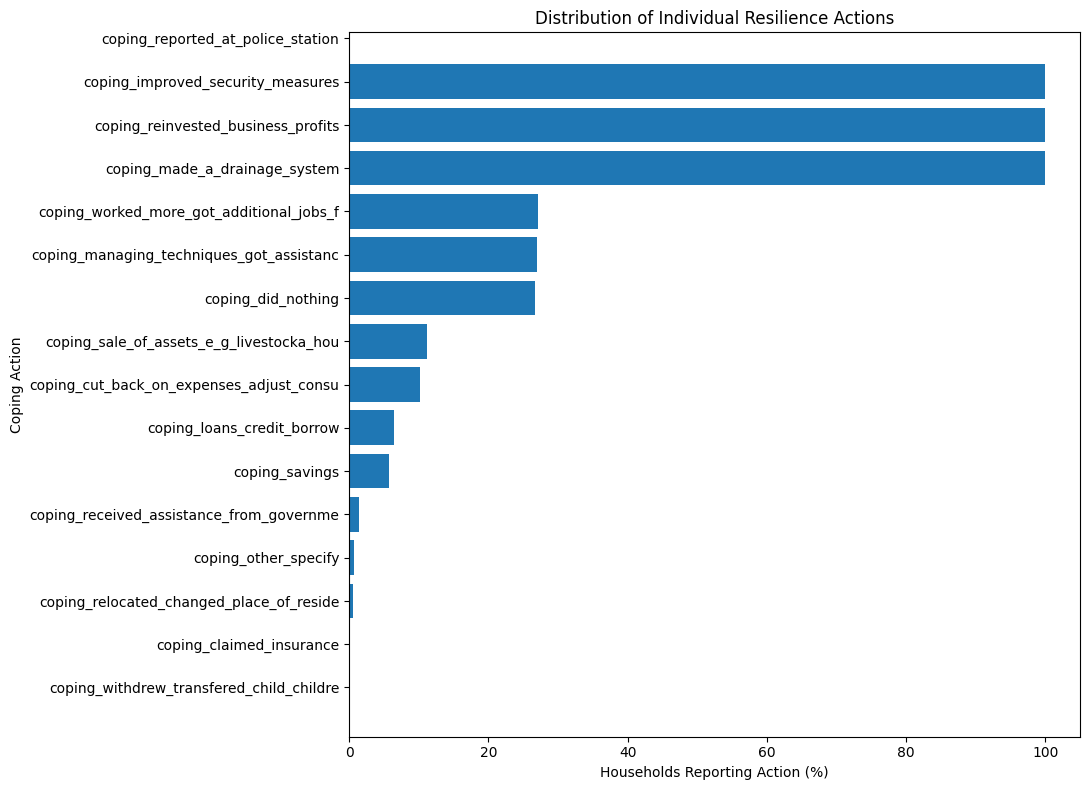

In [ ]:
# Visualising reported coping actions

coping_plot = coping_action_summary.sort_values(
    by="Percentage Yes"
)

plt.figure(figsize=(11, 8))

plt.barh(
    coping_plot["Coping Action"],
    coping_plot["Percentage Yes"]
)

plt.xlabel("Households Reporting Action (%)")
plt.ylabel("Coping Action")
plt.title("Distribution of Individual Resilience Actions")

plt.tight_layout()
plt.show()

#### Check consistency between the target and individual action

In [ ]:
# Compare the original classification with the did-nothing indicator

did_nothing_action = pd.to_numeric(
    drought_sample["coping_did_nothing"],
    errors="coerce"
)

did_nothing_target = (
    drought_sample["coping_category"] == "did_nothing"
)


# Generate a cross-tabulation

display(
    pd.crosstab(
        did_nothing_target,
        did_nothing_action,
        margins=True
    )
)


# Calculate agreement

valid = did_nothing_action.notna()

agreement = (
    did_nothing_target[valid] ==
    did_nothing_action[valid].eq(1)
).mean() * 100

print("Agreement between target and action:", round(agreement, 2), "%")

coping_did_nothing,0,1,All
coping_category,,,
False,1137,0,1137
True,0,415,415
All,1137,415,1552


Agreement between target and action: 100.0 %


#### Initial Findings

The resilience classification analysis shows that personal coping
is the most frequently reported category, accounting for 39.63%
of drought-exposed households. Informal coping represents 28.80%,
while 26.74% of households are classified as having done nothing.
Formal coping is the least represented category at 4.83%.

The individual coping action analysis also reveals considerable
variation in the types of responses reported.

Working more or obtaining additional employment and using
management techniques or receiving assistance are among the most
frequently recorded actions.

Several individual action variables have very few recorded
affirmative responses or substantial missingness. These variables
will require further consideration during data preparation.

The analysis also highlights a potential relationship between
the individual coping action indicators and the original resilience
classification. These variables will therefore be excluded from
the initial predictive feature selection to avoid target leakage.

The original four-category classification will be retained as the
primary outcome candidate, with the collapsed three-category
classification reserved for comparison during modelling.

## Bivariate and Multivariate Exploratory Data Analysis

This section examines relationships between household
characteristics, agricultural activities, shock exposure and
reported resilience mechanisms.

The analysis focuses on the drought-exposed population of
1,552 farming households.

Cross-tabulations, grouped descriptive statistics and
visualisations are used to investigate differences across
the four original resilience classifications.

These analyses are descriptive and are intended to identify
potential relationships and patterns for further investigation.
They do not establish causality.

### Demographic Characteristics and Resilience Classification

This subsection examines whether demographic characteristics
vary across the four reported resilience mechanisms.

The analysis considers respondent age, sex, education level
and urban or rural residence.

The objective is to establish whether differences in household
demographics are associated with the reported resilience
classification.

#### a) Age across resilience categories

In [ ]:
# Examine age statistics by resilience category

age_by_coping = drought_sample.groupby(
    "coping_category"
)["age_years"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(age_by_coping.round(2))

,count,mean,median,std,min,max
coping_category,,,,,,
did_nothing,415,43.60,42.0,15.97,16,95
formal,75,40.93,38.0,15.73,16,80
informal,447,46.32,43.0,17.93,16,101
personal,615,42.45,40.0,14.43,16,90


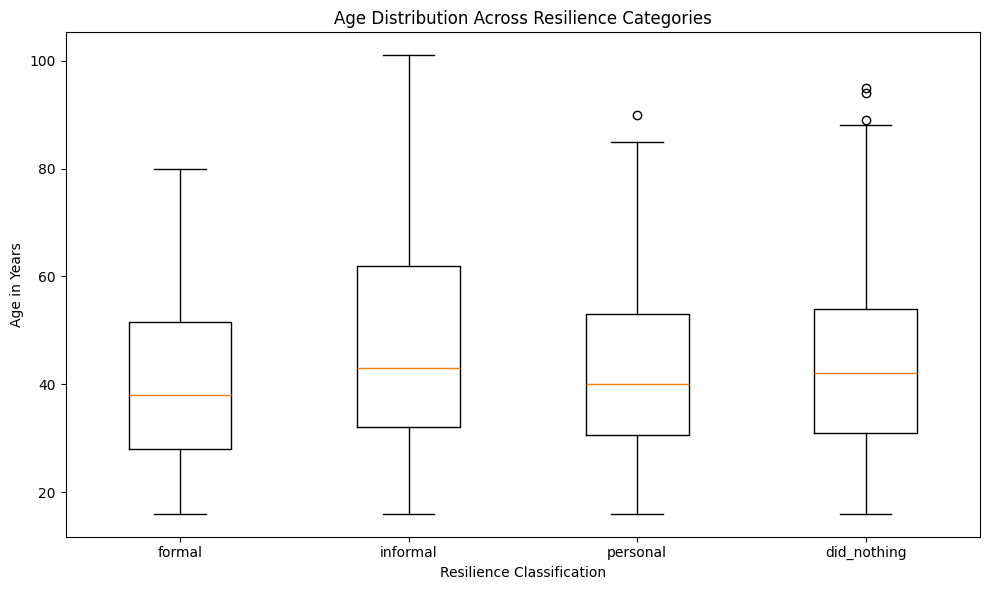

In [ ]:
# Prepare age distributions by coping category

coping_categories = [
    "formal",
    "informal",
    "personal",
    "did_nothing"
]

age_groups = [
    drought_sample.loc[
        drought_sample["coping_category"] == category,
        "age_years"
    ].dropna()
    for category in coping_categories
]


# Create boxplot

plt.figure(figsize=(10, 6))

plt.boxplot(age_groups)

plt.xticks(
    range(1, 5),
    coping_categories
)

plt.xlabel("Resilience Classification")
plt.ylabel("Age in Years")
plt.title("Age Distribution Across Resilience Categories")

plt.tight_layout()
plt.show()

#### b) Investigating how the sex categories are distributed across the resilience classifications

In [ ]:
# Compare sex with resilience classification

sex_counts = pd.crosstab(
    drought_sample["sex"],
    drought_sample["coping_category"]
)

print("Household counts")

display(sex_counts)


print("\nPercentage distribution within each sex category")

display(
    (
        pd.crosstab(
            drought_sample["sex"],
            drought_sample["coping_category"],
            normalize="index"
        ) * 100
    ).round(2)
)

Household counts


coping_category,did_nothing,formal,informal,personal
sex,,,,
1,181,47,160,302
2,234,28,287,313



Percentage distribution within each sex category


coping_category,did_nothing,formal,informal,personal
sex,,,,
1,26.23,6.81,23.19,43.77
2,27.15,3.25,33.29,36.31


#### c) Education and resilience classification
Education may provide useful information about differences in reported resilience mechanisms

In [ ]:
# Compare education with resilience classification

education_counts = pd.crosstab(
    drought_sample["education"],
    drought_sample["coping_category"]
)

print("Household counts")

display(education_counts)


print("\nPercentage distribution within each education category")

display(
    (
        pd.crosstab(
            drought_sample["education"],
            drought_sample["coping_category"],
            normalize="index"
        ) * 100
    ).round(2)
)

Household counts


coping_category,did_nothing,formal,informal,personal
education,,,,
1,117,9,93,163
2,157,28,214,252
3,101,25,116,147
4,40,13,24,53



Percentage distribution within each education category


coping_category,did_nothing,formal,informal,personal
education,,,,
1,30.63,2.36,24.35,42.67
2,24.12,4.30,32.87,38.71
3,25.96,6.43,29.82,37.79
4,30.77,10.00,18.46,40.77


#### d) Examining urban and rural residence

In [ ]:
# Compare residence with resilience classification

residence_counts = pd.crosstab(
    drought_sample["urban_rural"],
    drought_sample["coping_category"]
)

print("Household counts")

display(residence_counts)


print("\nPercentage distribution within each residence category")

display(
    (
        pd.crosstab(
            drought_sample["urban_rural"],
            drought_sample["coping_category"],
            normalize="index"
        ) * 100
    ).round(2)
)

Household counts


coping_category,did_nothing,formal,informal,personal
urban_rural,,,,
1,346,51,390,537
2,69,24,57,78



Percentage distribution within each residence category


coping_category,did_nothing,formal,informal,personal
urban_rural,,,,
1,26.13,3.85,29.46,40.56
2,30.26,10.53,25.00,34.21


### Agricultural Characteristics and Resilience Classification

This subsection investigates relationships between agricultural
characteristics and the reported resilience classifications.

The analysis focuses on crop and livestock diversity,
participation in different agricultural groups, land ownership
arrangements and landholding size.

The objective is to establish whether farming households with
different agricultural characteristics exhibit different
distributions of reported resilience mechanisms.

These relationships are particularly relevant to the proposed
farm segmentation, which will subsequently be examined as an
additional explanatory dimension in the study.

#### Comparing crop and livestock diversity
We first examine whether households reporting different numbers of crops and livestock types are distributed differently across the resilience classifications.

In [ ]:
# Compare agricultural diversity across resilience categories

portfolio_by_coping = drought_sample.groupby(
    "coping_category"
)[
    ["n_crop_types", "n_livestock_types"]
].agg(
    ["count", "mean", "median", "std"]
)

display(portfolio_by_coping.round(2))

n_crop_types                    n_livestock_types        \
                       count  mean median   std             count  mean   
coping_category                                                           
did_nothing              415  1.96    2.0  1.45               415  0.77   
formal                    75  2.12    2.0  1.23                75  0.79   
informal                 447  2.33    2.0  1.33               447  0.63   
personal                 615  1.97    2.0  1.41               615  0.88   

                              
                median   std  
coping_category               
did_nothing        0.0  1.00  
formal             0.0  1.04  
informal           0.0  1.00  
personal           0.0  1.12

In [ ]:
# Compare agricultural groups across resilience categories

portfolio_comparison = []

for column in available_groups:

    values = pd.to_numeric(
        drought_sample[column],
        errors="coerce"
    )

    for category in coping_categories:

        group_values = values[
            drought_sample["coping_category"] == category
        ]

        valid_values = group_values.notna().sum()
        yes_count = (group_values == 1).sum()

        percentage = (
            yes_count / valid_values * 100
            if valid_values > 0 else 0
        )

        portfolio_comparison.append({
            "Agricultural Group": column,
            "Resilience Category": category,
            "Households": yes_count,
            "Percentage": round(percentage, 2)
        })


portfolio_comparison = pd.DataFrame(
    portfolio_comparison
)

display(
    portfolio_comparison.pivot(
        index="Agricultural Group",
        columns="Resilience Category",
        values="Percentage"
    ).round(2)
)

Resilience Category,did_nothing,formal,informal,personal
Agricultural Group,,,,
has_cash_crops,18.31,28.00,17.90,16.26
has_cereals,66.02,73.33,82.55,71.38
has_dairy_livestock,7.71,10.67,8.28,9.11
has_horticulture,14.46,21.33,13.87,14.15
has_legumes,46.75,45.33,56.38,44.55
has_other_agri,0.24,0.00,0.00,0.81
has_other_livestock,38.07,36.00,26.17,41.30
has_poultry,9.40,10.67,10.07,8.94
has_roots_tubers,19.76,10.67,26.85,17.24


#### Compare land ownership arrangements

Here, we examine whether reported land ownership arrangements differ across resilience categories.

In [ ]:
# Compare land ownership across resilience categories

ownership_comparison = []

for column in ownership_columns:

    values = pd.to_numeric(
        drought_sample[column],
        errors="coerce"
    )

    for category in coping_categories:

        group_values = values[
            drought_sample["coping_category"] == category
        ]

        valid_values = group_values.notna().sum()
        yes_count = (group_values == 1).sum()

        percentage = (
            yes_count / valid_values * 100
            if valid_values > 0 else 0
        )

        ownership_comparison.append({
            "Ownership Arrangement": column,
            "Resilience Category": category,
            "Households": yes_count,
            "Percentage": round(percentage, 2)
        })


ownership_comparison = pd.DataFrame(
    ownership_comparison
)

display(
    ownership_comparison.pivot(
        index="Ownership Arrangement",
        columns="Resilience Category",
        values="Percentage"
    ).round(2)
)

Resilience Category,did_nothing,formal,informal,personal
Ownership Arrangement,,,,
land_ownership_community_public_owned_e,21.45,13.33,8.50,20.49
land_ownership_family_owned_e_g_inherite,51.33,53.33,61.97,51.54
land_ownership_lease_rent_you_dont_own,8.67,8.00,7.16,6.34
land_ownership_own_jointly_with_someone,0.48,0.00,0.22,0.98
land_ownership_own_jointly_with_spouse,8.67,5.33,6.94,6.67
land_ownership_own_under_your_name,13.98,21.33,18.12,16.59


#### Comparing land measurement units across resilience categories

Before comparing landholding sizes, we should understand whether the different measurement units are distributed differently across the resilience categories.

In [ ]:
# Compare land measurement units across resilience categories

land_unit_comparison = pd.crosstab(
    drought_sample["land_size_unit"].fillna("Missing"),
    drought_sample["coping_category"],
    margins=True
)

display(land_unit_comparison)

coping_category,did_nothing,formal,informal,personal,All
land_size_unit,,,,,
1,324,64,399,521,1308
2,14,3,12,7,36
3,4,1,5,7,17
4,0,1,4,3,8
5,73,6,26,77,182
Missing,0,0,1,0,1
All,415,75,447,615,1552


In [ ]:
# Percentage distribution of land measurement units

land_unit_percentage = pd.crosstab(
    drought_sample["land_size_unit"].fillna("Missing"),
    drought_sample["coping_category"],
    normalize="columns"
) * 100

display(land_unit_percentage.round(2))

coping_category,did_nothing,formal,informal,personal
land_size_unit,,,,
1,78.07,85.33,89.26,84.72
2,3.37,4.00,2.68,1.14
3,0.96,1.33,1.12,1.14
4,0.00,1.33,0.89,0.49
5,17.59,8.00,5.82,12.52
Missing,0.00,0.00,0.22,0.00


#### Compare landholding size within the acres category

Since acres are the dominant conventional measurement unit, we can conduct a preliminary comparison within this group.

This avoids directly comparing incompatible units.

We will temporarily exclude the special response codes 98 and 99, without modifying the original dataset.

In [ ]:
# Select households reporting land size in acres

land_acres = drought_sample[
    (drought_sample["land_size_unit"] == 1) &
    (~drought_sample["land_size"].isin([98, 99]))
].copy()


# Compare land size across resilience categories

land_size_by_coping = land_acres.groupby(
    "coping_category"
)["land_size"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(land_size_by_coping.round(2))

,count,mean,median,std,min,max
coping_category,,,,,,
did_nothing,322,3.84,1.0,15.77,0.10,200.0
formal,63,1.43,1.0,1.51,0.12,8.0
informal,395,2.49,1.0,11.41,0.02,200.0
personal,513,3.20,1.0,9.02,0.05,100.0


#### Initial Findings

The agricultural characteristics analysis reveals differences
in crop and livestock portfolios across the four resilience
classifications.

Households classified as informal report the highest average
number of crop types, while those classified as personal report
the highest average number of livestock types.

Cereal and legume cultivation are particularly common across
the sample. Cereal participation is highest among households
classified as informal, while other livestock participation
is highest among those classified as personal.

Family-owned or inherited land is the most frequently reported
ownership arrangement across all four classifications.

The landholding analysis also reveals considerable variation
within the acreage category. Although the median landholding
is one acre across all classifications, the means differ,
suggesting the influence of larger reported landholdings.

These findings suggest that agricultural portfolio composition,
livestock participation and land characteristics may provide
useful dimensions for understanding differences in household
resilience behaviour.

However, the observed differences are descriptive and do not
establish causal relationships. Potential differences will
require further statistical investigation and evaluation during
the modelling phase.

### Shock Exposure and Resilience Classification

This subsection investigates the relationship between
household shock exposure and reported resilience mechanisms.

Although the primary analytical population consists of
drought-exposed farming households, these households may
also experience other household and agricultural shocks.

The analysis therefore examines the number and types of
additional shocks reported by households and how these
are distributed across the four resilience classifications.

The objective is to establish whether households experiencing
different combinations of shocks exhibit different patterns
of reported resilience behaviour.

The analysis is descriptive and does not assume that the
reported main shock is necessarily the event to which the
resilience classification relates.

#### Number of additional shocks by category

Excluding drought itself, we examine how household in drought_sample has reported drought-related losses.

In [ ]:
# Identify shocks other than drought

other_shock_columns = [
    column for column in shock_columns
    if column != "shock_drought_loss"
]


# Count additional shocks per household

other_shock_data = drought_sample[
    other_shock_columns
].apply(
    pd.to_numeric,
    errors="coerce"
)

other_shock_count = other_shock_data.eq(1).sum(axis=1)


# Compare the number of additional shocks by category

shock_count_by_coping = pd.DataFrame({
    "Additional Shocks": other_shock_count,
    "Resilience Category": drought_sample["coping_category"]
}).groupby(
    "Resilience Category"
)["Additional Shocks"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(shock_count_by_coping.round(2))

,count,mean,median,std,min,max
Resilience Category,,,,,,
did_nothing,415,1.53,1.0,1.39,0,7
formal,75,2.16,2.0,1.75,0,6
informal,447,2.19,2.0,1.58,0,8
personal,615,1.69,1.0,1.48,0,8


#### Examining individual shock prevalence by category

In [ ]:
# Calculate shock prevalence across resilience categories

shock_category_results = []

for column in other_shock_columns:

    for category in coping_categories:

        values = other_shock_data.loc[
            drought_sample["coping_category"] == category,
            column
        ]

        valid = values.notna().sum()
        exposed = (values == 1).sum()

        percentage = (
            exposed / valid * 100
            if valid > 0 else 0
        )

        shock_category_results.append({
            "Shock": column,
            "Resilience Category": category,
            "Households": exposed,
            "Percentage": round(percentage, 2)
        })


shock_category_comparison = pd.DataFrame(
    shock_category_results
)


# Display percentage distribution

display(
    shock_category_comparison.pivot(
        index="Shock",
        columns="Resilience Category",
        values="Percentage"
    ).round(2)
)

Resilience Category,did_nothing,formal,informal,personal
Shock,,,,
shock_child_birth,5.30,9.33,7.61,7.15
shock_death_of_main_income_earner_family,6.27,18.67,30.20,10.08
shock_high_rainfall_flooding_mudslide_li,33.98,30.67,40.94,33.33
shock_livestock_crop_failure_due_to_pest,43.61,50.67,42.73,48.78
shock_loss_of_a_job_or_a_source_of_incom,6.99,20.00,11.86,10.57
shock_loss_of_income_or_major_financial,2.17,9.33,3.13,3.90
shock_loss_or_damage_due_to_human_wildli,8.43,8.00,6.71,9.27
shock_loss_or_damage_due_tofire_or_viole,0.72,4.00,2.01,1.79
shock_loss_or_damage_due_totheft_e_g_pro,22.41,22.67,18.12,14.96


#### Examining the main shock type by resilience classification

In [ ]:
# Compare main reported shock types and resilience categories

main_shock_coping = pd.crosstab(
    drought_sample["main_shock_type_label"],
    drought_sample["coping_category"]
)

display(main_shock_coping)

coping_category,did_nothing,formal,informal,personal
main_shock_type_label,,,,
Child birth,0,3,9,11
Death of main income earner/family member,6,4,72,18
High rainfall/flooding/mudslide/lightning,45,3,25,54
Livestock/crop failure due to pest and diseases,42,11,29,70
Loss of a job or a source of income or a wage cut,5,2,13,15
Loss of income or major financial expenses due to taking on care for someone els,0,2,4,7
Loss or damage due to drought,268,27,131,352
Loss or damage due to fire or violence including political violence,1,2,3,5
Loss or damage due to human wildlife conflict,13,1,5,6


In [ ]:
# Percentage distribution within each main shock type

main_shock_coping_percentage = pd.crosstab(
    drought_sample["main_shock_type_label"],
    drought_sample["coping_category"],
    normalize="index"
) * 100

display(main_shock_coping_percentage.round(2))

coping_category,did_nothing,formal,informal,personal
main_shock_type_label,,,,
Child birth,0.00,13.04,39.13,47.83
Death of main income earner/family member,6.00,4.00,72.00,18.00
High rainfall/flooding/mudslide/lightning,35.43,2.36,19.69,42.52
Livestock/crop failure due to pest and diseases,27.63,7.24,19.08,46.05
Loss of a job or a source of income or a wage cut,14.29,5.71,37.14,42.86
Loss of income or major financial expenses due to taking on care for someone els,0.00,15.38,30.77,53.85
Loss or damage due to drought,34.45,3.47,16.84,45.24
Loss or damage due to fire or violence including political violence,9.09,18.18,27.27,45.45
Loss or damage due to human wildlife conflict,52.00,4.00,20.00,24.00


### Geographic Distribution and Resilience Classification

This subsection examines the geographical distribution of
drought-exposed farming households across the 47 counties
represented in the 2024 survey.

The analysis investigates the representation of different
counties within the primary analytical population and examines
how reported resilience classifications are distributed
geographically.

The objective is to identify geographical variations and
potential differences in the representation of resilience
mechanisms across counties.

The analysis uses unweighted sample frequencies and percentages.
County-level findings will be interpreted cautiously, particularly
where the number of observations is relatively small.

In [ ]:
# Examine the distribution of drought-exposed households by county

county_distribution = (
    drought_sample["county"]
    .value_counts()
    .sort_values(ascending=False)
    .reset_index()
)

county_distribution.columns = [
    "County",
    "Households"
]

county_distribution["Percentage"] = (
    county_distribution["Households"] /
    len(drought_sample) * 100
).round(2)

display(county_distribution)

,County,Households,Percentage
0,2,95,6.12
1,34,87,5.61
2,3,82,5.28
3,24,77,4.96
4,42,75,4.83
5,40,74,4.77
6,43,63,4.06
7,30,63,4.06
8,41,61,3.93
9,23,60,3.87


In [ ]:
# Compare resilience classifications across counties

county_coping_counts = pd.crosstab(
    drought_sample["county"],
    drought_sample["coping_category"]
)

display(county_coping_counts)

coping_category,did_nothing,formal,informal,personal
county,,,,
1,7,1,2,6
2,30,7,27,31
3,18,5,37,22
4,0,0,1,12
5,0,0,0,10
6,12,5,20,18
7,0,0,5,17
8,8,0,4,13
9,2,1,0,1


In [ ]:
# Calculate resilience distribution within each county

county_coping_percentage = pd.crosstab(
    drought_sample["county"],
    drought_sample["coping_category"],
    normalize="index"
) * 100

display(county_coping_percentage.round(2))

coping_category,did_nothing,formal,informal,personal
county,,,,
1,43.75,6.25,12.50,37.50
2,31.58,7.37,28.42,32.63
3,21.95,6.10,45.12,26.83
4,0.00,0.00,7.69,92.31
5,0.00,0.00,0.00,100.00
6,21.82,9.09,36.36,32.73
7,0.00,0.00,22.73,77.27
8,32.00,0.00,16.00,52.00
9,50.00,25.00,0.00,25.00


#### Identifying counties with small analytical samples
This aims to establish whether any counties have insufficient observations for meaningful comparisons.

In [ ]:
# Examine county sample sizes

county_sample_sizes = county_coping_counts.copy()

county_sample_sizes["Total"] = (
    county_sample_sizes.sum(axis=1)
)

county_sample_sizes = county_sample_sizes.sort_values(
    by="Total"
)

display(county_sample_sizes)

coping_category,did_nothing,formal,informal,personal,Total
county,,,,,
20,1,0,0,0,1
16,1,1,0,1,3
19,0,0,1,2,3
46,0,1,1,1,3
9,2,1,0,1,4
35,2,0,2,1,5
37,3,0,1,1,5
26,5,0,0,1,6
47,4,0,3,0,7


Identifying county and classification combinations with fewer than five households

In [ ]:
# Identify small county-category combinations

small_groups = county_coping_counts[
    (county_coping_counts < 5) &
    (county_coping_counts > 0)
]

display(small_groups.stack().reset_index())

,county,coping_category,0
0,1,formal,1.0
1,1,informal,2.0
2,4,informal,1.0
3,8,informal,4.0
4,9,did_nothing,2.0
...,...,...,...
68,46,formal,1.0
69,46,informal,1.0
70,46,personal,1.0
71,47,did_nothing,4.0


#### Initial Findings

The geographical analysis shows that the drought-exposed sample
covers all 47 Kenyan counties represented in the survey.

However, the distribution of observations varies considerably
across counties. Several counties contain fewer than 20
drought-exposed households, limiting the reliability of
county-level comparisons.

Some counties exhibit noticeable differences in the distribution
of resilience classifications. However, these patterns must be
interpreted cautiously because of the varying sample sizes.

The findings suggest that geographical location may provide
useful contextual information when investigating household
resilience behaviour. County will therefore be considered as
a potential categorical predictor during Data Preparation.

The analysis uses unweighted sample distributions and should
not be interpreted as providing nationally representative
county-level estimates.

### Numerical Feature Relationships

This subsection examines relationships between numerical
and binary agricultural characteristics.

Correlation analysis is used to identify associations
between crop and livestock counts, agricultural group
participation and respondent age.

Particular attention is given to identifying potentially
redundant features that may affect subsequent farm
segmentation.

Spearman correlation is used because the variables include
binary indicators and discrete counts.

Categorical identifiers and numerical codes representing
nominal categories are excluded from this analysis.

Land size is also excluded at this stage because the
reported values use different measurement units and require
standardisation during Data Preparation.

The results will inform subsequent feature selection,
but correlation alone will not be used as a reason to
automatically remove variables.

In [ ]:
# Select numerical and binary agricultural features

relationship_columns = [
    "age_years",
    "n_crop_types",
    "n_livestock_types"
] + available_groups


# Create a temporary analysis dataset

relationship_data = drought_sample[
    relationship_columns
].copy()


# Ensure values are represented numerically

relationship_data = relationship_data.apply(
    pd.to_numeric,
    errors="coerce"
)


print("Variables included:", len(relationship_data.columns))
print("Observations:", len(relationship_data))

display(relationship_data.describe().round(2))

Variables included: 12
Observations: 1552


,age_years,n_crop_types,n_livestock_types,has_cash_crops,has_cereals,has_dairy_livestock,has_horticulture,has_legumes,has_other_agri,has_other_livestock,has_poultry,has_roots_tubers
count,1552.00,1552.00,1552.00,1552.00,1552.00,1552.00,1552.00,1552.00,1552.00,1552.00,1552.00,1552.0
mean,43.80,2.08,0.77,0.18,0.73,0.09,0.14,0.49,0.00,0.36,0.09,0.2
std,16.06,1.40,1.06,0.38,0.44,0.28,0.35,0.50,0.06,0.48,0.29,0.4
min,16.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0
25%,31.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0
50%,41.00,2.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0
75%,55.00,3.00,1.00,0.00,1.00,0.00,0.00,1.00,0.00,1.00,0.00,0.0
max,101.00,5.00,5.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.0


In [ ]:
# Calculate Spearman correlation coefficients

correlation_matrix = relationship_data.corr(
    method="spearman"
)

display(correlation_matrix.round(2))

,age_years,n_crop_types,n_livestock_types,has_cash_crops,has_cereals,has_dairy_livestock,has_horticulture,has_legumes,has_other_agri,has_other_livestock,has_poultry,has_roots_tubers
age_years,1.00,0.12,-0.06,0.06,0.13,0.03,-0.08,0.07,-0.03,-0.07,-0.02,0.09
n_crop_types,0.12,1.00,-0.43,0.33,0.66,-0.06,0.20,0.64,-0.08,-0.44,-0.06,0.49
n_livestock_types,-0.06,-0.43,1.00,-0.17,-0.33,0.37,-0.16,-0.21,0.02,0.87,0.39,-0.23
has_cash_crops,0.06,0.33,-0.17,1.00,0.06,0.04,-0.01,-0.04,-0.03,-0.17,-0.06,0.05
has_cereals,0.13,0.66,-0.33,0.06,1.00,-0.07,-0.04,0.49,-0.06,-0.32,0.00,0.23
has_dairy_livestock,0.03,-0.06,0.37,0.04,-0.07,1.00,0.02,-0.05,0.02,0.11,0.06,-0.07
has_horticulture,-0.08,0.20,-0.16,-0.01,-0.04,0.02,1.00,-0.07,-0.03,-0.18,-0.04,0.04
has_legumes,0.07,0.64,-0.21,-0.04,0.49,-0.05,-0.07,1.00,-0.06,-0.22,0.03,0.16
has_other_agri,-0.03,-0.08,0.02,-0.03,-0.06,0.02,-0.03,-0.06,1.00,0.04,-0.02,-0.03
has_other_livestock,-0.07,-0.44,0.87,-0.17,-0.32,0.11,-0.18,-0.22,0.04,1.00,0.13,-0.23


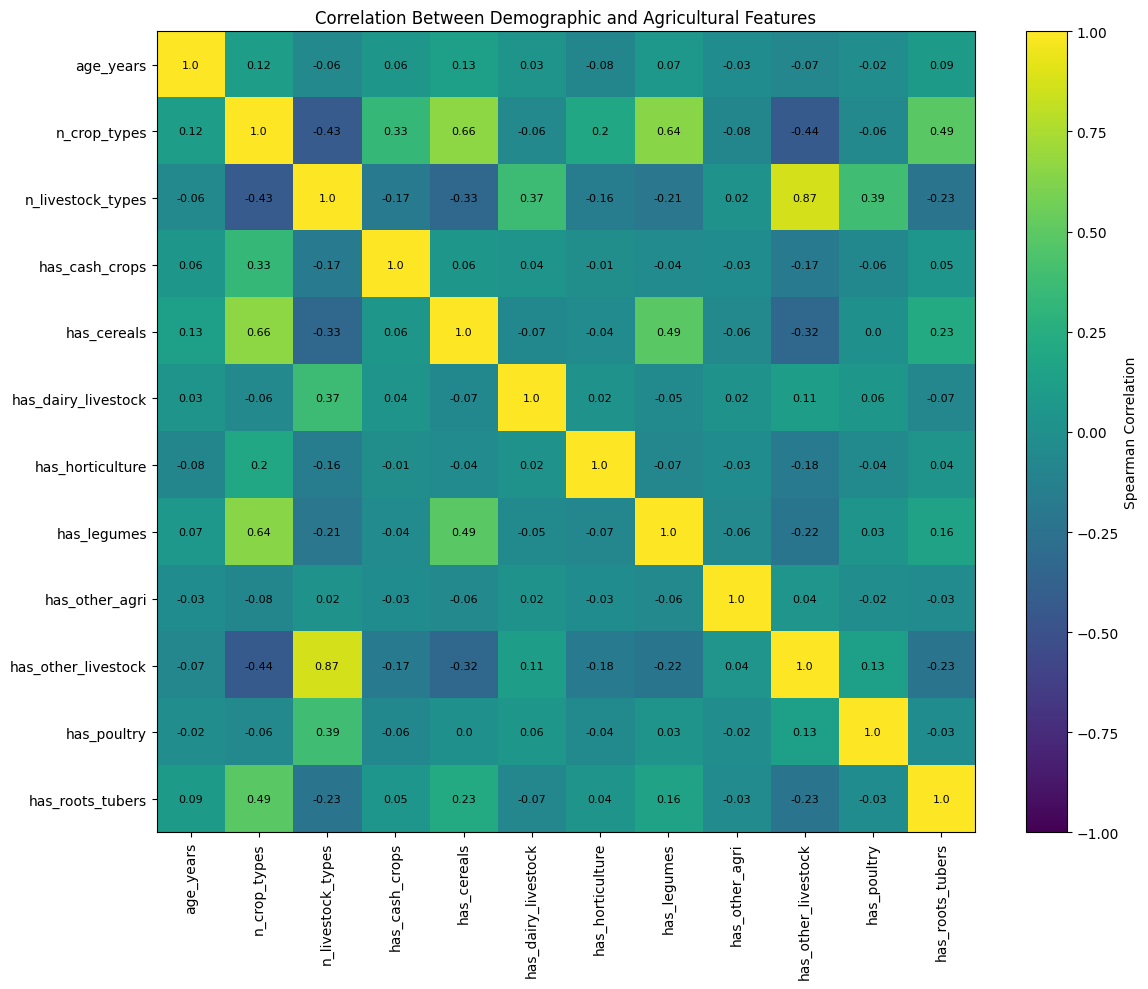

In [ ]:
# Visualise relationships between numerical features

plt.figure(figsize=(12, 10))

plt.imshow(
    correlation_matrix,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

plt.colorbar(label="Spearman Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.index)),
    correlation_matrix.index
)

plt.title("Correlation Between Demographic and Agricultural Features")

for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):

        plt.text(
            j,
            i,
            round(correlation_matrix.iloc[i, j], 2),
            ha="center",
            va="center",
            fontsize=8
        )

plt.tight_layout()
plt.show()

#### Identifying strongly correlated feature pairs

For exploratory purposes, we identify feature pairs with an absolute Spearman correlation of at least 0.70.

In [ ]:
# Identify strongly correlated feature pairs

correlation_pairs = []

for i in range(len(correlation_matrix.columns)):

    for j in range(i + 1, len(correlation_matrix.columns)):

        correlation = correlation_matrix.iloc[i, j]

        if abs(correlation) >= 0.70:

            correlation_pairs.append({
                "Feature 1": correlation_matrix.columns[i],
                "Feature 2": correlation_matrix.columns[j],
                "Correlation": round(correlation, 3)
            })


high_correlation = pd.DataFrame(correlation_pairs)

display(high_correlation)

,Feature 1,Feature 2,Correlation
0,n_livestock_types,has_other_livestock,0.868


### Preliminary Outlier Investigation

This subsection examines numerical variables for unusually
large or small observations that may require further
investigation.

The analysis focuses on respondent age and reported land size,
as these variables exhibit relatively wide numerical ranges.

The Interquartile Range (IQR) method is used as an initial
screening technique to identify observations outside the
conventional lower and upper IQR fences.

Land size is examined separately for each conventional
measurement unit because the reported values are not
directly comparable.

The purpose is to identify potential outliers rather than
automatically classify extreme observations as errors.

No observations will be removed or modified during this
investigation. Any required treatment will be considered
during the Data Preparation phase.

In [ ]:
# Examine age using the IQR method

age_values = drought_sample["age_years"].dropna()

Q1 = age_values.quantile(0.25)
Q3 = age_values.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

age_outliers = age_values[
    (age_values < lower_bound) |
    (age_values > upper_bound)
]

print("Age outlier investigation")

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

print("\nPotential outliers:", len(age_outliers))

display(age_outliers.describe())

Age outlier investigation
Q1: 31.0
Q3: 55.0
IQR: 24.0
Lower bound: -5.0
Upper bound: 91.0

Potential outliers: 5


,age_years
count,5.000000
mean,96.800000
std,3.420526
min,94.000000
25%,94.000000
50%,95.000000
75%,100.000000
max,101.000000


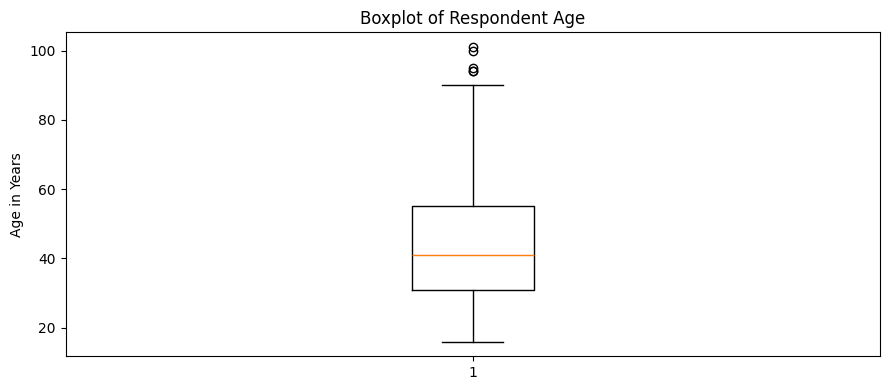

In [ ]:
# Boxplot of respondent age

plt.figure(figsize=(9, 4))

plt.boxplot(drought_sample["age_years"].dropna())

plt.ylabel("Age in Years")
plt.title("Boxplot of Respondent Age")

plt.tight_layout()
plt.show()

In [ ]:
# Prepare land size data for outlier investigation

land_check = drought_sample[
    ["land_size", "land_size_unit"]
].copy()

land_check["land_size"] = pd.to_numeric(
    land_check["land_size"],
    errors="coerce"
)

land_check["land_size_unit"] = pd.to_numeric(
    land_check["land_size_unit"],
    errors="coerce"
)

land_check = land_check[
    land_check["land_size_unit"].isin([1, 2, 3, 4]) &
    ~land_check["land_size"].isin([98, 99])
]


# Examine each measurement unit separately

land_outlier_results = []

for unit in [1, 2, 3, 4]:

    values = land_check.loc[
        land_check["land_size_unit"] == unit,
        "land_size"
    ].dropna()

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = values[
        (values < lower_bound) |
        (values > upper_bound)
    ]

    land_outlier_results.append({
        "Unit Code": unit,
        "Observations": len(values),
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Potential Outliers": len(outliers)
    })


land_outlier_summary = pd.DataFrame(
    land_outlier_results
)

display(land_outlier_summary)

,Unit Code,Observations,Lower Bound,Upper Bound,Potential Outliers
0,1,1293,-1.75,4.25,133
1,2,36,-2.00,6.00,5
2,3,17,-700.00,1220.00,3
3,4,8,-1.25,4.75,2


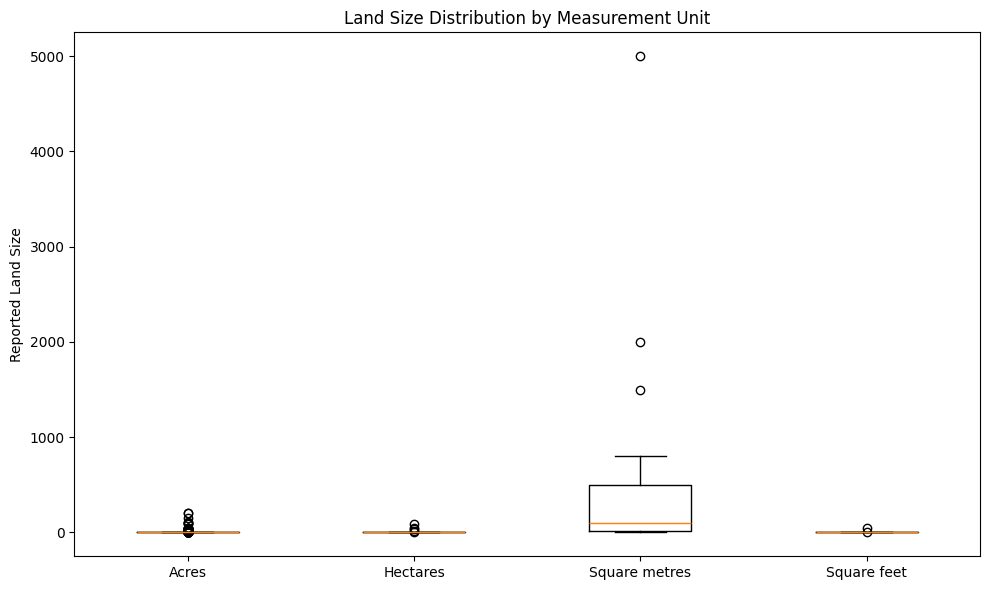

In [ ]:
# Compare land size distributions by measurement unit

land_groups = [
    land_check.loc[
        land_check["land_size_unit"] == unit,
        "land_size"
    ].dropna()
    for unit in [1, 2, 3, 4]
]

plt.figure(figsize=(10, 6))

plt.boxplot(land_groups)

plt.xticks(
    [1, 2, 3, 4],
    ["Acres", "Hectares", "Square metres", "Square feet"]
)

plt.ylabel("Reported Land Size")
plt.title("Land Size Distribution by Measurement Unit")

plt.tight_layout()
plt.show()

## Data Understanding Summary

The Data Understanding phase examined the prepared FinAccess
2024 dataset to establish its structure, characteristics,
distributions and suitability for the proposed analysis.

The analysis focused on the 9,756 farming households represented
in the prepared dataset, with particular attention given to the
1,552 households reporting drought-related losses.

The original questionnaires, source files and codebooks were examined during the initial data preparation
exercise. This phase therefore concentrated on understanding
the prepared data through descriptive statistics, data type
inspection, missingness analysis, exploratory visualisations
and examination of relationships between variables.

The analysis identified several issues that require attention
during Data Preparation, particularly the representation of
numerical and categorical variables, land measurement units,
special response codes, extreme observations and potential
feature redundancy.

The original four-category resilience classification will be
retained as the primary outcome candidate. A collapsed
three-category classification will also be considered as an
alternative.

The findings from this phase will inform the data cleaning,
transformation, feature engineering and feature selection
activities undertaken in the next CRISP-DM phase.

In [ ]:
# Document findings that will inform Data Preparation

preparation_requirements = [
    {
        "Area": "Data types",
        "Finding": "68 object variables contain numeric-like values",
        "Required Action": "Investigate and align data types according to variable meaning"
    },
    {
        "Area": "Categorical variables",
        "Finding": "Several categorical variables are represented by numerical codes",
        "Required Action": "Preserve categorical meaning and apply appropriate encoding where required"
    },
    {
        "Area": "Missing values",
        "Finding": "Overall missingness is 9.43%",
        "Required Action": "Investigate missingness by variable and distinguish structural missingness from item nonresponse"
    },
    {
        "Area": "Target availability",
        "Finding": "4,499 households without reported shocks have missing coping classifications",
        "Required Action": "Retain a clearly defined analytical population and avoid treating structural missingness as a target class"
    },
    {
        "Area": "Target definition",
        "Finding": "Four original resilience categories are available, with formal representing 4.83% of the drought-exposed sample",
        "Required Action": "Retain the four-class target and evaluate the collapsed three-class alternative"
    },
    {
        "Area": "Target leakage",
        "Finding": "Individual coping action variables overlap with the resilience classification",
        "Required Action": "Exclude individual coping actions from the initial predictive feature set"
    },
    {
        "Area": "Land characteristics",
        "Finding": "Land size is recorded in four conventional measurement units and a community land category",
        "Required Action": "Standardise conventional measurements into hectares and investigate community land separately"
    },
    {
        "Area": "Special response codes",
        "Finding": "Land size uses 98 for don't know and 99 for refused to answer",
        "Required Action": "Convert special response codes to an appropriate missing representation"
    },
    {
        "Area": "Outliers",
        "Finding": "Potential extreme ages and landholding observations identified",
        "Required Action": "Investigate extreme observations and determine appropriate treatment without automatically removing valid values"
    },
    {
        "Area": "Feature redundancy",
        "Finding": "Livestock count and other livestock participation have a correlation of 0.868",
        "Required Action": "Investigate overlapping agricultural features before segmentation"
    },
    {
        "Area": "Sparse features",
        "Finding": "Some agricultural and coping indicators have very few recorded affirmative responses",
        "Required Action": "Assess feature usefulness, coverage and variation"
    },
    {
        "Area": "Agricultural diversity",
        "Finding": "The existing Shannon diversity variable represents log portfolio richness",
        "Required Action": "Review its construction and assign an appropriate interpretation or name"
    },
    {
        "Area": "Geographical representation",
        "Finding": "County representation varies considerably within the drought-exposed sample",
        "Required Action": "Preserve county as a categorical variable and investigate the implications of small groups"
    },
    {
        "Area": "Survey wave compatibility",
        "Finding": "The 2021 and 2024 datasets contain differences in variable coverage and representation",
        "Required Action": "Assess variable and outcome comparability before undertaking cross-wave validation"
    },
    {
        "Area": "Agricultural segmentation",
        "Finding": "Crop and livestock portfolios have different distributions and levels of representation",
        "Required Action": "Evaluate feature scaling, sparsity and redundancy when constructing segmentation features"
    }
]

preparation_requirements = pd.DataFrame(
    preparation_requirements
)

display(preparation_requirements)

,Area,Finding,Required Action
0,Data types,68 object variables contain numeric-like values,Investigate and align data types according to ...
1,Categorical variables,Several categorical variables are represented ...,Preserve categorical meaning and apply appropr...
2,Missing values,Overall missingness is 9.43%,Investigate missingness by variable and distin...
3,Target availability,"4,499 households without reported shocks have ...",Retain a clearly defined analytical population...
4,Target definition,Four original resilience categories are availa...,Retain the four-class target and evaluate the ...
5,Target leakage,Individual coping action variables overlap wit...,Exclude individual coping actions from the ini...
6,Land characteristics,Land size is recorded in four conventional mea...,Standardise conventional measurements into hec...
7,Special response codes,Land size uses 98 for don't know and 99 for re...,Convert special response codes to an appropria...
8,Outliers,Potential extreme ages and landholding observa...,Investigate extreme observations and determine...
9,Feature redundancy,Livestock count and other livestock participat...,Investigate overlapping agricultural features ...


In [ ]:
# Summarise identified preparation requirements

print(
    "Total identified requirements:",
    len(preparation_requirements)
)

display(
    preparation_requirements["Area"]
    .value_counts()
    .rename_axis("Area")
    .reset_index(name="Number of Findings")
)

Total identified requirements: 15


,Area,Number of Findings
0,Data types,1
1,Categorical variables,1
2,Missing values,1
3,Target availability,1
4,Target definition,1
5,Target leakage,1
6,Land characteristics,1
7,Special response codes,1
8,Outliers,1
9,Feature redundancy,1


## Data Understanding Phase Conclusion

The Data Understanding phase established that the prepared
2024 FinAccess dataset contains 9,756 farming households,
including 1,552 households reporting drought-related losses.

The drought-exposed sample contains complete observations
for the original four-category resilience classification,
comprising formal, informal, personal and did nothing.

The exploratory analysis revealed differences in demographic
characteristics, agricultural portfolios, land ownership and
additional shock exposure across the resilience classifications.

Several data quality and representation issues were also
identified. These include numeric-like object variables,
special land size response codes, different land measurement
units, sparse indicators, potential extreme observations
and correlated agricultural features.

The analysis also identified a potential relationship between
individual coping actions and the resilience classification,
highlighting the need to prevent target leakage during
predictor selection.

The findings demonstrate that additional preparation is
necessary before the datasets can be used for segmentation
and supervised classification.

The next phase will therefore focus on addressing the
identified data quality issues, establishing consistent
variable representations, engineering appropriate features
and constructing the analytical datasets required for modelling.

# Data Preparation

This phase focuses on preparing the FinAccess datasets for
farm segmentation and supervised classification.

The findings from Data Understanding identified several issues
requiring attention, including inconsistent data types, special
response codes, missing observations, extreme values and
potentially redundant features.

Data Preparation will address these issues through data cleaning,
type alignment, missing value treatment, outlier investigation,
feature engineering, feature selection and transformation.

The original prepared datasets will be preserved. Additional
changes will be performed on separate working copies to maintain
the ability to trace and validate each transformation.

## Establishing the Analytical Dataset

The 2024 farming-household dataset will serve as the primary
dataset for the analysis.

The primary analytical population consists of households
reporting drought-related losses. The original four-category
resilience classification will be retained as the primary
outcome candidate, while the collapsed three-category version
will be preserved as an alternative.

The 2021 dataset will remain separate because its questionnaire
and available resilience outcome variables differ from those
of the 2024 survey.

In [ ]:
# Create a working copy of drought-exposed households

analysis_2024 = df24[
    df24["drought_exposed"] == 1
].copy()

print("Primary analytical dataset")

print("Observations:", analysis_2024.shape[0])
print("Variables:", analysis_2024.shape[1])

print("\nDrought exposure distribution:")

print(
    analysis_2024["drought_exposed"].value_counts()
)

Primary analytical dataset
Observations: 1552
Variables: 131

Drought exposure distribution:
drought_exposed
1    1552
Name: count, dtype: int64


In [ ]:
# Define the two target candidates

primary_target = "coping_category"

alternative_target = "coping_category_collapsed"


# Examine target completeness

target_summary = pd.DataFrame({
    "Target": [primary_target, alternative_target],
    "Non-Missing": [
        analysis_2024[primary_target].notna().sum(),
        analysis_2024[alternative_target].notna().sum()
    ],
    "Missing": [
        analysis_2024[primary_target].isna().sum(),
        analysis_2024[alternative_target].isna().sum()
    ],
    "Unique Classes": [
        analysis_2024[primary_target].nunique(),
        analysis_2024[alternative_target].nunique()
    ]
})

display(target_summary)


print("\nPrimary target distribution:")

display(
    analysis_2024[primary_target].value_counts()
)


print("\nAlternative target distribution:")

display(
    analysis_2024[alternative_target].value_counts()
)

,Target,Non-Missing,Missing,Unique Classes
0,coping_category,1552,0,4
1,coping_category_collapsed,1552,0,3



Primary target distribution:


,count
coping_category,
personal,615
informal,447
did_nothing,415
formal,75



Alternative target distribution:


,count
coping_category_collapsed,
personal,615
formal_or_informal,522
did_nothing,415


In [ ]:
# Define the expected collapsed classification

target_mapping = {
    "formal": "formal_or_informal",
    "informal": "formal_or_informal",
    "personal": "personal",
    "did_nothing": "did_nothing"
}


# Generate the expected classification

expected_target = analysis_2024[
    primary_target
].map(target_mapping)


# Compare with the existing collapsed target

target_matches = (
    expected_target ==
    analysis_2024[alternative_target]
)

print("Matching observations:", target_matches.sum())
print("Non-matching observations:", (~target_matches).sum())

print(
    "Percentage agreement:",
    round(target_matches.mean() * 100, 2),
    "%"
)

Matching observations: 1552
Non-matching observations: 0
Percentage agreement: 100.0 %


In [ ]:
# Check respondent identifier uniqueness

identifier_summary = pd.DataFrame({
    "Dataset": ["df24", "analysis_2024"],
    "Observations": [
        len(df24),
        len(analysis_2024)
    ],
    "Unique Respondents": [
        df24["respondent_id"].nunique(),
        analysis_2024["respondent_id"].nunique()
    ],
    "Duplicate Identifiers": [
        df24["respondent_id"].duplicated().sum(),
        analysis_2024["respondent_id"].duplicated().sum()
    ],
    "Missing Identifiers": [
        df24["respondent_id"].isna().sum(),
        analysis_2024["respondent_id"].isna().sum()
    ]
})

display(identifier_summary)

,Dataset,Observations,Unique Respondents,Duplicate Identifiers,Missing Identifiers
0,df24,9756,9756,0,0
1,analysis_2024,1552,1552,0,0


## Preliminary Feature Grouping

The potential explanatory variables are organised into
thematic groups according to their role in the study.

These groups include household demographics, agricultural
characteristics, land ownership, household shock exposure
and financial access.

The agricultural variables will primarily contribute to
farm segmentation, while the broader set of household and
agricultural characteristics will be considered for
supervised classification.

The individual coping action variables and direct target
representations will be excluded from the initial predictor
candidates to prevent target leakage.

Final feature selection will be undertaken after the
relevant variables have been cleaned, transformed and
evaluated.

In [ ]:
# Household demographic features

demographic_features = [
    "age_years",
    "sex",
    "education",
    "urban_rural",
    "county"
]


# Land characteristics

land_features = [
    "land_size",
    "land_size_unit"
] + ownership_columns


# Agricultural portfolio features

portfolio_features = (
    available_groups +
    [
        "n_crop_types",
        "n_livestock_types",
        "shannon_diversity"
    ]
)


# Household and agricultural shock features

shock_features = [
    column for column in analysis_2024.columns
    if column.startswith("shock_")
    and column != "shock_drought_loss"
]


# Main reported shock

shock_features.append("main_shock_type")


# Financial access and agricultural finance features

finance_features = [
    "buyer_supplier_credit",
    "formal_agri_borrowing",
    "used_formal_credit",
    "used_buyer_credit",
    "used_digital_credit",
    "used_insurance",
    "bank_usage",
    "savings_usage",
    "loan_usage",
    "mobile_money_usage",
    "mfi_usage"
]


# Display feature groups

feature_groups = {
    "Demographics": demographic_features,
    "Land characteristics": land_features,
    "Agricultural portfolios": portfolio_features,
    "Shock exposure": shock_features,
    "Financial access": finance_features
}


for group, features in feature_groups.items():

    available = [
        column for column in features
        if column in analysis_2024.columns
    ]

    print(f"\n{group}: {len(available)} variables")

    print(available)


Demographics: 5 variables
['age_years', 'sex', 'education', 'urban_rural', 'county']

Land characteristics: 8 variables
['land_size', 'land_size_unit', 'land_ownership_own_under_your_name', 'land_ownership_own_jointly_with_spouse', 'land_ownership_own_jointly_with_someone', 'land_ownership_lease_rent_you_dont_own', 'land_ownership_community_public_owned_e', 'land_ownership_family_owned_e_g_inherite']

Agricultural portfolios: 12 variables
['has_cash_crops', 'has_cereals', 'has_dairy_livestock', 'has_horticulture', 'has_legumes', 'has_other_agri', 'has_other_livestock', 'has_poultry', 'has_roots_tubers', 'n_crop_types', 'n_livestock_types', 'shannon_diversity']

Shock exposure: 12 variables
['shock_child_birth', 'shock_major_sickness_health_problem_acci', 'shock_high_rainfall_flooding_mudslide_li', 'shock_death_of_main_income_earner_family', 'shock_loss_or_damage_due_totheft_e_g_pro', 'shock_loss_of_a_job_or_a_source_of_incom', 'shock_lost_a_home_or_land_e_g_due_to_evi', 'shock_livesto

In [ ]:
# Identify direct target and coping-related variables

target_columns = [
    "coping_category",
    "coping_category_code",
    "coping_category_collapsed",
    "coping_channel"
]


coping_action_features = [
    column for column in analysis_2024.columns
    if column.startswith("coping_")
    and column not in target_columns
]


# Other variables reserved for identification or survey weighting

identifier_columns = ["respondent_id"]

weight_columns = [
    "individual_weight",
    "household_weight"
]


print("Target variables:")

print(target_columns)

print("\nCoping action variables excluded from initial predictors:")

print(coping_action_features)

print("\nIdentifiers:")

print(identifier_columns)

print("\nSurvey weights:")

print(weight_columns)

Target variables:
['coping_category', 'coping_category_code', 'coping_category_collapsed', 'coping_channel']

Coping action variables excluded from initial predictors:
['coping_worked_more_got_additional_jobs_f', 'coping_managing_techniques_got_assistanc', 'coping_sale_of_assets_e_g_livestocka_hou', 'coping_cut_back_on_expenses_adjust_consu', 'coping_loans_credit_borrow', 'coping_savings', 'coping_relocated_changed_place_of_reside', 'coping_claimed_insurance', 'coping_withdrew_transfered_child_childre', 'coping_received_assistance_from_governme', 'coping_did_nothing', 'coping_other_specify', 'coping_made_a_drainage_system', 'coping_improved_security_measures', 'coping_reported_at_police_station', 'coping_reinvested_business_profits']

Identifiers:
['respondent_id']

Survey weights:
['individual_weight', 'household_weight']


## Data Cleaning

Data cleaning addresses inconsistencies, invalid values and
special response representations identified during Data
Understanding.

The process begins with land characteristics because land
size is recorded using different measurement units and
contains special response codes.

The objective is to establish which observations represent
valid land measurements, missing responses and categorical
land ownership arrangements before standardising the variable.

In [ ]:
# Inspect land size variable

print("Land size data type:")
print(analysis_2024["land_size"].dtype)

print("\nLand measurement unit data type:")
print(analysis_2024["land_size_unit"].dtype)

print("\nLand size summary:")
display(
    analysis_2024["land_size"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame()
)

print("\nMeasurement unit distribution:")

display(
    analysis_2024["land_size_unit"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("Households")
)

Land size data type:
float64

Land measurement unit data type:
object

Land size summary:


,land_size
count,1552.000000
mean,22.817951
std,148.670261
min,0.025000
25%,0.687500
50%,1.500000
75%,4.000000
90%,98.000000
95%,98.000000
99%,132.150000



Measurement unit distribution:


,Households
land_size_unit,
1,1308
2,36
3,17
4,8
5,182
NaN,1


In [ ]:
# Investigate special land size response codes

special_codes = [98, 99]

special_code_summary = (
    analysis_2024[
        analysis_2024["land_size"].isin(special_codes)
    ]
    .groupby(["land_size_unit", "land_size"])
    .size()
    .reset_index(name="Households")
)

display(special_code_summary)


print("\nTotal observations containing special codes:")

print(
    analysis_2024["land_size"]
    .isin(special_codes)
    .sum()
)

,land_size_unit,land_size,Households
0,1,98.0,15
1,5,98.0,169
2,5,99.0,2



Total observations containing special codes:
187


#### Examine land size distributions by measurement unit

This will help us distinguish between genuine extreme observations and values that appear extreme simply because different measurement units are being used.

In [ ]:
# Summarise land size by measurement unit

land_unit_summary = (
    analysis_2024
    .groupby("land_size_unit")["land_size"]
    .agg(
        observations="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
    .round(3)
)

display(land_unit_summary)

,observations,mean,median,std,minimum,maximum
land_size_unit,,,,,,
1,1308,4.146,1.0,15.330,0.025,200.0
2,36,7.350,2.0,17.870,0.250,94.0
3,17,655.088,100.0,1257.456,0.250,5000.0
4,8,7.625,1.0,16.449,1.000,48.0
5,182,101.266,98.0,38.902,1.500,350.0


In [ ]:
# Identify extreme land size observations

land_extremes = (
    analysis_2024[
        analysis_2024["land_size"].notna()
    ]
    .sort_values("land_size", ascending=False)
    [
        [
            "respondent_id",
            "county",
            "land_size",
            "land_size_unit"
        ]
    ]
    .head(20)
)

display(land_extremes)

,respondent_id,county,land_size,land_size_unit
17434,c91b9329f8a44cf5ba9c62d3d4780b1c,41,5000.0,3
20817,6438d81a81084498808f7e2d80a60ab7,8,2000.0,3
2580,040c234fb04044f3bb0a568c01a27b03,8,1500.0,3
16137,6b2363b7e8d749d583e6c2c73897b539,38,800.0,3
16136,8bd0f42de734428f88f087fc59c8c9a4,38,500.0,3
20809,fa3917275a0347bfa310c48d61a4a359,8,500.0,3
20798,ee85f4e0f0324d57bcc2bd85c02fd74b,8,400.0,3
13787,52636e40a1ab48cd9e23a2934ea3eeef,34,350.0,5
13780,faaa31cea03347e5843da0b2cf7c1375,34,350.0,5
13806,49a861a012834eb5ad4b732e75c05b07,34,300.0,5


### Cleaning land size

In [ ]:
# Preserve the original values and create a numeric unit code
analysis_2024["land_size_unit_code"] = pd.to_numeric(
    analysis_2024["land_size_unit"],
    errors="coerce"
)

# Remove special response codes
valid_land_size = analysis_2024["land_size"].copy()
valid_land_size = valid_land_size.mask(valid_land_size.isin([98, 99]))

# Conversion factors to acres
conversion_factors = {
    1: 1,
    2: 2.47105,
    3: 0.000247105,
    4: 1 / 43560
}

# Convert measurements to acres
analysis_2024["land_size_acres"] = (
    valid_land_size
    * analysis_2024["land_size_unit_code"].map(conversion_factors)
)

# Check the results
print("Land size cleaning summary")
print("Original observations:", len(analysis_2024))
print("Valid converted measurements:",
      analysis_2024["land_size_acres"].notna().sum())
print("Missing converted measurements:",
      analysis_2024["land_size_acres"].isna().sum())

print("\nConverted land size summary:")
display(
    analysis_2024["land_size_acres"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame()
)

print("\nConverted land size by original unit:")
display(
    analysis_2024
    .groupby("land_size_unit_code")["land_size_acres"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(3)
)

Land size cleaning summary
Original observations: 1552
Valid converted measurements: 1354
Missing converted measurements: 198

Converted land size summary:


,land_size_acres
count,1354.000000
mean,3.404323
std,13.593814
min,0.000023
25%,0.500000
50%,1.000000
75%,2.000000
90%,5.000000
95%,8.000000
99%,48.410000



Converted land size by original unit:


,count,mean,median,min,max
land_size_unit_code,,,,,
1.0,1293,3.057,1.000,0.025,200.000
2.0,36,18.162,4.942,0.618,232.279
3.0,17,0.162,0.025,0.000,1.236
4.0,8,0.000,0.000,0.000,0.001
5.0,0,NaN,NaN,NaN,NaN


In [ ]:
# Largest converted land holdings
land_extremes = (
    analysis_2024[
        analysis_2024["land_size_acres"].notna()
    ]
    .sort_values("land_size_acres", ascending=False)
    [[
        "respondent_id",
        "county",
        "land_size",
        "land_size_unit",
        "land_size_acres"
    ]]
    .head(20)
)

display(land_extremes)

# Inspect the original measurements by unit
unit_value_summary = (
    analysis_2024
    .groupby("land_size_unit_code")["land_size"]
    .agg(
        observations="count",
        unique_values="nunique",
        median="median",
        minimum="min",
        maximum="max"
    )
)

display(unit_value_summary)

# Inspect observations recorded under unit 4 and unit 5
display(
    analysis_2024[
        analysis_2024["land_size_unit_code"].isin([4, 5])
    ][[
        "land_size",
        "land_size_unit",
        "land_size_unit_code",
        "land_size_acres"
    ]]
    .sort_values(["land_size_unit_code", "land_size"])
)

,respondent_id,county,land_size,land_size_unit,land_size_acres
13862,3bf85bb25fc34f12b2e88ac81a0e5329,34,94.0,2,232.27870
13767,17d683b611b242dbb1e0a603286afce1,34,200.0,1,200.00000
13810,374548a61d76421ba86d35fcda496c45,34,200.0,1,200.00000
13797,5897d2e8ae04436ea7ad0305296567f7,34,150.0,1,150.00000
13865,5a26b23eebda48b89ba02a739ea4e539,34,47.0,2,116.13935
13768,98c612dea738485281939ea4dceeff5e,34,115.0,1,115.00000
14089,790886372f6b466a8674f52c76955de4,34,100.0,1,100.00000
13766,1364afa31e5d49a48059e9bf0aff2516,34,100.0,1,100.00000
14087,0b6f8c3d6d5e4c13b8a35d3ac2899fc6,34,100.0,1,100.00000
13858,9375657ab8c5452ba4effbaa67823f9d,34,40.0,2,98.84200


,observations,unique_values,median,minimum,maximum
land_size_unit_code,,,,,
1.0,1308,59,1.0,0.025,200.0
2.0,36,17,2.0,0.250,94.0
3.0,17,14,100.0,0.250,5000.0
4.0,8,3,1.0,1.000,48.0
5.0,182,10,98.0,1.500,350.0


,land_size,land_size_unit,land_size_unit_code,land_size_acres
11106,1.0,4,4.0,0.000023
11135,1.0,4,4.0,0.000023
11150,1.0,4,4.0,0.000023
11445,1.0,4,4.0,0.000023
11454,1.0,4,4.0,0.000023
...,...,...,...,...
13779,250.0,5,5.0,NaN
13781,300.0,5,5.0,NaN
13806,300.0,5,5.0,NaN
13780,350.0,5,5.0,NaN


In [ ]:
# Classify why land_size_acres is missing
missing_land = analysis_2024[
    analysis_2024["land_size_acres"].isna()
].copy()

missing_land["missing_reason"] = np.select(
    [
        missing_land["land_size_unit_code"].eq(5),
        missing_land["land_size"].isin([98, 99]),
        missing_land["land_size_unit_code"].isna()
    ],
    [
        "Community land",
        "Special response code",
        "Missing measurement unit"
    ],
    default="Other or unresolved"
)

print("Missing land measurement reasons:")
display(
    missing_land["missing_reason"]
    .value_counts(dropna=False)
    .to_frame("Households")
)

print("\nObservations with missing measurement unit:")
display(
    analysis_2024[
        analysis_2024["land_size_unit_code"].isna()
    ][["land_size", "land_size_unit", "land_size_acres"]]
)

Missing land measurement reasons:


,Households
missing_reason,
Community land,182
Special response code,16



Observations with missing measurement unit:


,land_size,land_size_unit,land_size_acres
16979,98.0,NaN,NaN


#### Decisions:
- Keep the original land_size and land_size_unit columns.
- Retain land_size_acres as the standardised numerical measurement.
- Leave community land observations missing in land_size_acres.
- Treat 98 and 99 as missing response codes.
- Do not remove households with missing land measurements from the analytical dataset.

In [ ]:
land_size_summary = pd.DataFrame({
    "Measure": [
        "Total households",
        "Valid land measurements",
        "Community land",
        "Special response codes",
        "Missing measurement unit",
        "Missing converted measurements"
    ],
    "Count": [
        len(analysis_2024),
        analysis_2024["land_size_acres"].notna().sum(),
        (analysis_2024["land_size_unit_code"] == 5).sum(),
        analysis_2024["land_size"].isin([98, 99]).sum(),
        analysis_2024["land_size_unit_code"].isna().sum(),
        analysis_2024["land_size_acres"].isna().sum()
    ]
})

land_size_summary["Percentage"] = (
    land_size_summary["Count"] / len(analysis_2024) * 100
).round(2)

display(land_size_summary)

,Measure,Count,Percentage
0,Total households,1552,100.00
1,Valid land measurements,1354,87.24
2,Community land,182,11.73
3,Special response codes,187,12.05
4,Missing measurement unit,1,0.06
5,Missing converted measurements,198,12.76


We now investigate the unusually large holdings, particularly those concentrated in county 34.

In order to establish whether they are plausible observations or possible data-entry errors. We will retain them unless there is evidence to justify changing them.

In [ ]:
county_land_summary = (
    analysis_2024
    .groupby("county")["land_size_acres"]
    .agg(
        households="count",
        median="median",
        mean="mean",
        maximum="max"
    )
    .sort_values("maximum", ascending=False)
    .round(2)
)

display(county_land_summary.head(15))

,households,median,mean,maximum
county,,,,
34,76,3.50,26.40,232.28
3,82,1.75,2.96,41.00
29,18,0.65,3.22,40.00
24,74,2.00,3.65,35.58
33,9,3.00,8.44,30.00
2,95,3.00,4.27,25.00
7,11,1.00,3.21,15.00
30,52,1.50,1.96,14.00
46,3,1.00,4.58,12.50


In [ ]:
largest_land = (
    analysis_2024[
        analysis_2024["land_size_acres"].notna()
    ][
        [
            "respondent_id",
            "county",
            "land_size",
            "land_size_unit",
            "land_size_acres",
            "coping_category"
        ]
    ]
    .sort_values("land_size_acres", ascending=False)
    .head(15)
)

display(largest_land)

,respondent_id,county,land_size,land_size_unit,land_size_acres,coping_category
13862,3bf85bb25fc34f12b2e88ac81a0e5329,34,94.0,2,232.27870,did_nothing
13767,17d683b611b242dbb1e0a603286afce1,34,200.0,1,200.00000,informal
13810,374548a61d76421ba86d35fcda496c45,34,200.0,1,200.00000,did_nothing
13797,5897d2e8ae04436ea7ad0305296567f7,34,150.0,1,150.00000,did_nothing
13865,5a26b23eebda48b89ba02a739ea4e539,34,47.0,2,116.13935,did_nothing
13768,98c612dea738485281939ea4dceeff5e,34,115.0,1,115.00000,did_nothing
14089,790886372f6b466a8674f52c76955de4,34,100.0,1,100.00000,personal
13766,1364afa31e5d49a48059e9bf0aff2516,34,100.0,1,100.00000,personal
14087,0b6f8c3d6d5e4c13b8a35d3ac2899fc6,34,100.0,1,100.00000,informal
13858,9375657ab8c5452ba4effbaa67823f9d,34,40.0,2,98.84200,did_nothing


In [ ]:
coping_land_summary = (
    analysis_2024
    .groupby("coping_category")["land_size_acres"]
    .agg(
        households="count",
        median="median",
        mean="mean",
        p95=lambda x: x.quantile(0.95),
        maximum="max"
    )
    .round(2)
)

display(coping_land_summary)

,households,median,mean,p95,maximum
coping_category,,,,,
did_nothing,340,1.0,5.18,10.0,232.28
formal,68,1.0,1.63,5.0,8.00
informal,416,1.0,2.55,5.0,200.00
personal,530,1.0,3.16,10.0,100.00


#### We close this variable with the following decisions:

- Standardise valid measurements into acres using the confirmed conversion factors.
- Preserve the original land_size and land_size_unit columns for traceability.
- Treat codes 98 and 99 as missing measurements.
- Leave community land observations without a numerical acreage.
- Retain unusually large measurements because there is insufficient evidence that they are erroneous.
- Do not impute missing land measurements at this stage.

#### Land ownership variables

We establish their data types, missing values and response distributions. This will help us determine how the variables are encoded before making any cleaning decisions.

In [ ]:
land_ownership_vars = [
    "land_ownership_own_under_your_name",
    "land_ownership_own_jointly_with_spouse",
    "land_ownership_own_jointly_with_someone",
    "land_ownership_lease_rent_you_dont_own",
    "land_ownership_community_public_owned_e",
    "land_ownership_family_owned_e_g_inherite"
]

# Inspect data types and missingness
ownership_overview = pd.DataFrame({
    "dtype": analysis_2024[land_ownership_vars].dtypes,
    "missing": analysis_2024[land_ownership_vars].isna().sum(),
    "missing_pct": (
        analysis_2024[land_ownership_vars].isna().mean() * 100
    ).round(2),
    "unique_values": analysis_2024[land_ownership_vars].nunique(
        dropna=True
    )
})

display(ownership_overview)

# Inspect response distributions
for column in land_ownership_vars:
    print(f"\n{column}")
    display(
        analysis_2024[column]
        .value_counts(dropna=False)
        .sort_index()
        .to_frame("households")
    )

,dtype,missing,missing_pct,unique_values
land_ownership_own_under_your_name,object,0,0.0,2
land_ownership_own_jointly_with_spouse,object,0,0.0,2
land_ownership_own_jointly_with_someone,object,0,0.0,2
land_ownership_lease_rent_you_dont_own,object,0,0.0,2
land_ownership_community_public_owned_e,object,0,0.0,2
land_ownership_family_owned_e_g_inherite,object,0,0.0,2



land_ownership_own_under_your_name


,households
land_ownership_own_under_your_name,
0,1295
1,257



land_ownership_own_jointly_with_spouse


,households
land_ownership_own_jointly_with_spouse,
0,1440
1,112



land_ownership_own_jointly_with_someone


... (3 outputs left out)


land_ownership_community_public_owned_e


,households
land_ownership_community_public_owned_e,
0,1289
1,263



land_ownership_family_owned_e_g_inherite


,households
land_ownership_family_owned_e_g_inherite,
0,705
1,847


We then establish whether arrangements overlap

In [ ]:
# Count reported ownership arrangements per household
analysis_2024["ownership_arrangement_count"] = (
    analysis_2024[land_ownership_vars]
    .apply(pd.to_numeric, errors="coerce")
    .sum(axis=1)
)

# Distribution of ownership arrangement counts
ownership_count_distribution = (
    analysis_2024["ownership_arrangement_count"]
    .value_counts()
    .sort_index()
    .to_frame("households")
)

ownership_count_distribution["percentage"] = (
    ownership_count_distribution["households"]
    / len(analysis_2024) * 100
).round(2)

display(ownership_count_distribution)

,households,percentage
ownership_arrangement_count,,
0,15,0.97
1,1481,95.43
2,49,3.16
3,6,0.39
4,1,0.06


In [ ]:
# Identify households reporting multiple ownership arrangements
multiple_ownership = analysis_2024[
    analysis_2024["ownership_arrangement_count"] > 1
].copy()

# Display the combinations and their frequencies
ownership_combinations = (
    multiple_ownership[land_ownership_vars]
    .astype(str)
    .agg(
        lambda row: ", ".join(
            col.replace("land_ownership_", "")
            for col, value in row.items()
            if value == "1"
        ),
        axis=1
    )
    .value_counts()
    .reset_index()
)

ownership_combinations.columns = [
    "ownership_combination",
    "households"
]

display(ownership_combinations)

,ownership_combination,households
0,"own_under_your_name, family_owned_e_g_inherite",12
1,"own_jointly_with_spouse, family_owned_e_g_inhe...",10
2,"lease_rent_you_dont_own, family_owned_e_g_inhe...",10
3,"own_under_your_name, lease_rent_you_dont_own",6
4,"community_public_owned_e, family_owned_e_g_inh...",4
5,"own_under_your_name, own_jointly_with_spouse, ...",3
6,"own_under_your_name, community_public_owned_e",2
7,"own_jointly_with_spouse, lease_rent_you_dont_own",2
8,"own_jointly_with_spouse, community_public_owned_e",1
9,"own_under_your_name, lease_rent_you_dont_own, ...",1


#### Investigate the 15 households reporting zero arrangements

We need to establish whether these households have missing or unusual land size information, particularly because community land arrangements may not have a numerical acreage measurement.

In [ ]:
# Examine households with no reported ownership arrangement
no_ownership_report = analysis_2024[
    analysis_2024["ownership_arrangement_count"] == 0
]

# Compare their land measurement information
display(
    no_ownership_report[
        [
            "respondent_id",
            "land_size",
            "land_size_unit",
            "land_size_acres"
        ]
    ]
)

# Summarise their land size information
print("Number of households:", len(no_ownership_report))

print("\nLand size unit distribution:")
display(
    no_ownership_report["land_size_unit"]
    .value_counts(dropna=False)
    .to_frame("households")
)

print("\nLand size missingness:")
display(
    no_ownership_report[
        ["land_size", "land_size_unit", "land_size_acres"]
    ].isna().sum().to_frame("missing_values")
)

,respondent_id,land_size,land_size_unit,land_size_acres
446,eebe2e8f2c6b4dbd92b5f27a039c3d16,2.000,1,2.000
689,0a8612056bb84249b305070856e0a1c2,1.250,1,1.250
716,d61f319861ee4f4ea9298ecd475eae9b,0.750,1,0.750
1740,d3542dd16cf748fbbb1dc8b930db958b,5.000,1,5.000
1750,7eb68cc69d6749078e8ec7fa9e7d02d6,5.000,1,5.000
5750,14e1b246610a436dbe948dac4704ce2c,1.000,1,1.000
6845,9b531d7839844b8793c3fa41fe5e201b,0.500,1,0.500
9953,608b322b01a849f987481b0e25c296cf,0.125,1,0.125
10823,4aea36da971c4673829aa05779a4182b,0.100,1,0.100
10972,6650d209132e422fa2c77f783c42b053,1.000,1,1.000


Number of households: 15

Land size unit distribution:


,households
land_size_unit,
1,15



Land size missingness:


,missing_values
land_size,0
land_size_unit,0
land_size_acres,0


In [ ]:
# Summarise land size by number of reported ownership arrangements
ownership_land_summary = (
    analysis_2024
    .groupby("ownership_arrangement_count")["land_size_acres"]
    .agg(
        households="count",
        median="median",
        mean="mean",
        minimum="min",
        maximum="max"
    )
    .round(2)
)

display(ownership_land_summary)

,households,median,mean,minimum,maximum
ownership_arrangement_count,,,,,
0,15,1.00,1.35,0.10,5.00
1,1285,1.00,3.14,0.00,232.28
2,47,3.00,10.95,0.25,116.14
3,6,5.97,6.38,1.00,12.36
4,1,3.00,3.00,3.00,3.00


#### Agricultural portfolio values

In [ ]:
agricultural_vars = [
    "has_cash_crops",
    "has_cereals",
    "has_dairy_livestock",
    "has_horticulture",
    "has_legumes",
    "has_other_agri",
    "has_other_livestock",
    "has_poultry",
    "has_roots_tubers",
    "n_crop_types",
    "n_livestock_types",
    "shannon_diversity"
]

agricultural_profile = pd.DataFrame({
    "dtype": analysis_2024[agricultural_vars].dtypes.astype(str),
    "missing": analysis_2024[agricultural_vars].isna().sum(),
    "unique_values": analysis_2024[agricultural_vars].nunique(dropna=True)
})

display(agricultural_profile)

,dtype,missing,unique_values
has_cash_crops,int64,0,2
has_cereals,int64,0,2
has_dairy_livestock,int64,0,2
has_horticulture,int64,0,2
has_legumes,int64,0,2
has_other_agri,int64,0,2
has_other_livestock,int64,0,2
has_poultry,int64,0,2
has_roots_tubers,int64,0,2
n_crop_types,int64,0,6


In [ ]:
# Inspect binary agricultural indicators
for col in agricultural_vars[:9]:
    print(f"\n{col}")
    display(
        analysis_2024[col]
        .value_counts()
        .sort_index()
        .rename_axis("value")
        .to_frame("households")
        .assign(
            percentage=lambda x: (
                x["households"] / len(analysis_2024) * 100
            ).round(2)
        )
    )

# Summarise portfolio counts and diversity
display(
    analysis_2024[
        ["n_crop_types", "n_livestock_types", "shannon_diversity"]
    ].describe().T.round(3)
)

# Inspect distinct values
for col in ["n_crop_types", "n_livestock_types", "shannon_diversity"]:
    print(f"\nDistinct values for {col}:")
    print(sorted(analysis_2024[col].unique()))


has_cash_crops


,households,percentage
value,,
0,1275,82.15
1,277,17.85



has_cereals


,households,percentage
value,,
0,415,26.74
1,1137,73.26



has_dairy_livestock


,households,percentage
value,,
0,1419,91.43
1,133,8.57


... (10 outputs left out)


has_roots_tubers


,households,percentage
value,,
0,1236,79.64
1,316,20.36


,count,mean,std,min,25%,50%,75%,max
n_crop_types,1552.0,2.075,1.398,0.0,1.0,2.000,3.000,5.000
n_livestock_types,1552.0,0.774,1.057,0.0,0.0,0.000,1.000,5.000
shannon_diversity,1552.0,0.712,0.504,-0.0,-0.0,0.693,1.099,1.609



Distinct values for n_crop_types:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Distinct values for n_livestock_types:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Distinct values for shannon_diversity:
[np.float64(-0.0), np.float64(0.6931471805599453), np.float64(1.0986122886681096), np.float64(1.3862943611198906), np.float64(1.6094379124341005)]


The findings support retaining the agricultural indicators and portfolio measures as candidate variables. However, there are two issues to investigate before finalising their use.

First, we need to establish whether the portfolio counts are consistent with the binary indicators. The crop indicators cover six broad activity groups, while the livestock indicators cover three. The count variables may have been calculated using more detailed underlying categories, so we should not assume they are direct sums of the indicators.

Second, we need to understand the relationship between the Shannon diversity measure and the portfolio counts. This will help us identify whether the variables provide complementary information or substantially duplicate one another.

In [ ]:
# Define the binary crop and livestock indicators
crop_indicators = [
    "has_cash_crops",
    "has_cereals",
    "has_horticulture",
    "has_legumes",
    "has_other_agri",
    "has_roots_tubers"
]

livestock_indicators = [
    "has_dairy_livestock",
    "has_other_livestock",
    "has_poultry"
]

# Calculate the number of reported broad activity groups
crop_indicator_sum = analysis_2024[crop_indicators].sum(axis=1)
livestock_indicator_sum = analysis_2024[livestock_indicators].sum(axis=1)

# Compare indicator sums with the portfolio counts
print("Crop indicator sum versus crop portfolio count")
display(pd.crosstab(
    crop_indicator_sum,
    analysis_2024["n_crop_types"],
    rownames=["Sum of crop indicators"],
    colnames=["n_crop_types"]
))

print("Livestock indicator sum versus livestock portfolio count")
display(pd.crosstab(
    livestock_indicator_sum,
    analysis_2024["n_livestock_types"],
    rownames=["Sum of livestock indicators"],
    colnames=["n_livestock_types"]
))

# Count exact matches
print(
    "Crop count matches:",
    (crop_indicator_sum == analysis_2024["n_crop_types"]).sum(),
    "out of", len(analysis_2024)
)

print(
    "Livestock count matches:",
    (livestock_indicator_sum == analysis_2024["n_livestock_types"]).sum(),
    "out of", len(analysis_2024)
)

Crop indicator sum versus crop portfolio count


n_crop_types,0,1,2,3,4,5
Sum of crop indicators,,,,,,
0,268,0,0,0,0,0
1,4,229,60,7,2,0
2,0,2,421,145,38,8
3,0,0,0,182,68,41
4,0,0,0,0,36,37
5,0,0,0,0,0,4


Livestock indicator sum versus livestock portfolio count


n_livestock_types,0,1,2,3,4,5
Sum of livestock indicators,,,,,,
0,879,0,0,0,0,0
1,0,305,152,59,3,0
2,0,0,86,43,6,10
3,0,0,0,7,2,0


Crop count matches: 1140 out of 1552
Livestock count matches: 1277 out of 1552


The results indicate that the binary indicators and portfolio counts should not be treated as interchangeable.

The nine binary indicators describe participation in broad agricultural activity groups. The two count variables appear to capture the number of more detailed crop and livestock types represented in each household's portfolio.

This is a useful distinction for segmentation because the indicators describe the composition of agricultural activity, while the counts describe the breadth of the portfolio.

However, we should be cautious about assuming the exact definitions of the count variables without inspecting their construction. The observed differences support treating them as distinct measures, but do not independently establish how they were calculated.

#### Relationship between portfolio counts and Shannon diversity

There is one finding that deserves closer attention. The five observed Shannon values correspond almost exactly to the natural logarithms of integers from one to five.

This raises a question about whether shannon_diversity is providing information beyond the portfolio counts or is largely a transformation of portfolio richness.

Here, we examine its relationship with both count variables.

In [ ]:
# Examine Shannon diversity against crop portfolio count
print("Shannon diversity by number of crop types")

display(
    pd.crosstab(
        analysis_2024["n_crop_types"],
        analysis_2024["shannon_diversity"],
        margins=True
    )
)

# Examine Shannon diversity against livestock portfolio count
print("Shannon diversity by number of livestock types")

display(
    pd.crosstab(
        analysis_2024["n_livestock_types"],
        analysis_2024["shannon_diversity"],
        margins=True
    )
)

# Calculate correlations between the three measures
print("Correlation between portfolio measures")

display(
    analysis_2024[
        ["n_crop_types", "n_livestock_types", "shannon_diversity"]
    ].corr().round(3)
)

Shannon diversity by number of crop types


shannon_diversity,-0.0,0.693147,1.098612,1.386294,1.609438,All
n_crop_types,,,,,,
0,225,44,3,0,0,272
1,154,55,20,2,0,231
2,43,268,113,52,5,481
3,4,109,143,59,19,334
4,1,29,55,50,9,144
5,0,8,41,37,4,90
All,427,513,375,200,37,1552


Shannon diversity by number of livestock types


shannon_diversity,-0.0,0.693147,1.098612,1.386294,1.609438,All
n_livestock_types,,,,,,
0,215,394,202,64,4,879
1,97,45,96,58,9,305
2,77,42,47,53,19,238
3,35,18,26,25,5,109
4,3,4,4,0,0,11
5,0,10,0,0,0,10
All,427,513,375,200,37,1552


Correlation between portfolio measures


,n_crop_types,n_livestock_types,shannon_diversity
n_crop_types,1.000,-0.441,0.719
n_livestock_types,-0.441,1.000,0.073
shannon_diversity,0.719,0.073,1.000


We then check to see whether the Shannon values vary systematically across households with different combinations of crop and livestock counts.

This will help us establish whether the measure captures something beyond the crop count alone.

In [ ]:
# Examine Shannon diversity across combined agricultural portfolio counts

portfolio_shannon = pd.crosstab(
    [
        analysis_2024["n_crop_types"],
        analysis_2024["n_livestock_types"]
    ],
    analysis_2024["shannon_diversity"]
)

# Keep combinations with at least 10 households to make the table readable
portfolio_shannon = portfolio_shannon[
    portfolio_shannon.sum(axis=1) >= 10
]

display(portfolio_shannon)

# Examine how many distinct crop and livestock count combinations
# occur at each Shannon diversity value

shannon_combinations = (
    analysis_2024
    .groupby("shannon_diversity")
    .apply(
        lambda group: group[
            ["n_crop_types", "n_livestock_types"]
        ].drop_duplicates().shape[0]
    )
    .rename("distinct_portfolio_combinations")
)

display(shannon_combinations)

### Shannon diversity decision

The Shannon values observed in this sample align closely with the number of active agricultural groups and are not a deterministic function of the crop and livestock counts alone.

**Decision**

- Retain `n_crop_types`, `n_livestock_types` and the nine agricultural binary indicators in the default modelling inventories.
- Reserve `shannon_diversity` for sensitivity analysis only; do not place it in the default segmentation or classification matrices.
- Do not treat Shannon diversity and the portfolio counts as interchangeable measures.


### Preparation decisions carried into feature construction

The following decisions close Data Preparation for the drought-exposed sample.

| Topic | Decision |
|---|---|
| Analytical sample | `drought_exposed == 1` (n = 1,552) |
| Land measure | `land_size_acres`; special codes 98/99 and community land (unit 5) remain missing; never zero-filled |
| `land_size_unit` | Not used as a predictor once acres are derived |
| Demographics | Retain age, sex, education (ordered 1–4), urban/rural, county |
| Financial access | Retained in the analysis frame but excluded from default classification predictors (timing unresolved relative to coping) |
| Shock indicators / main shock | Excluded from primary classification; available only in an extended retrospective matrix |
| Coping actions and targets | Excluded from all predictor matrices |
| Imputation / scaling at preparation | Not applied; any later fitted transforms belong inside training folds |

Light checks on the working sample follow.


In [ ]:
# Light verification on the drought-exposed working sample
assert "analysis_2024" in dir() or "analysis_2024" in globals()
print("n =", len(analysis_2024))
assert len(analysis_2024) == EXPECTED_DROUGHT_N

print("\nTarget distribution")
display(analysis_2024["coping_category"].value_counts().rename_axis("coping_category").to_frame("n"))

# Land acres missingness (using preparation rule)
_unit = pd.to_numeric(analysis_2024["land_size_unit"], errors="coerce")
_size = pd.to_numeric(analysis_2024["land_size"], errors="coerce")
_size_masked = _size.mask(_size.isin([98, 99]))
_acres = _size_masked * _unit.map({1: 1.0, 2: 2.47105, 3: 0.000247105, 4: 1.0 / 43560.0})
_missing = _acres.isna()
print("\nland_size_acres missing:", int(_missing.sum()))
print("  community unit 5:", int((_missing & _unit.eq(5)).sum()))
print("  special 98/99 non-community:", int((_missing & _size.isin([98, 99]) & ~_unit.eq(5)).sum()))


### Feature matrix construction

The cells below construct the modelling matrices from `analysis_2024`:

- Segmentation inventory (agricultural indicators, portfolio counts, acres, ownership)
- Primary classification inventory (demographics + agriculture/land; no shocks; no financial access)
- Extended classification inventory (primary + additional shock indicators + main-shock one-hots)
- Target columns for four-class and collapsed three-class outcomes

Encoding uses fixed codebook categories for county and main shock type. No train/validation split is created here.


### Build the feature matrices

We now convert the prepared household variables into model-ready columns. County and main-shock category names are read directly from the value-label metadata loaded from the 2024 Stata file (`meta24`). This avoids relying on a separate `value_labels.csv` file.

#### 1. Define the feature groups and convert land size

Land size is converted to acres using the measurement unit recorded in the survey. Special response codes 98 and 99 are treated as missing.

In [ ]:
# Land-size conversion factors
LAND_SIZE_TO_ACRES = {
    1: 1.0,                 # Acres
    2: 2.47105,             # Hectares
    3: 0.000247105,         # Square metres
    4: 1.0 / 43560.0        # Square feet
}

# Agricultural and land-ownership feature groups
AGRICULTURAL_HAS_VARS = [
    "has_cash_crops", "has_cereals", "has_dairy_livestock", "has_horticulture",
    "has_legumes", "has_other_agri", "has_other_livestock", "has_poultry", "has_roots_tubers"
]

PORTFOLIO_COUNT_VARS = ["n_crop_types", "n_livestock_types"]

LAND_OWNERSHIP_VARS = [
    "land_ownership_own_under_your_name",
    "land_ownership_own_jointly_with_spouse",
    "land_ownership_own_jointly_with_someone_else_other_than_spouse",
    "land_ownership_lease_rent_you_dont_own",
    "land_ownership_community_public_owned_e_g_pastoralists",
    "land_ownership_family_owned_e_g_inherited_family_land"
]

SHOCK_INDICATOR_VARS = [
    "shock_child_birth",
    "shock_major_sickness_health_problem_accident_injury",
    "shock_drought_loss",
    "shock_high_rainfall_flooding_mudslide_lightning",
    "shock_death_of_main_income_earner_family_member",
    "shock_loss_or_damage_due_totheft_e_g_property_assets_business_etc",
    "shock_loss_of_a_job_or_a_source_of_income_or_a_wage_cut",
    "shock_lost_a_home_or_land_e_g_due_to_eviction_demolitions",
    "shock_livestock_crop_failure_due_to_pest_and_diseases",
    "shock_loss_or_damage_due_tofire_or_violence_including_political_violen",
    "shock_loss_or_damage_due_to_human_wildlife_conflict",
    "shock_loss_of_income_or_major_financial_expenses_due_to_taking_on_care"
]

ADDITIONAL_SHOCK_VARS = [
    col for col in SHOCK_INDICATOR_VARS if col != "shock_drought_loss"
]

# Start with the prepared drought-exposed household data.
prepared = analysis_2024.copy()

land_size = pd.to_numeric(prepared["land_size"], errors="coerce")
land_size = land_size.mask(land_size.isin([98, 99]))
land_unit = pd.to_numeric(prepared["land_size_unit"], errors="coerce")
prepared["land_size_acres"] = land_size * land_unit.map(LAND_SIZE_TO_ACRES)

# Recode the demographic variables used in the feature matrix.
prepared["sex_bin"] = pd.to_numeric(prepared["sex"], errors="coerce").map({1: 0, 2: 1})
prepared["urban_rural_bin"] = pd.to_numeric(prepared["urban_rural"], errors="coerce").map({1: 0, 2: 1})
prepared["education"] = pd.to_numeric(prepared["education"], errors="coerce")
prepared["age_years"] = pd.to_numeric(prepared["age_years"], errors="coerce")

print("Prepared household rows:", len(prepared))
print("Land-size values missing after conversion:", prepared["land_size_acres"].isna().sum())

#### 2. Extract county labels from the Stata metadata

`meta24.variable_value_labels` already maps each variable name directly to its value labels. We use the mapping for `county` to create readable one-hot county columns.

In [ ]:
# Read county codes and labels directly from the Stata metadata.
county_value_labels = meta24.variable_value_labels.get("county", {})
assert county_value_labels, "County value labels were not found in the Stata metadata."
county_codes = pd.to_numeric(prepared["county"], errors="coerce")

# Keep the numeric code in each column name and add the Stata label.
county_columns = {}
for code_value, label in county_value_labels.items():
    code_number = int(float(code_value))
    label_text = re.sub(r"[^a-z0-9]+", "_", str(label).strip().lower()).strip("_")
    label_text = label_text or f"code_{code_number}"
    column_name = f"county_{code_number}_{label_text}"
    county_columns[column_name] = (county_codes == code_number).astype(int)

county_dummies = pd.DataFrame(county_columns, index=prepared.index)
prepared = pd.concat([prepared, county_dummies], axis=1)

county_cols = list(county_dummies.columns)
print("County categories extracted:", len(county_cols))
display(county_dummies.head())

#### 3. Extract main-shock labels from the Stata metadata

The `main_shock_type` field was renamed from the original `R2B` variable. We use the mapping for `R2B` directly from the Stata metadata.

In [ ]:
shock_value_labels = meta24.variable_value_labels.get("R2B", {})
assert shock_value_labels, "Main-shock value labels were not found in the Stata metadata."
shock_codes = pd.to_numeric(prepared["main_shock_type"], errors="coerce")

shock_type_columns = {}
for code_value, label in shock_value_labels.items():
    code_number = int(float(code_value))
    label_text = re.sub(r"[^a-z0-9]+", "_", str(label).strip().lower()).strip("_")
    label_text = label_text or f"code_{code_number}"
    column_name = f"main_shock_type_{code_number}_{label_text}"
    shock_type_columns[column_name] = (shock_codes == code_number).astype(int)

shock_type_dummies = pd.DataFrame(shock_type_columns, index=prepared.index)
prepared = pd.concat([prepared, shock_type_dummies], axis=1)

shock_type_cols = list(shock_type_dummies.columns)
print("Main-shock categories extracted:", len(shock_type_cols))
display(shock_type_dummies.head())

#### 4. Assemble the segmentation and classification matrices

The primary classification matrix contains demographics, county indicators and agricultural characteristics. The extended matrix additionally contains other reported shocks and main-shock type indicators. The primary classification track remains the one evaluated in this notebook.

In [ ]:
segmentation_features = (
    AGRICULTURAL_HAS_VARS
    + PORTFOLIO_COUNT_VARS
    + ["land_size_acres"]
    + LAND_OWNERSHIP_VARS
)

primary_features = (
    ["age_years", "sex_bin", "education", "urban_rural_bin"]
    + county_cols
    + AGRICULTURAL_HAS_VARS
    + PORTFOLIO_COUNT_VARS
    + ["land_size_acres"]
    + LAND_OWNERSHIP_VARS
)

extended_features = primary_features + ADDITIONAL_SHOCK_VARS + shock_type_cols

X_segmentation = prepared[["respondent_id"] + segmentation_features].copy()
X_primary = prepared[["respondent_id"] + primary_features].copy()
X_extended = prepared[["respondent_id"] + extended_features].copy()

y_targets = prepared[[
    "respondent_id", "coping_category", "coping_category_code",
    "coping_category_collapsed", "coping_channel"
]].copy()

# Household weights are used for descriptive cluster profiles only.
if "household_weight" in prepared.columns:
    household_weight = prepared[["respondent_id", "household_weight"]].copy()
else:
    household_weight = prepared[["respondent_id"]].copy()
    household_weight["household_weight"] = 1.0

feature_summary = pd.DataFrame({
    "feature_set": ["segmentation", "primary_classification", "extended_classification"],
    "n_features": [len(segmentation_features), len(primary_features), len(extended_features)]
})
display(feature_summary)

print("Four-class coping target distribution")
display(y_targets["coping_category"].value_counts())

assert len(segmentation_features) == 18
assert len(primary_features) == 69
assert len(extended_features) == 92
assert len(prepared) == EXPECTED_DROUGHT_N

## Data Preparation phase conclusion

The segmentation, primary classification and extended classification matrices are now available as `X_segmentation`, `X_primary` and `X_extended`, with the four-class coping target in `y_targets`.

The primary classification track excludes land size, while the separate sensitivity model tests median imputation of acreage within each training fold. The formal coping class remains small (75 households), so class-wise metrics are reported alongside macro F1. The additional shock indicators and main-shock-type variables in `X_extended` are retrospective and are not used in the primary classification results below.

## Modelling — Segmentation

Segmentation identifies agricultural and land-based household groups without using coping outcomes. We retain the established Gower distance and PAM approach so that binary, categorical and portfolio-count variables can be considered together.

| Element | Choice |
|---|---|
| Distance | Gower |
| Algorithm | PAM (Partitioning Around Medoids) |
| Spec A (primary) | Excludes `land_size_acres`; 17 features with equal weights |
| Spec B | Adds land-size sensitivity, leaving community land missing |
| Candidate number of clusters | 2 to 6 |
| Random seed | 42 |

Spec A is the primary segmentation. Spec B is used only as a land-size sensitivity check.

### Spec A — prepare the feature matrix and calculate Gower distance

Spec A excludes acreage. Portfolio counts are treated as numerical features. The remaining binary agricultural and ownership indicators are treated as categorical features.

In [ ]:
SPEC_A_FEATURES = AGRICULTURAL_HAS_VARS + PORTFOLIO_COUNT_VARS + LAND_OWNERSHIP_VARS

X_a = X_segmentation[["respondent_id"] + SPEC_A_FEATURES].copy()
X_a[SPEC_A_FEATURES] = X_a[SPEC_A_FEATURES].apply(pd.to_numeric, errors="coerce")

assert X_a[SPEC_A_FEATURES].isna().sum().sum() == 0
assert len(SPEC_A_FEATURES) == 17

cat_mask_a = np.array([
    feature not in PORTFOLIO_COUNT_VARS
    for feature in SPEC_A_FEATURES
])

print("Spec A households:", len(X_a))
print("Spec A features:", len(SPEC_A_FEATURES))

In [ ]:
# Calculate the pairwise Gower distance matrix for Spec A.
distance_a = gower.gower_matrix(
    X_a[SPEC_A_FEATURES].to_numpy(dtype=float),
    cat_features=cat_mask_a
)

print("Spec A distance matrix shape:", distance_a.shape)
print("Distance range:", distance_a.min(), "to", distance_a.max())

### PAM clustering

PAM starts with candidate medoids, assigns each household to its nearest medoid, and then updates each medoid to the household with the lowest total within-cluster distance. The function below implements those steps using the precomputed Gower distance matrix.

In [ ]:
def pam_precomputed(distance, n_clusters, random_state=42, max_iter=100):
    rng = np.random.default_rng(random_state)
    n_rows = distance.shape[0]

    # Select the initial medoid households.
    medoids = np.sort(rng.choice(n_rows, size=n_clusters, replace=False))
    labels = np.argmin(distance[:, medoids], axis=1)

    for iteration in range(max_iter):
        updated_medoids = []

        # Find the most central household in each current cluster.
        for cluster_number in range(n_clusters):
            members = np.where(labels == cluster_number)[0]

            if len(members) == 0:
                updated_medoids.append(int(medoids[cluster_number]))
                continue

            within_cluster_distances = distance[np.ix_(members, members)]
            total_distance = within_cluster_distances.sum(axis=1)
            best_member = members[np.argmin(total_distance)]
            updated_medoids.append(int(best_member))

        updated_medoids = np.sort(np.asarray(updated_medoids, dtype=int))
        labels = np.argmin(distance[:, updated_medoids], axis=1)

        # Stop when the medoids no longer change.
        if np.array_equal(updated_medoids, medoids):
            break

        medoids = updated_medoids

    return labels.astype(int), medoids

### Compare candidate cluster counts

We fit the PAM solution for k = 2 through k = 6 and compare average silhouette scores. The assignments are kept in one table so that the household identifiers remain aligned across solutions.

In [ ]:
silhouette_rows = []
cluster_assignments = {"respondent_id": X_a["respondent_id"].to_numpy()}

for k in range(2, 7):
    labels, medoids = pam_precomputed(
        distance_a,
        n_clusters=k,
        random_state=RANDOM_SEED
    )

    silhouette_value = silhouette_score(
        distance_a,
        labels,
        metric="precomputed"
    )

    cluster_assignments[f"cluster_k{k}"] = labels
    silhouette_rows.append({
        "k": k,
        "average_silhouette": silhouette_value,
        "n_features": len(SPEC_A_FEATURES)
    })

    print(f"k = {k} | average silhouette = {silhouette_value:.4f}")

assign_wide = pd.DataFrame(cluster_assignments)
sil_table = pd.DataFrame(silhouette_rows)
display(sil_table)

In [ ]:
# Compare cluster sizes for the five-cluster solution.
sizes_k5 = (
    assign_wide["cluster_k5"]
    .value_counts()
    .sort_index()
    .rename_axis("cluster_k5")
    .to_frame("households")
)
sizes_k5["percentage"] = 100 * sizes_k5["households"] / len(assign_wide)
display(sizes_k5.round(2))

# Visualise the silhouette score for each candidate k.
plt.figure(figsize=(8, 4))
plt.bar(sil_table["k"], sil_table["average_silhouette"])
plt.xlabel("Number of clusters (k)")
plt.ylabel("Average silhouette score")
plt.title("Spec A silhouette scores")
plt.xticks(sil_table["k"])
plt.tight_layout()
plt.show()

### Spec B — land-size sensitivity

Spec B adds acreage and two indicators. Community land remains missing rather than being set to zero. The 16 special non-community responses are assigned the median of observed acreage and flagged separately. This specification is used to assess whether adding land size materially changes the Spec A assignments.

In [ ]:
# Attach the original land measurement fields to the segmentation data.
X_b = X_segmentation.merge(
    prepared[["respondent_id", "land_size_unit", "land_size"]],
    on="respondent_id",
    how="left"
)

land_unit = pd.to_numeric(X_b["land_size_unit"], errors="coerce")
land_size = pd.to_numeric(X_b["land_size"], errors="coerce")
acres = pd.to_numeric(X_b["land_size_acres"], errors="coerce").to_numpy()

is_community_land = (land_unit == 5).to_numpy()
special_non_community = (
    np.isnan(acres)
    & land_size.isin([98, 99]).to_numpy()
    & (land_unit.to_numpy() != 5)
)

median_observed_acres = float(np.nanmedian(acres))
acres_spec_b = acres.copy()
acres_spec_b[special_non_community] = median_observed_acres
acres_spec_b[is_community_land] = np.nan

acres_special_imputed = special_non_community.astype(int)
is_community_land = is_community_land.astype(int)

SPEC_B_FEATURES = SPEC_A_FEATURES + [
    "land_size_acres_b", "is_community_land", "acres_special_imputed"
]

X_b_matrix = X_b[SPEC_A_FEATURES].copy()
X_b_matrix["land_size_acres_b"] = acres_spec_b
X_b_matrix["is_community_land"] = is_community_land
X_b_matrix["acres_special_imputed"] = acres_special_imputed

cat_mask_b = np.array([
    feature not in PORTFOLIO_COUNT_VARS + ["land_size_acres_b"]
    for feature in SPEC_B_FEATURES
])

print("Community-land households:", int(is_community_land.sum()))
print("Special non-community acres imputed:", int(acres_special_imputed.sum()))
print("Remaining missing acreage values:", int(np.isnan(acres_spec_b).sum()))

#### Calculate missing-aware Gower distances for Spec B

For each feature, the distance is calculated only when both households have an observed value. The numerator accumulates feature differences and the denominator accumulates the weights of features observed for both households.

In [ ]:
def gower_matrix_missing_aware(X, categorical_features):
    X = np.asarray(X, dtype=float)
    n_rows, n_features = X.shape
    categorical_features = np.asarray(categorical_features, dtype=bool)

    # Calculate ranges for numerical columns.
    feature_ranges = np.ones(n_features, dtype=float)
    for column_number in range(n_features):
        if categorical_features[column_number]:
            continue

        observed = X[:, column_number][~np.isnan(X[:, column_number])]
        if len(observed) > 0:
            feature_ranges[column_number] = max(observed.max() - observed.min(), 1e-12)

    numerator = np.zeros((n_rows, n_rows), dtype=float)
    denominator = np.zeros((n_rows, n_rows), dtype=float)

    for column_number in range(n_features):
        values = X[:, column_number]
        observed_by_household = ~np.isnan(values)
        both_observed = observed_by_household[:, None] & observed_by_household[None, :]

        if categorical_features[column_number]:
            difference = (values[:, None] != values[None, :]).astype(float)
        else:
            difference = np.abs(values[:, None] - values[None, :]) / feature_ranges[column_number]

        difference = np.where(both_observed, difference, 0.0)
        numerator += difference
        denominator += both_observed.astype(float)

    # A pair with no shared observed values receives distance 1.
    distance = np.divide(
        numerator,
        denominator,
        out=np.ones((n_rows, n_rows), dtype=float),
        where=denominator > 0
    )
    np.fill_diagonal(distance, 0.0)
    return distance

In [ ]:
distance_b = gower_matrix_missing_aware(
    X_b_matrix[SPEC_B_FEATURES].to_numpy(dtype=float),
    cat_mask_b
)

print("Spec B distance matrix shape:", distance_b.shape)

# Compare Spec B with the primary Spec A assignments at k = 4 and k = 5.
spec_b_results = []
for k in [4, 5]:
    labels_b, medoids_b = pam_precomputed(
        distance_b,
        n_clusters=k,
        random_state=RANDOM_SEED
    )

    labels_a = assign_wide[f"cluster_k{k}"].to_numpy()
    ari = adjusted_rand_score(labels_a, labels_b)
    assign_wide[f"spec_b_cluster_k{k}"] = labels_b

    spec_b_results.append({
        "k": k,
        "adjusted_rand_index": ari
    })

display(pd.DataFrame(spec_b_results))

### Spec A resampling stability

Stability is assessed using 50 shared 80% subsamples. Each subsample is clustered independently and compared with the corresponding full-sample Spec A assignment using the adjusted Rand index. This is a computationally heavier sensitivity check, so its summary is saved in `notebook_run_cache/` and reused on later runs.

In [ ]:
stability_path = cache_path("spec_a_stability_summary.csv")
N_REPLICATES = 50
SUBSAMPLE_FRACTION = 0.80

if stability_path.exists():
    stability_summary = pd.read_csv(stability_path)
    print("Loaded the existing stability summary:", stability_path)
else:
    rng = np.random.default_rng(RANDOM_SEED)
    n_households = len(X_a)
    subsample_size = int(round(SUBSAMPLE_FRACTION * n_households))

    # Use the same subsamples for each candidate k.
    subsamples = [
        np.sort(rng.choice(n_households, size=subsample_size, replace=False))
        for _ in range(N_REPLICATES)
    ]

    stability_rows = []
    X_a_values = X_a[SPEC_A_FEATURES].to_numpy(dtype=float)

    for k in [2, 4, 5]:
        replicate_aris = []
        full_labels = assign_wide[f"cluster_k{k}"].to_numpy()

        for replicate_number, sample_indices in enumerate(subsamples, start=1):
            sample_distance = gower.gower_matrix(
                X_a_values[sample_indices],
                cat_features=cat_mask_a
            )
            sample_labels, sample_medoids = pam_precomputed(
                sample_distance,
                n_clusters=k,
                random_state=RANDOM_SEED
            )

            replicate_aris.append(
                adjusted_rand_score(full_labels[sample_indices], sample_labels)
            )

            if replicate_number % 10 == 0:
                print(f"k = {k}: completed {replicate_number}/{N_REPLICATES} subsamples")

        stability_rows.append({
            "k": k,
            "replicates": N_REPLICATES,
            "mean_ari": np.mean(replicate_aris),
            "std_ari": np.std(replicate_aris),
            "minimum_ari": np.min(replicate_aris),
            "maximum_ari": np.max(replicate_aris)
        })

    stability_summary = pd.DataFrame(stability_rows)
    stability_summary.to_csv(stability_path, index=False)
    print("Saved stability summary:", stability_path)

display(stability_summary.round(3))

### Adopt the working typology

The existing analysis adopts **Spec A with k = 5** as the working agricultural typology. Spec B remains a land-size sensitivity and k = 4 remains an alternative solution. Coping outcomes are not used to form the clusters or select k.

In [ ]:
CLUSTER_LABELS_K5 = {
    0: "Family-owned legume-oriented crop households",
    1: "Own-name crop households",
    2: "Community-land livestock-oriented households",
    3: "Family-owned mixed crop and livestock households",
    4: "Family-owned cereal-oriented households"
}

typology = (
    assign_wide["cluster_k5"]
    .value_counts()
    .sort_index()
    .rename_axis("cluster_k5")
    .to_frame("households")
)
typology["working_label"] = typology.index.map(CLUSTER_LABELS_K5)
typology["percentage"] = 100 * typology["households"] / len(assign_wide)
display(typology.round(2))

The cluster labels summarise dominant agricultural and land-ownership characteristics. The cereal-oriented group is a softer distinction in the resampling analysis. Coping outcomes were not used to form the clusters or select the number of clusters.

### Compare coping profiles across segments

The following tables compare within-cluster coping percentages. Household weights are used for the weighted descriptive profile only. They are not used as classification fitting weights.

In [ ]:
profile = (
    assign_wide[["respondent_id", "cluster_k4", "cluster_k5"]]
    .merge(
        y_targets[["respondent_id", "coping_category", "coping_category_collapsed"]],
        on="respondent_id",
        how="left"
    )
    .merge(household_weight, on="respondent_id", how="left")
)

FOUR_ORDER = ["personal", "informal", "formal", "did_nothing"]

# Unweighted percentages within each k = 5 cluster.
unweighted_profile = pd.crosstab(
    profile["cluster_k5"],
    profile["coping_category"],
    normalize="index"
) * 100
unweighted_profile = unweighted_profile.reindex(columns=FOUR_ORDER, fill_value=0)
unweighted_profile.index = [
    f"{cluster} - {CLUSTER_LABELS_K5[cluster]}"
    for cluster in unweighted_profile.index
]
print("Unweighted coping percentages within Spec A k = 5")
display(unweighted_profile.round(1))

In [ ]:
# Household-weighted percentages within each k = 5 cluster.
weighted_counts = profile.pivot_table(
    index="cluster_k5",
    columns="coping_category",
    values="household_weight",
    aggfunc="sum",
    fill_value=0
)
weighted_counts = weighted_counts.reindex(columns=FOUR_ORDER, fill_value=0)
weighted_profile = weighted_counts.div(weighted_counts.sum(axis=1), axis=0) * 100
weighted_profile.index = [
    f"{cluster} - {CLUSTER_LABELS_K5[cluster]}"
    for cluster in weighted_profile.index
]

print("Household-weighted coping percentages within Spec A k = 5")
display(weighted_profile.round(1))

In [ ]:
# Check the number of formal coping observations in each segment.
formal_counts = (
    profile.loc[profile["coping_category"] == "formal"]
    .groupby("cluster_k5")
    .size()
    .reindex(range(5), fill_value=0)
    .rename("formal_households")
    .to_frame()
)
formal_counts["below_30"] = formal_counts["formal_households"] < 30
display(formal_counts)

# Check whether the k = 4 and k = 5 solutions retain the focal livestock/community group.
overlap = ((profile["cluster_k5"] == 2) & (profile["cluster_k4"] == 2)).sum()
n_k5_group = (profile["cluster_k5"] == 2).sum()
n_k4_group = (profile["cluster_k4"] == 2).sum()

print("Households assigned to cluster 2 in both solutions:", int(overlap))
print("Share of k = 5 cluster 2 retained:", round(100 * overlap / n_k5_group, 1), "%")
print("Share of k = 4 cluster 2 retained:", round(100 * overlap / n_k4_group, 1), "%")

print("Unweighted coping percentages within Spec A k = 4 (sensitivity)")
unweighted_profile_k4 = pd.crosstab(
    profile["cluster_k4"],
    profile["coping_category"],
    normalize="index"
) * 100
unweighted_profile_k4 = unweighted_profile_k4.reindex(columns=FOUR_ORDER, fill_value=0)
display(unweighted_profile_k4.round(1))

## Modelling — Classification

### Protocol

The primary target is the four-class `coping_category`. All classifiers use the same 25 train/test splits from repeated stratified 5-fold cross-validation (5 folds × 5 repeats). The primary predictor matrix excludes land size, following the earlier sensitivity decision.

| Element | Choice |
|---|---|
| Validation | Repeated stratified 5-fold cross-validation × 5 repeats |
| Random seed | 42 |
| Primary metric | Macro F1 |
| Additional metrics | Weighted F1, balanced accuracy, accuracy, class-wise precision / recall / F1 and confusion matrix |
| Class imbalance | Compare unweighted and class-weighted learning; no SMOTE |
| Survey weights | Not used in model fitting or fold metrics |
| Land size | Excluded from the primary model; a separate weighted-logistic sensitivity includes it with median imputation |

Fold-level standard deviations describe variation across the 25 test splits. They are not confidence intervals.

### Prepare the shared cross-validation folds

The respondent identifiers are used to align the target with the primary feature matrix. The resulting `X_model` and `y4` are in the same row order, so the split indices can be applied directly to both.

In [ ]:
# Exclude respondent_id and land size from the primary classification predictors.
model_features = [feature for feature in primary_features if feature != "land_size_acres"]
X_model = X_primary[model_features].copy().reset_index(drop=True)

y4 = (
    y_targets.set_index("respondent_id")
    .loc[X_primary["respondent_id"], "coping_category"]
    .to_numpy()
)

print("Classification rows:", len(X_model))
print("Primary predictors:", len(model_features))
print("Target classes:", pd.Series(y4).value_counts().to_dict())
print("Missing predictor values:", int(X_model.isna().sum().sum()))

In [ ]:
# Generate the repeated stratified folds once.
N_SPLITS = 5
N_REPEATS = 5

rskf = RepeatedStratifiedKFold(
    n_splits=N_SPLITS,
    n_repeats=N_REPEATS,
    random_state=RANDOM_SEED
)

cv_splits = list(rskf.split(X_model, y4))
print("Number of train/test splits:", len(cv_splits))

# Check that the small formal class has 15 test observations in each fold.
formal_test_counts = []
for train_index, test_index in cv_splits:
    formal_test_counts.append(int((y4[test_index] == "formal").sum()))

print("Formal test observations per fold:", sorted(set(formal_test_counts)))
assert len(cv_splits) == N_SPLITS * N_REPEATS
assert min(formal_test_counts) == 15 and max(formal_test_counts) == 15

### Set up logistic regression preprocessing

As in the earlier modelling work, only continuous variables are standardised. Binary and one-hot variables are passed through unchanged. The preprocessing is kept inside each model pipeline so that the scaler is fitted on the training fold only.

In [ ]:
CONTINUOUS_FEATURES = [
    "age_years", "education", "n_crop_types", "n_livestock_types"
]

BINARY_FEATURES = [
    feature for feature in model_features
    if feature not in CONTINUOUS_FEATURES
]

logistic_preprocessor = ColumnTransformer([
    ("continuous", StandardScaler(), CONTINUOUS_FEATURES),
    ("binary", "passthrough", BINARY_FEATURES)
])

print("Continuous predictors scaled:", CONTINUOUS_FEATURES)
print("Binary and one-hot predictors passed through:", len(BINARY_FEATURES))

### A small, shared evaluation routine

This routine does not choose or build models. Each model is defined in its own cell below. The routine simply fits a fresh copy of that model on each training fold, calculates the same metrics on the corresponding test fold and returns the fold results.

In [ ]:
def evaluate_model_cv(model, model_name, X_values):
    fold_rows = []
    confusion_matrices = []

    for fold_number, (train_index, test_index) in enumerate(cv_splits, start=1):
        # Create a fresh estimator so each fold starts from an unfitted model.
        fold_model = clone(model)
        X_train = X_values.iloc[train_index]
        X_test = X_values.iloc[test_index]
        y_train = y4[train_index]
        y_test = y4[test_index]

        fold_model.fit(X_train, y_train)
        predictions = fold_model.predict(X_test)

        precision, recall, class_f1, support = precision_recall_fscore_support(
            y_test,
            predictions,
            labels=FOUR_ORDER,
            zero_division=0
        )

        row = {
            "fold": fold_number,
            "macro_f1": f1_score(y_test, predictions, average="macro", labels=FOUR_ORDER, zero_division=0),
            "weighted_f1": f1_score(y_test, predictions, average="weighted", labels=FOUR_ORDER, zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y_test, predictions),
            "accuracy": accuracy_score(y_test, predictions)
        }

        for class_position, class_name in enumerate(FOUR_ORDER):
            row[f"precision_{class_name}"] = precision[class_position]
            row[f"recall_{class_name}"] = recall[class_position]
            row[f"f1_{class_name}"] = class_f1[class_position]
            row[f"support_{class_name}"] = support[class_position]

        fold_rows.append(row)
        confusion_matrices.append(
            confusion_matrix(y_test, predictions, labels=FOUR_ORDER)
        )

    fold_results = pd.DataFrame(fold_rows)

    # Every household appears in a test fold once per repeat.
    # Dividing by five therefore gives an average full-sample confusion matrix.
    average_confusion = np.sum(confusion_matrices, axis=0) / N_REPEATS

    summary = {"model": model_name}
    for metric in fold_results.columns:
        if metric == "fold":
            continue
        summary[f"{metric}_mean"] = fold_results[metric].mean()
        summary[f"{metric}_std"] = fold_results[metric].std(ddof=0)

    print(
        f"{model_name} | Macro F1: "
        f"{summary['macro_f1_mean']:.3f} ± {summary['macro_f1_std']:.3f} | "
        f"Balanced accuracy: {summary['balanced_accuracy_mean']:.3f}"
    )

    return fold_results, summary, average_confusion

### C1 — most-frequent baseline

The dummy classifier provides a reference point. A useful model should improve on this baseline, particularly on macro F1, which gives equal weight to each coping class.

In [ ]:
model_templates = {}
model_feature_sets = {}
fold_results_by_model = {}
model_summaries = []
confusion_matrices = {}

model_templates["dummy_most_frequent"] = DummyClassifier(strategy="most_frequent")
model_feature_sets["dummy_most_frequent"] = X_model

fold_results, model_summary, average_confusion = evaluate_model_cv(
    model_templates["dummy_most_frequent"],
    "dummy_most_frequent",
    X_model
)
fold_results_by_model["dummy_most_frequent"] = fold_results
model_summaries.append(model_summary)
confusion_matrices["dummy_most_frequent"] = average_confusion

display(pd.DataFrame([model_summary])[[
    "model", "macro_f1_mean", "macro_f1_std", "weighted_f1_mean",
    "balanced_accuracy_mean", "accuracy_mean"
]].round(3))

### C1 — multinomial logistic regression

The continuous predictors (`age_years`, `education`, `n_crop_types` and `n_livestock_types`) are standardised inside each training fold. Binary and one-hot columns are passed through unchanged. This keeps preprocessing within the cross-validation pipeline and avoids using test-fold information when calculating scaling parameters. We first fit the unweighted model.

In [ ]:
logistic_unweighted = Pipeline([
    ("preprocess", logistic_preprocessor),
    ("classifier", LogisticRegression(
        solver="lbfgs",
        max_iter=2000,
        C=1.0,
        class_weight=None,
        random_state=RANDOM_SEED
    ))
])

model_templates["logistic_unweighted"] = logistic_unweighted
model_feature_sets["logistic_unweighted"] = X_model

fold_results, model_summary, average_confusion = evaluate_model_cv(
    logistic_unweighted,
    "logistic_unweighted",
    X_model
)
fold_results_by_model["logistic_unweighted"] = fold_results
model_summaries.append(model_summary)
confusion_matrices["logistic_unweighted"] = average_confusion

display(pd.DataFrame([model_summary])[[
    "model", "macro_f1_mean", "macro_f1_std", "weighted_f1_mean",
    "balanced_accuracy_mean", "accuracy_mean", "f1_formal_mean"
]].round(3))

### C1 — class-weighted multinomial logistic regression

The class-weighted version increases the penalty for mistakes on less frequent classes during fitting. We compare its results with the unweighted logistic model using the same folds.

In [ ]:
logistic_weighted = Pipeline([
    ("preprocess", logistic_preprocessor),
    ("classifier", LogisticRegression(
        solver="lbfgs",
        max_iter=2000,
        C=1.0,
        class_weight="balanced",
        random_state=RANDOM_SEED
    ))
])

model_templates["logistic_class_weighted"] = logistic_weighted
model_feature_sets["logistic_class_weighted"] = X_model

fold_results, model_summary, average_confusion = evaluate_model_cv(
    logistic_weighted,
    "logistic_class_weighted",
    X_model
)
fold_results_by_model["logistic_class_weighted"] = fold_results
model_summaries.append(model_summary)
confusion_matrices["logistic_class_weighted"] = average_confusion

display(pd.DataFrame([model_summary])[[
    "model", "macro_f1_mean", "macro_f1_std", "weighted_f1_mean",
    "balanced_accuracy_mean", "accuracy_mean", "f1_formal_mean"
]].round(3))

### Land-size sensitivity — class-weighted logistic regression

The primary model excludes acreage. This sensitivity adds `land_size_acres` and applies median imputation inside each training fold. The result is compared with the acres-excluded class-weighted logistic model; it is not automatically adopted as the primary specification.

In [ ]:
land_sensitivity_features = X_primary[primary_features].copy().reset_index(drop=True)

CONTINUOUS_FEATURES_WITH_ACRES = CONTINUOUS_FEATURES + ["land_size_acres"]
BINARY_FEATURES_WITH_ACRES = [
    feature for feature in primary_features
    if feature not in CONTINUOUS_FEATURES_WITH_ACRES
]

land_size_preprocessor = ColumnTransformer([
    ("continuous", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), CONTINUOUS_FEATURES_WITH_ACRES),
    ("binary", "passthrough", BINARY_FEATURES_WITH_ACRES)
])

logistic_with_acres = Pipeline([
    ("preprocess", land_size_preprocessor),
    ("classifier", LogisticRegression(
        solver="lbfgs",
        max_iter=2000,
        C=1.0,
        class_weight="balanced",
        random_state=RANDOM_SEED
    ))
])

model_templates["logistic_class_weighted_with_acres"] = logistic_with_acres
model_feature_sets["logistic_class_weighted_with_acres"] = land_sensitivity_features

fold_results, model_summary, average_confusion = evaluate_model_cv(
    logistic_with_acres,
    "logistic_class_weighted_with_acres",
    land_sensitivity_features
)
fold_results_by_model["logistic_class_weighted_with_acres"] = fold_results
model_summaries.append(model_summary)
confusion_matrices["logistic_class_weighted_with_acres"] = average_confusion

display(pd.DataFrame([model_summary])[[
    "model", "macro_f1_mean", "macro_f1_std", "weighted_f1_mean",
    "balanced_accuracy_mean", "accuracy_mean", "f1_formal_mean"
]].round(3))

### C2 — decision tree

The decision tree is fitted first without class weighting and then with balanced class weights. Its default tree settings are retained to provide a simple nonlinear benchmark rather than an extensively tuned model.

In [ ]:
decision_tree_unweighted = DecisionTreeClassifier(
    random_state=RANDOM_SEED,
    class_weight=None
)

model_templates["decision_tree_unweighted"] = decision_tree_unweighted
model_feature_sets["decision_tree_unweighted"] = X_model

fold_results, model_summary, average_confusion = evaluate_model_cv(
    decision_tree_unweighted,
    "decision_tree_unweighted",
    X_model
)
fold_results_by_model["decision_tree_unweighted"] = fold_results
model_summaries.append(model_summary)
confusion_matrices["decision_tree_unweighted"] = average_confusion

display(pd.DataFrame([model_summary])[[
    "model", "macro_f1_mean", "macro_f1_std", "weighted_f1_mean",
    "balanced_accuracy_mean", "accuracy_mean", "f1_formal_mean"
]].round(3))

In [ ]:
decision_tree_weighted = DecisionTreeClassifier(
    random_state=RANDOM_SEED,
    class_weight="balanced"
)

model_templates["decision_tree_class_weighted"] = decision_tree_weighted
model_feature_sets["decision_tree_class_weighted"] = X_model

fold_results, model_summary, average_confusion = evaluate_model_cv(
    decision_tree_weighted,
    "decision_tree_class_weighted",
    X_model
)
fold_results_by_model["decision_tree_class_weighted"] = fold_results
model_summaries.append(model_summary)
confusion_matrices["decision_tree_class_weighted"] = average_confusion

display(pd.DataFrame([model_summary])[[
    "model", "macro_f1_mean", "macro_f1_std", "weighted_f1_mean",
    "balanced_accuracy_mean", "accuracy_mean", "f1_formal_mean"
]].round(3))

### C3 — random forest

The random forest combines predictions from 200 decision trees. We compare unweighted fitting with balanced class weights while keeping the remaining settings fixed.

In [ ]:
random_forest_unweighted = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_SEED,
    class_weight=None,
    n_jobs=-1
)

model_templates["random_forest_unweighted"] = random_forest_unweighted
model_feature_sets["random_forest_unweighted"] = X_model

fold_results, model_summary, average_confusion = evaluate_model_cv(
    random_forest_unweighted,
    "random_forest_unweighted",
    X_model
)
fold_results_by_model["random_forest_unweighted"] = fold_results
model_summaries.append(model_summary)
confusion_matrices["random_forest_unweighted"] = average_confusion

display(pd.DataFrame([model_summary])[[
    "model", "macro_f1_mean", "macro_f1_std", "weighted_f1_mean",
    "balanced_accuracy_mean", "accuracy_mean", "f1_formal_mean"
]].round(3))

In [ ]:
random_forest_weighted = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_SEED,
    class_weight="balanced",
    n_jobs=-1
)

model_templates["random_forest_class_weighted"] = random_forest_weighted
model_feature_sets["random_forest_class_weighted"] = X_model

fold_results, model_summary, average_confusion = evaluate_model_cv(
    random_forest_weighted,
    "random_forest_class_weighted",
    X_model
)
fold_results_by_model["random_forest_class_weighted"] = fold_results
model_summaries.append(model_summary)
confusion_matrices["random_forest_class_weighted"] = average_confusion

display(pd.DataFrame([model_summary])[[
    "model", "macro_f1_mean", "macro_f1_std", "weighted_f1_mean",
    "balanced_accuracy_mean", "accuracy_mean", "f1_formal_mean"
]].round(3))

### C3 — histogram gradient boosting

Histogram gradient boosting is another nonlinear benchmark. We retain 200 boosting iterations and compare unweighted with balanced class-weighted fitting.

In [ ]:
hist_gradient_unweighted = HistGradientBoostingClassifier(
    max_iter=200,
    class_weight=None,
    random_state=RANDOM_SEED,
    early_stopping=False
)

model_templates["hist_gradient_boosting_unweighted"] = hist_gradient_unweighted
model_feature_sets["hist_gradient_boosting_unweighted"] = X_model

fold_results, model_summary, average_confusion = evaluate_model_cv(
    hist_gradient_unweighted,
    "hist_gradient_boosting_unweighted",
    X_model
)
fold_results_by_model["hist_gradient_boosting_unweighted"] = fold_results
model_summaries.append(model_summary)
confusion_matrices["hist_gradient_boosting_unweighted"] = average_confusion

display(pd.DataFrame([model_summary])[[
    "model", "macro_f1_mean", "macro_f1_std", "weighted_f1_mean",
    "balanced_accuracy_mean", "accuracy_mean", "f1_formal_mean"
]].round(3))

In [ ]:
hist_gradient_weighted = HistGradientBoostingClassifier(
    max_iter=200,
    class_weight="balanced",
    random_state=RANDOM_SEED,
    early_stopping=False
)

model_templates["hist_gradient_boosting_class_weighted"] = hist_gradient_weighted
model_feature_sets["hist_gradient_boosting_class_weighted"] = X_model

fold_results, model_summary, average_confusion = evaluate_model_cv(
    hist_gradient_weighted,
    "hist_gradient_boosting_class_weighted",
    X_model
)
fold_results_by_model["hist_gradient_boosting_class_weighted"] = fold_results
model_summaries.append(model_summary)
confusion_matrices["hist_gradient_boosting_class_weighted"] = average_confusion

display(pd.DataFrame([model_summary])[[
    "model", "macro_f1_mean", "macro_f1_std", "weighted_f1_mean",
    "balanced_accuracy_mean", "accuracy_mean", "f1_formal_mean"
]].round(3))

## Evaluation — compare the classification models

The scorecard brings together every candidate evaluated above. Macro F1 is used to rank the models because it gives equal importance to the four coping classes. Balanced accuracy, weighted F1 and accuracy provide additional context.

In [ ]:
cv_scorecard = pd.DataFrame(model_summaries).sort_values(
    "macro_f1_mean",
    ascending=False
).reset_index(drop=True)

scorecard_columns = [
    "model",
    "macro_f1_mean", "macro_f1_std",
    "weighted_f1_mean", "balanced_accuracy_mean", "accuracy_mean"
]

print("Classification scorecard — sorted by mean macro F1")
display(cv_scorecard[scorecard_columns].round(3))

# Save the scorecard and fold-level metrics for later reporting.
cv_scorecard.to_csv(cache_path("classification_cv_scorecard.csv"), index=False)
all_fold_results = []
for model_name, results in fold_results_by_model.items():
    results_to_save = results.copy()
    results_to_save.insert(0, "model", model_name)
    all_fold_results.append(results_to_save)

pd.concat(all_fold_results, ignore_index=True).to_csv(
    cache_path("classification_cv_fold_metrics.csv"),
    index=False
)

In [ ]:
# Plot mean macro F1 with standard deviation across the 25 test folds.
score_plot = cv_scorecard.sort_values("macro_f1_mean", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(
    score_plot["model"],
    score_plot["macro_f1_mean"],
    xerr=score_plot["macro_f1_std"]
)
plt.xlabel("Mean macro F1 across 25 test folds")
plt.ylabel("Model")
plt.title("Classification model comparison")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

### Class-wise precision, recall and F1

Macro F1 can conceal poor results for an individual class. The table below makes the formal, informal, personal and did-nothing class metrics visible for every fitted model.

In [ ]:
classwise_columns = ["model"]
for class_name in FOUR_ORDER:
    classwise_columns.extend([
        f"precision_{class_name}_mean",
        f"recall_{class_name}_mean",
        f"f1_{class_name}_mean"
    ])

classwise_scorecard = cv_scorecard[classwise_columns].copy()
display(classwise_scorecard.round(3))

### Confusion matrix for the best cross-validated model

The selected model is the candidate with the highest mean macro F1. The matrix below averages its 25 test-fold confusion matrices across the five repeats, so the total is approximately the number of households in the modelling sample.

In [ ]:
best_model_name = cv_scorecard.loc[0, "model"]
best_model_confusion = confusion_matrices[best_model_name]

confusion_table = pd.DataFrame(
    np.rint(best_model_confusion).astype(int),
    index=[f"Actual {label}" for label in FOUR_ORDER],
    columns=[f"Predicted {label}" for label in FOUR_ORDER]
)

print("Best model by mean macro F1:", best_model_name)
display(confusion_table)

plt.figure(figsize=(7, 6))
plt.imshow(best_model_confusion, interpolation="nearest", aspect="auto")
plt.colorbar(label="Average number of households")
plt.xticks(range(len(FOUR_ORDER)), FOUR_ORDER, rotation=30, ha="right")
plt.yticks(range(len(FOUR_ORDER)), FOUR_ORDER)
plt.xlabel("Predicted coping category")
plt.ylabel("Actual coping category")
plt.title(f"Confusion matrix — {best_model_name}")

for row in range(len(FOUR_ORDER)):
    for column in range(len(FOUR_ORDER)):
        plt.text(column, row, f"{best_model_confusion[row, column]:.0f}", ha="center", va="center")

plt.tight_layout()
plt.show()

## Model explainability

Explainability results describe how the fitted models use the available predictors. They do not establish causal effects. Logistic regression coefficients show the direction and relative size of fitted associations. Permutation importance measures how much the selected model's macro F1 falls when a predictor is shuffled in held-out data.

### Logistic regression coefficients

We refit the class-weighted logistic regression on the complete modelling sample to inspect its coefficients. Predictors were standardised inside the pipeline. Positive and negative values indicate the direction of the class-specific linear score, holding the other standardised predictors constant. The coefficients should not be interpreted as causal effects.

In [ ]:
logistic_explanation_model = clone(logistic_weighted)
logistic_explanation_model.fit(X_model, y4)

logistic_classifier = logistic_explanation_model.named_steps["classifier"]
coefficient_feature_names = (
    logistic_explanation_model.named_steps["preprocess"].get_feature_names_out()
)
coefficient_feature_names = [
    name.split("__", 1)[-1] for name in coefficient_feature_names
]

logistic_coefficients = pd.DataFrame(
    logistic_classifier.coef_,
    index=logistic_classifier.classes_,
    columns=coefficient_feature_names
)

# Display the ten largest positive and negative coefficients for each class.
for class_name in logistic_classifier.classes_:
    class_coefficients = logistic_coefficients.loc[class_name].sort_values()

    print(f"Largest negative coefficients — {class_name}")
    display(class_coefficients.head(10).to_frame("coefficient").round(3))

    print(f"Largest positive coefficients — {class_name}")
    display(class_coefficients.tail(10).sort_values(ascending=False).to_frame("coefficient").round(3))

### Permutation importance for the best model

Permutation importance is calculated on held-out test folds. To reduce dependence on one particular split, we use the first test fold from each of the five repeats and average the resulting importance values. A larger positive value means that shuffling the feature reduced macro F1 more strongly.

In [ ]:
best_model_template = model_templates[best_model_name]
best_model_features = model_feature_sets[best_model_name]
permutation_rows = []

# Use one held-out fold from each repeat (split positions 0, 5, 10, 15 and 20).
for repeat_number in range(N_REPEATS):
    split_number = repeat_number * N_SPLITS
    train_index, test_index = cv_splits[split_number]

    explanation_model = clone(best_model_template)
    explanation_model.fit(
        best_model_features.iloc[train_index],
        y4[train_index]
    )

    permutation_result = permutation_importance(
        explanation_model,
        best_model_features.iloc[test_index],
        y4[test_index],
        scoring="f1_macro",
        n_repeats=5,
        random_state=RANDOM_SEED + repeat_number,
        n_jobs=1
    )

    for feature_number, feature_name in enumerate(best_model_features.columns):
        permutation_rows.append({
            "repeat": repeat_number + 1,
            "feature": feature_name,
            "importance_mean": permutation_result.importances_mean[feature_number],
            "importance_std": permutation_result.importances_std[feature_number]
        })

permutation_detail = pd.DataFrame(permutation_rows)
permutation_summary = (
    permutation_detail.groupby("feature")["importance_mean"]
    .agg(["mean", "std"])
    .rename(columns={"mean": "mean_importance", "std": "between_repeat_std"})
    .sort_values("mean_importance", ascending=False)
)

top_permutation_features = permutation_summary.head(15).sort_values("mean_importance")
display(top_permutation_features.round(4))

In [ ]:
plt.figure(figsize=(10, 6))
plt.barh(
    top_permutation_features.index,
    top_permutation_features["mean_importance"],
    xerr=top_permutation_features["between_repeat_std"]
)
plt.xlabel("Mean decrease in macro F1 after permutation")
plt.ylabel("Predictor")
plt.title(f"Permutation importance — {best_model_name}")
plt.tight_layout()
plt.show()

## Deployment preparation — save the best model

The best candidate is refitted on all drought-exposed households after model comparison. The saved artifact contains the fitted estimator and the exact input feature order required for prediction. A separate JSON file records the target, class labels, selected model, validation metrics and current project scope.

This creates a reusable model artifact for the next deployment iteration. It does not mean that the model is ready for programme targeting. The current outcome is retrospective coping behaviour among drought-exposed households, and the next modelling stage will broaden the shock scope before the deployed tool is improved.

In [ ]:
# Refit the selected model on the complete drought-exposed sample.
best_model_features = model_feature_sets[best_model_name]
best_model_final = clone(model_templates[best_model_name])
best_model_final.fit(best_model_features, y4)

best_model_row = cv_scorecard.loc[cv_scorecard["model"] == best_model_name].iloc[0]

# Save the estimator and its required input columns together.
DEPLOYMENT_DIR = OUT_DIR / "deployment_artifacts"
DEPLOYMENT_DIR.mkdir(parents=True, exist_ok=True)

model_path = DEPLOYMENT_DIR / "best_coping_model.joblib"
metadata_path = DEPLOYMENT_DIR / "best_coping_model_metadata.json"

model_bundle = {
    "model": best_model_final,
    "model_name": best_model_name,
    "feature_columns": best_model_features.columns.tolist(),
    "target_column": "coping_category",
    "target_classes": list(best_model_final.classes_)
}

joblib.dump(model_bundle, model_path)

model_metadata = {
    "model_name": best_model_name,
    "target_column": "coping_category",
    "target_classes": list(best_model_final.classes_),
    "feature_columns": best_model_features.columns.tolist(),
    "training_rows": int(len(best_model_features)),
    "validation_protocol": "Repeated stratified 5-fold cross-validation, 5 repeats",
    "random_seed": RANDOM_SEED,
    "selection_metric": "mean_macro_f1",
    "validation_metrics": {
        "macro_f1_mean": float(best_model_row["macro_f1_mean"]),
        "macro_f1_std": float(best_model_row["macro_f1_std"]),
        "weighted_f1_mean": float(best_model_row["weighted_f1_mean"]),
        "balanced_accuracy_mean": float(best_model_row["balanced_accuracy_mean"]),
        "accuracy_mean": float(best_model_row["accuracy_mean"])
    },
    "project_scope": "FinAccess 2024 Kenyan farming households reporting drought-related losses",
    "deployment_note": "Research artifact only. Further validation is required before operational use."
}

with open(metadata_path, "w", encoding="utf-8") as metadata_file:
    json.dump(model_metadata, metadata_file, indent=2)

print("Saved fitted model:", model_path)
print("Saved model metadata:", metadata_path)
print("Selected model:", best_model_name)
print("Mean macro F1:", round(float(best_model_row["macro_f1_mean"]), 3))

### Load the saved model and check a prediction

This final check confirms that the saved model bundle can be loaded and that it accepts a row containing the stored feature columns. The example only demonstrates the expected input format; it is not a new evaluation.

In [ ]:
loaded_bundle = joblib.load(model_path)

example_households = best_model_features.iloc[[0, 1, 2]].copy()
example_predictions = loaded_bundle["model"].predict(
    example_households[loaded_bundle["feature_columns"]]
)

example_output = pd.DataFrame({
    "respondent_id": X_primary["respondent_id"].reset_index(drop=True).iloc[:3].to_numpy(),
    "predicted_coping_category": example_predictions
})
display(example_output)

## Evaluation summary and limitations

The final interpretation should be based on the scorecard generated above rather than on a fixed claim about which algorithm performs best. Compare the candidates using macro F1 first, then examine balanced accuracy, weighted F1, accuracy, class-wise precision and recall, and the confusion matrix.

Formal coping remains a small class, so its precision, recall and F1 should be interpreted cautiously. The cross-validation standard deviations describe variation across the 25 test folds and should not be presented as confidence intervals.

The current analysis does not establish causal effects of farm type on coping, prospective prediction before shock exposure or readiness for operational programme targeting. The current target remains the four-class coping category among drought-exposed households. Broadening the project to all reported household shocks is a separate next modelling stage.